# Viral structural pI regression

In [1]:
# load the unified frame saved from the main comparative notebook
import pandas as pd, numpy as np

filtered_All_envs_df_with_metadata = pd.read_pickle(
    "/Users/skoog/Desktop/Revisions/filtered_All_envs_df_with_metadata.pkl")

# Average_pI alias (holds the median)
if "Average_pI" not in filtered_All_envs_df_with_metadata.columns:
    filtered_All_envs_df_with_metadata["Average_pI"] = filtered_All_envs_df_with_metadata["Median_pI"]

def wquantile(v, w, q):
    v = np.asarray(v, float); w = np.asarray(w, float)
    m = np.isfinite(v) & np.isfinite(w) & (w > 0); v, w = v[m], w[m]
    if v.size == 0: return float("nan")
    o = np.argsort(v); v, w = v[o], w[o]; cw = np.cumsum(w) - 0.5 * w; cw /= w.sum()
    return float(np.interp(q, cw, v))

_df = filtered_All_envs_df_with_metadata
print(f"loaded {len(_df):,} viruses | {_df['name_full'].nunique()} lakes | "
      f"{_df['family'].nunique()} families | {_df['Environment_Bin'].nunique()} environment bins")
print("freshwater lakes present:",
      sorted(_df.loc[_df['Environment_Bin'] == 'Freshwater', 'name_full'].unique()))

# environment palette
ENV_PALETTE = {
    "Acidic lake":                 "#D73027",
    "Acid-brine lakes (WATL)":     "#FC8D59",
    "Freshwater":                  "#91CF60",
    "Saline soda lake":            "#1A9850",
    "Hypersaline soda lake":       "#4575B4",
    "Alkaline-brine lakes (WATL)": "#762A83",
    "Alkaline hydrothermal vent":  "#252525",
    "Unclassified":                "#BDBDBD",
}


loaded 9,040 viruses | 54 lakes | 51 families | 8 environment bins
freshwater lakes present: ['Lake Soyang', 'Lake Victoria', 'Malaren B']


In [2]:
# drop enveloped virus families
DROP_FAMILIES = {
    "Pleolipoviridae", "Poxviridae", "Lipothrixviridae", "Globuloviridae", "Bicaudaviridae", "Fuselloviridae",
    "Ascoviridae", "Kitaviridae", "Unclassified Pokkesviricetes", "Asfarviridae", "Unclassified Herpesvirales",
    "Herpesviridae", "Unclassified Lefavirales", "Unclassified Bunyavirales", "Tristromaviridae", "Baculoviridae",
    "Rhabdoviridae", "Unclassified Mononegavirales", "Unclassified Nidovirales", "Alloherpesviridae", "Mymonaviridae",
    "Cystoviridae", "Phenuiviridae", "Nudiviridae", "Unclassified Haloruvirales",
}

_before = len(filtered_All_envs_df_with_metadata)
_fam    = filtered_All_envs_df_with_metadata["family"].astype(str).str.strip()
_strip  = _fam.str.replace(r"^Unclassified\s+", "", regex=True)
_drop   = _fam.isin(DROP_FAMILIES) | _strip.isin(DROP_FAMILIES)

_dropped = filtered_All_envs_df_with_metadata[_drop]
filtered_All_envs_df_with_metadata = filtered_All_envs_df_with_metadata[~_drop].reset_index(drop=True)
if "Average_pI" not in filtered_All_envs_df_with_metadata.columns:
    filtered_All_envs_df_with_metadata["Average_pI"] = filtered_All_envs_df_with_metadata["Median_pI"]

if len(_dropped):
    print("by family:")
    print(_dropped["family"].astype(str).value_counts().to_string())

In [3]:
# subset / clean
WATL_ONLY = False    # True = WATL lakes only

_UNINFORMATIVE = {"Unclassified", "Unknown", "nan", "NaN", "NA", ""}
_df = filtered_All_envs_df_with_metadata.copy()
_b = len(_df)

# drop unclassified/missing environment
_env = _df["Environment_Bin"].astype(str).str.strip()
_df = _df[_df["Environment_Bin"].notna() & ~_env.isin(_UNINFORMATIVE)]
print(f"dropped {_b-len(_df):,} viruses with unclassified/missing Environment_Bin")

# drop bare Unclassified family label
_b2 = len(_df); _fam = _df["family"].astype(str).str.strip()
_df = _df[~_fam.isin(_UNINFORMATIVE)]
print(f"dropped {_b2-len(_df):,} viruses with a bare unclassified family label "
      f"(kept 'Unclassified <taxon>' catch-alls)")

# all-environment frame, before WATL subset
df_ALL = _df.reset_index(drop=True).copy()
if "Average_pI" not in df_ALL.columns:
    df_ALL["Average_pI"] = df_ALL["Median_pI"]
print(f"df_ALL (all environments): {len(df_ALL):,} viruses | {df_ALL['Environment_Bin'].nunique()} environments")

# WATL only
if WATL_ONLY:
    _b3 = len(_df)
    _df = _df[_df["Environment_Bin"].astype(str).str.contains("WATL")]
    print(f"WATL_ONLY: kept {len(_df):,} of {_b3:,} viruses")

filtered_All_envs_df_with_metadata = _df.reset_index(drop=True)
if "Average_pI" not in filtered_All_envs_df_with_metadata.columns:
    filtered_All_envs_df_with_metadata["Average_pI"] = filtered_All_envs_df_with_metadata["Median_pI"]

_d = filtered_All_envs_df_with_metadata
print(f"\nworking set: {len(_d):,} viruses | {_d['name_full'].nunique()} lakes | "
      f"{_d['family'].nunique()} families | {_d['Environment_Bin'].nunique()} environments")
print("environments:", sorted(_d['Environment_Bin'].unique()))

dropped 20 viruses with unclassified/missing Environment_Bin
dropped 40 viruses with a bare unclassified family label (kept 'Unclassified <taxon>' catch-alls)
df_ALL (all environments): 8,980 viruses | 7 environments

working set: 8,980 viruses | 53 lakes | 50 families | 7 environments
environments: ['Acid-brine lakes (WATL)', 'Acidic lake', 'Alkaline hydrothermal vent', 'Alkaline-brine lakes (WATL)', 'Freshwater', 'Hypersaline soda lake', 'Saline soda lake']


In [4]:
host_ecology = {
    # thermophilic archaea
    
    "Rudiviridae": "Other Archaea",
    "Tristromaviridae": "Other Archaea",

    # halophilic archaea
    
    "Sphaerolipoviridae": "Halophilic Archaea",
    "Pleolipoviridae": "Halophilic Archaea",
    "Hafunaviridae": "Halophilic Archaea",
    "Unclassified Vertoviridae": "Halophilic Archaea",
    "Vertoviridae": "Halophilic Archaea",
    "Halomagnusviridae": "Halophilic Archaea",     
    "Saparoviridae": "Halophilic Archaea",          # n=23
    "Unclassified Thumleimavirales": "Halophilic Archaea",  # n=12
    "Druskaviridae": "Halophilic Archaea",          # n=9
    "Graaviviridae": "Halophilic Archaea",          # n=4
    "Haloferuviridae": "Halophilic Archaea",        # n=3
    "Simuloviridae": "Halophilic Archaea",  
    
    # giant viruses
    "Unclassified Pimascovirales": "Eukarya (giant viruses)",
    "Unclassified Megaviricetes": "Eukarya (giant viruses)",               
    "Allomimiviridae":     "Eukarya (giant viruses)",
    "Schizomimiviridae":   "Eukarya (giant viruses)",
    "Unclassified Algavirales": "Eukarya (giant viruses)",
    "Unclassified Imitervirales": "Eukarya (giant viruses)",
        "Mimiviridae": "Eukarya (giant viruses)",
    "Marseilleviridae": "Eukarya (giant viruses)",
    "Phycodnaviridae": "Eukarya (giant viruses)",
    "Iridoviridae": "Eukarya (vertebrates/ invertebrates)",
    "Asfarviridae": "Eukarya (vertebrates/ invertebrates)",
    "Pimascovirales": "Eukarya (giant viruses)",
    "Megaviricetes": "Eukarya (giant viruses)",

    
    # bacterial
    "Ackermannviridae": "Bacteria",
    "Autographiviridae": "Bacteria",
    "Casjensviridae": "Bacteria",
    "Corticoviridae": "Bacteria",
    "Demerecviridae": "Bacteria",
    "Drexlerviridae": "Bacteria",
    "Herelleviridae": "Bacteria",
    "Inoviridae": "Bacteria",
    "Mesyanzhinovviridae": "Bacteria",
    "Microviridae": "Bacteria",
    "Schitoviridae": "Bacteria",
    "Tectiviridae": "Bacteria",
    "Zobellviridae": "Bacteria",
    "Chaseviridae": "Bacteria",                     # n=1
    "Arenbergviridae": "Bacteria",                  # n=2
    "Naomviridae": "Bacteria",                      # n=1
    "Unclassified Vinavirales": "Bacteria", 
    "Unclassified Rountreeviridae": "Bacteria",
    "Unclassified Schitoviridae": "Bacteria",
    "Unclassified Straboviridae": "Bacteria",
    "Unclassified Tubulavirales": "Bacteria",
    "Unclassified Zobellviridae": "Bacteria",
    "Unclassified Ackermannviridae": "Bacteria",
    "Unclassified Autographiviridae": "Bacteria",
    "Unclassified Casjensviridae": "Bacteria",
    "Unclassified Caudoviricetes": "Bacteria",
    "Unclassified Chaseviridae": "Bacteria",
    "Unclassified Crassvirales": "Bacteria",
    "Unclassified Demerecviridae": "Bacteria",
    "Unclassified Drexlerviridae": "Bacteria",
    "Unclassified Guelinviridae": "Bacteria",
    "Unclassified Herelleviridae": "Bacteria",
    "Stanwilliamsviridae": "Bacteria",
    "Grimontviridae":      "Bacteria",
    "Pootjesviridae":      "Bacteria",
    "Unclassified Mesyanzhinovviridae": "Bacteria",
    "Unclassified Peduoviridae": "Bacteria",
    
    # eukaryotic
    "Herpesviridae": "Eukarya (vertebrates/ invertebrates)",
    "Adintoviridae": "Eukarya (vertebrates/ invertebrates)",
    "Unclassified Cressdnaviricota": "Eukarya (vertebrates/ invertebrates)",
    "Cressdnaviricota": "Eukarya (vertebrates/ invertebrates)",
    "Parvoviridae": "Eukarya (vertebrates/ invertebrates)",
    "Circoviridae": "Eukarya (vertebrates/ invertebrates)",
    "Smacoviridae": "Eukarya (vertebrates/ invertebrates)",
    
    "Tombusviridae": "Eukarya (Plants)",

    
    # mixed
    "Unclassified Bamfordvirae": "Eukaryota, Archaea, and Bacteria",
    "Unclassified Preplasmiviricota": "Eukaryota, Archaea, and Bacteria",
    "Preplasmiviricota": "Eukaryota, Archaea, and Bacteria",
    
    "Kyanoviridae": "Bacteria and Archaea",
    "Straboviridae": "Bacteria and Archaea",
    "Unclassified Kyanoviridae": "Bacteria and Archaea",

    # virophage
    "Unclassified Priklausovirales": "Virophage (GV-infected cells)",
    "Unclassified Maveriviricetes": "Virophage (GV-infected cells)",
    "Lavidaviridae": "Virophage (GV-infected cells)",


    "Unclassified": "Unknown/Other",

    
    
}



## Figure 4

In [5]:
# Figure 4 family models and tables

import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings("ignore")

OUTDIR = "/Users/skoog/Desktop/Revisions/"
os.makedirs(OUTDIR, exist_ok=True)

PICOL = "Median_pI"
WEIGHT_COL = "rpkm"
MIN_LAKES = 6
MIN_GENOMES_CV = 6
NBOOT_MODEL_PRIMARY = 1000
NBOOT_MODEL_SENSITIVITY = 200
NBOOT_CV = 2000
RANDOM_SEED = 7


def _weighted_quantile(values, weights, q=0.5):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values, weights = values[keep], weights[keep]
    if values.size == 0:
        return np.nan
    order = np.argsort(values)
    values, weights = values[order], weights[order]
    cumulative = np.cumsum(weights) - 0.5 * weights
    cumulative = cumulative / weights.sum()
    return float(np.interp(q, cumulative, values))


def _genome_key(frame):
    """Namespace-safe genome key: WATL vOTUs are shared; comparator ids are lake-scoped."""
    contig = frame["contig_id"].astype(str)
    lake = frame["name_full"].astype(str)
    return np.where(contig.str.startswith("WATLvirus"), contig, lake + "::" + contig)


def _safe_spearman(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    keep = np.isfinite(x) & np.isfinite(y)
    x, y = x[keep], y[keep]
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan, np.nan
    result = spearmanr(x, y)
    return float(result.statistic), float(result.pvalue)


def _bootstrap_adjusted_r2(g, nboot, seed):
    """Lake bootstrap CI for adjusted R-squared from pI ~ pH + Salinity."""
    if nboot <= 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    estimates = []
    n = len(g)
    for _ in range(nboot):
        gg = g.iloc[rng.integers(0, n, size=n)]
        X = sm.add_constant(gg[["pH", "Salinity"]], has_constant="add")
        if len(gg) < 6 or np.linalg.matrix_rank(np.asarray(X, float)) < 3:
            continue
        try:
            fit = sm.OLS(gg["pI"], X).fit()
            if fit.df_resid > 0 and np.isfinite(fit.rsquared_adj):
                estimates.append(float(fit.rsquared_adj))
        except Exception:
            continue
    if len(estimates) < max(50, int(0.25 * nboot)):
        return np.nan, np.nan
    return tuple(np.percentile(estimates, [2.5, 97.5]).astype(float))


def _bootstrap_cv(values, nboot=2000, seed=0):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2 or np.isclose(values.mean(), 0):
        return np.nan, np.nan, np.nan, np.nan
    raw = 100.0 * values.std(ddof=1) / abs(values.mean())
    rng = np.random.default_rng(seed)
    estimates = []
    for _ in range(nboot):
        sample = values[rng.integers(0, len(values), size=len(values))]
        if not np.isclose(sample.mean(), 0):
            estimates.append(100.0 * sample.std(ddof=1) / abs(sample.mean()))
    if len(estimates) < 100:
        return raw, np.nan, np.nan, np.nan
    med, lo, hi = np.percentile(estimates, [50, 2.5, 97.5])
    return float(raw), float(med), float(lo), float(hi)


def _prepare_family_data(df):
    required = {PICOL, "pH", "Salinity", "family", "name_full", "Environment_Bin", "contig_id"}
    missing = sorted(required.difference(df.columns))
    if missing:
        raise KeyError(f"Missing required columns: {missing}")
    if WEIGHT_COL not in df.columns:
        raise KeyError(
            f"The weighted analysis requires a '{WEIGHT_COL}' column. "
            "Confirm that the unified pickle contains the mcf0.75 RPKM values."
        )

    d = df.copy()
    d["family"] = d["family"].astype(str).str.strip()
    for col in [PICOL, "pH", "Salinity", WEIGHT_COL]:
        d[col] = pd.to_numeric(d[col], errors="coerce")
    d["_genome_key"] = _genome_key(d)
    d["Host_ecology"] = d["family"].map(host_ecology).fillna("Unknown/Other")
    d["Host_ecology"] = d["Host_ecology"].replace({"Thermophilic Archaea": "Other Archaea"})
    d["_is_wahl"] = d["Environment_Bin"].astype(str).str.upper().str.contains("WATL|WAHL", regex=True, na=False)
    d = d.dropna(subset=[PICOL, "pH", "Salinity", "family", "name_full", "Environment_Bin"])
    return d


def _family_lake_summaries(d, weighting):
    rows = []
    for (family, lake), g in d.groupby(["family", "name_full"], sort=False):
        values = g[PICOL].to_numpy(dtype=float)
        if weighting == "Unweighted median":
            pi_value = float(np.nanmedian(values))
        elif weighting == "RPKM-weighted median":
            pi_value = _weighted_quantile(values, g[WEIGHT_COL].to_numpy(dtype=float), 0.5)
        else:
            raise ValueError(f"Unknown weighting: {weighting}")
        rows.append({
            "family": family,
            "name_full": lake,
            "Environment_Bin": g["Environment_Bin"].dropna().iloc[0],
            "pI": pi_value,
            "pH": float(np.nanmedian(g["pH"])),
            "Salinity": float(np.nanmedian(g["Salinity"])),
            "n_genomes_lake": int(g["_genome_key"].nunique()),
            "total_RPKM_lake": float(g[WEIGHT_COL].where(g[WEIGHT_COL] > 0).sum()),
        })
    return pd.DataFrame(rows).dropna(subset=["pI", "pH", "Salinity"])


def build_family_tables(df):
    d0 = _prepare_family_data(df)
    model_rows = []
    primary_lake_table = None

    scenarios = [
        ("All environments", False),
        ("WAHL only", True),
    ]
    weighting_modes = ["Unweighted median", "RPKM-weighted median"]

    for scope_index, (scope, wahl_only) in enumerate(scenarios):
        d = d0[d0["_is_wahl"]].copy() if wahl_only else d0.copy()
        family_counts = d.groupby("family").agg(
            n_genomes=("_genome_key", "nunique"),
            n_environment_types=("Environment_Bin", "nunique"),
            host_ecology=("Host_ecology", "first"),
        )

        for weight_index, weighting in enumerate(weighting_modes):
            lake = _family_lake_summaries(d, weighting)
            if scope == "All environments" and weighting == "Unweighted median":
                primary_lake_table = lake.copy()

            for fam, g in lake.groupby("family"):
                n_lakes = int(g["name_full"].nunique())
                rho_ph, p_ph = _safe_spearman(g["pI"], g["pH"]) if n_lakes >= MIN_LAKES else (np.nan, np.nan)
                rho_sal, p_sal = _safe_spearman(g["pI"], g["Salinity"]) if n_lakes >= MIN_LAKES else (np.nan, np.nan)

                adj_r2 = aic = p_model = ci_lo = ci_hi = np.nan
                if n_lakes >= MIN_LAKES:
                    X = sm.add_constant(g[["pH", "Salinity"]], has_constant="add")
                    if np.linalg.matrix_rank(np.asarray(X, float)) == 3:
                        fit = sm.OLS(g["pI"], X).fit()
                        if fit.df_resid > 0:
                            adj_r2 = float(fit.rsquared_adj)
                            aic = float(fit.aic)
                            p_model = float(fit.f_pvalue) if np.isfinite(fit.f_pvalue) else np.nan
                            nboot = (
                                NBOOT_MODEL_PRIMARY
                                if scope == "All environments" and weighting == "Unweighted median"
                                else NBOOT_MODEL_SENSITIVITY
                            )
                            ci_lo, ci_hi = _bootstrap_adjusted_r2(
                                g,
                                nboot=nboot,
                                seed=RANDOM_SEED + 1000 * scope_index + 100 * weight_index + len(model_rows),
                            )

                count_row = family_counts.loc[fam]
                model_rows.append({
                    "scope": scope,
                    "weighting": weighting,
                    "family": fam,
                    "host_ecology": count_row["host_ecology"],
                    "n_lakes": n_lakes,
                    "n_environment_types": int(count_row["n_environment_types"]),
                    "n_unique_genomes": int(count_row["n_genomes"]),
                    "median_genomes_per_lake": float(g["n_genomes_lake"].median()),
                    "total_RPKM": float(g["total_RPKM_lake"].sum()),
                    "rho_pH": rho_ph,
                    "p_pH": p_ph,
                    "rho_salinity": rho_sal,
                    "p_salinity": p_sal,
                    "adjusted_R2": adj_r2,
                    "adjusted_R2_CI_low": ci_lo,
                    "adjusted_R2_CI_high": ci_hi,
                    "AIC": aic,
                    "p_model": p_model,
                })

    models = pd.DataFrame(model_rows)
    models["q_pH"] = np.nan
    models["q_salinity"] = np.nan
    models["q_model"] = np.nan

    for _, idx in models.groupby(["scope", "weighting"]).groups.items():
        idx = list(idx)
        for pcol, qcol in [("p_pH", "q_pH"), ("p_salinity", "q_salinity"), ("p_model", "q_model")]:
            pvals = models.loc[idx, pcol].to_numpy(dtype=float)
            valid = np.isfinite(pvals)
            if valid.any():
                models.loc[np.asarray(idx)[valid], qcol] = multipletests(pvals[valid], method="fdr_bh")[1]

    def _driver(row):
        p_h = pd.notna(row.q_pH) and row.q_pH < 0.05
        sal = pd.notna(row.q_salinity) and row.q_salinity < 0.05
        if p_h and sal:
            return "Both"
        if p_h:
            return "pH"
        if sal:
            return "Salinity"
        return "Neither"

    models["significant_correlate"] = models.apply(_driver, axis=1)

    # plasticity from unique genomes
    unique_genomes = (
        d0.sort_values(WEIGHT_COL, ascending=False)
          .drop_duplicates("_genome_key")
          .copy()
    )
    unique_genomes = unique_genomes[
        ~unique_genomes["family"].str.casefold().isin({"unclassified", "unclassified caudoviricetes"})
    ]

    plasticity_rows = []
    for fam_index, (fam, g) in enumerate(unique_genomes.groupby("family")):
        raw, boot, lo, hi = _bootstrap_cv(
            g[PICOL].to_numpy(dtype=float),
            nboot=NBOOT_CV,
            seed=RANDOM_SEED + fam_index,
        )
        plasticity_rows.append({
            "family": fam,
            "host_ecology": g["Host_ecology"].iloc[0],
            "n_unique_genomes": int(g["_genome_key"].nunique()),
            "median_pI": float(np.nanmedian(g[PICOL])),
            "CV_raw": raw,
            "CV_bootstrap": boot,
            "CV_CI_low": lo,
            "CV_CI_high": hi,
        })

    plasticity = pd.DataFrame(plasticity_rows)
    plasticity_plot = plasticity[
        (plasticity["n_unique_genomes"] >= MIN_GENOMES_CV)
        & plasticity["CV_bootstrap"].notna()
    ].copy()

    if len(plasticity_plot) >= 3:
        rho_agree, p_agree = spearmanr(plasticity_plot["CV_raw"], plasticity_plot["CV_bootstrap"])
        rho_n, p_n = spearmanr(plasticity_plot["CV_bootstrap"], plasticity_plot["n_unique_genomes"])
        print(
            f"Plasticity diagnostics: raw vs stabilized rho={rho_agree:.3f}, p={p_agree:.3g}; "
            f"stabilized CV vs n rho={rho_n:.3f}, p={p_n:.3g}"
        )

    primary = models[
        (models["scope"] == "All environments")
        & (models["weighting"] == "Unweighted median")
        & (models["n_lakes"] >= MIN_LAKES)
    ].copy()

    models.to_csv(os.path.join(OUTDIR, "family_environment_models_all_scenarios.csv"), index=False)
    primary.to_csv(os.path.join(OUTDIR, "family_environment_models_primary.csv"), index=False)
    plasticity.to_csv(os.path.join(OUTDIR, "family_plasticity_bootstrap.csv"), index=False)
    primary_lake_table.to_csv(os.path.join(OUTDIR, "family_lake_medians_primary.csv"), index=False)

    xlsx_path = os.path.join(OUTDIR, "Figure4_family_analysis_tables.xlsx")
    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
        models.to_excel(writer, sheet_name="all_scenarios", index=False)
        primary.to_excel(writer, sheet_name="primary_Fig4", index=False)
        plasticity.to_excel(writer, sheet_name="plasticity", index=False)
        primary_lake_table.to_excel(writer, sheet_name="primary_lake_medians", index=False)

    print(f"Family models saved to: {xlsx_path}")
    print(f"Primary Figure 4 families: {len(primary)}")
    print(f"Plasticity families (n>={MIN_GENOMES_CV} unique genomes): {len(plasticity_plot)}")

    display(
        primary[[
            "family", "n_lakes", "n_environment_types", "n_unique_genomes",
            "rho_pH", "q_pH", "rho_salinity", "q_salinity",
            "adjusted_R2", "adjusted_R2_CI_low", "adjusted_R2_CI_high", "AIC", "q_model"
        ]].sort_values("adjusted_R2", ascending=False).round(3)
    )

    return models, primary, plasticity, plasticity_plot, primary_lake_table


family_models_all, family_models_primary, family_plasticity_all, family_plasticity_plot, family_lake_primary = build_family_tables(df_ALL)


Plasticity diagnostics: raw vs stabilized rho=1.000, p=1.09e-173; stabilized CV vs n rho=0.025, p=0.907
Family models saved to: /Users/skoog/Desktop/Revisions/Figure4_family_analysis_tables.xlsx
Primary Figure 4 families: 14
Plasticity families (n>=6 unique genomes): 24


,family,n_lakes,n_environment_types,n_unique_genomes,rho_pH,q_pH,rho_salinity,q_salinity,adjusted_R2,adjusted_R2_CI_low,adjusted_R2_CI_high,AIC,q_model
13,Halomagnusviridae,11,2,26,-0.428,0.663,0.090,0.854,0.425,-0.202,0.918,-17.954,0.209
16,Kyanoviridae,19,3,153,-0.163,1.000,-0.391,0.586,0.316,-0.049,0.761,17.153,0.131
24,Saparoviridae,10,2,11,-0.097,1.000,-0.395,0.586,0.264,-0.023,0.983,-4.485,0.397
41,Unclassified Megaviricetes,8,4,15,-0.874,0.045,-0.132,0.854,0.244,0.025,0.991,28.530,0.499
32,Unclassified Caudoviricetes,53,7,6376,-0.352,0.045,-0.263,0.586,0.216,0.076,0.482,16.857,0.012
2,Autographiviridae,20,3,42,-0.573,0.045,0.306,0.586,0.124,-0.062,0.644,14.173,0.397
11,Hafunaviridae,11,3,18,0.121,1.000,-0.231,0.797,-0.035,-0.199,0.913,16.389,0.737
22,Phycodnaviridae,10,6,28,0.000,1.000,0.370,0.586,-0.062,-0.227,0.849,27.610,0.737
29,Straboviridae,11,3,11,0.005,1.000,0.358,0.586,-0.070,-0.240,0.985,37.927,0.737
44,Unclassified Thumleimavirales,6,2,4,-0.372,1.000,0.338,0.797,-0.117,-276.653,1.000,-12.302,0.737


Looks like you are using an old matplotlib version.
               In some cases adjust_text might fail, if possible update
               matplotlib to version >=3.5.0
Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


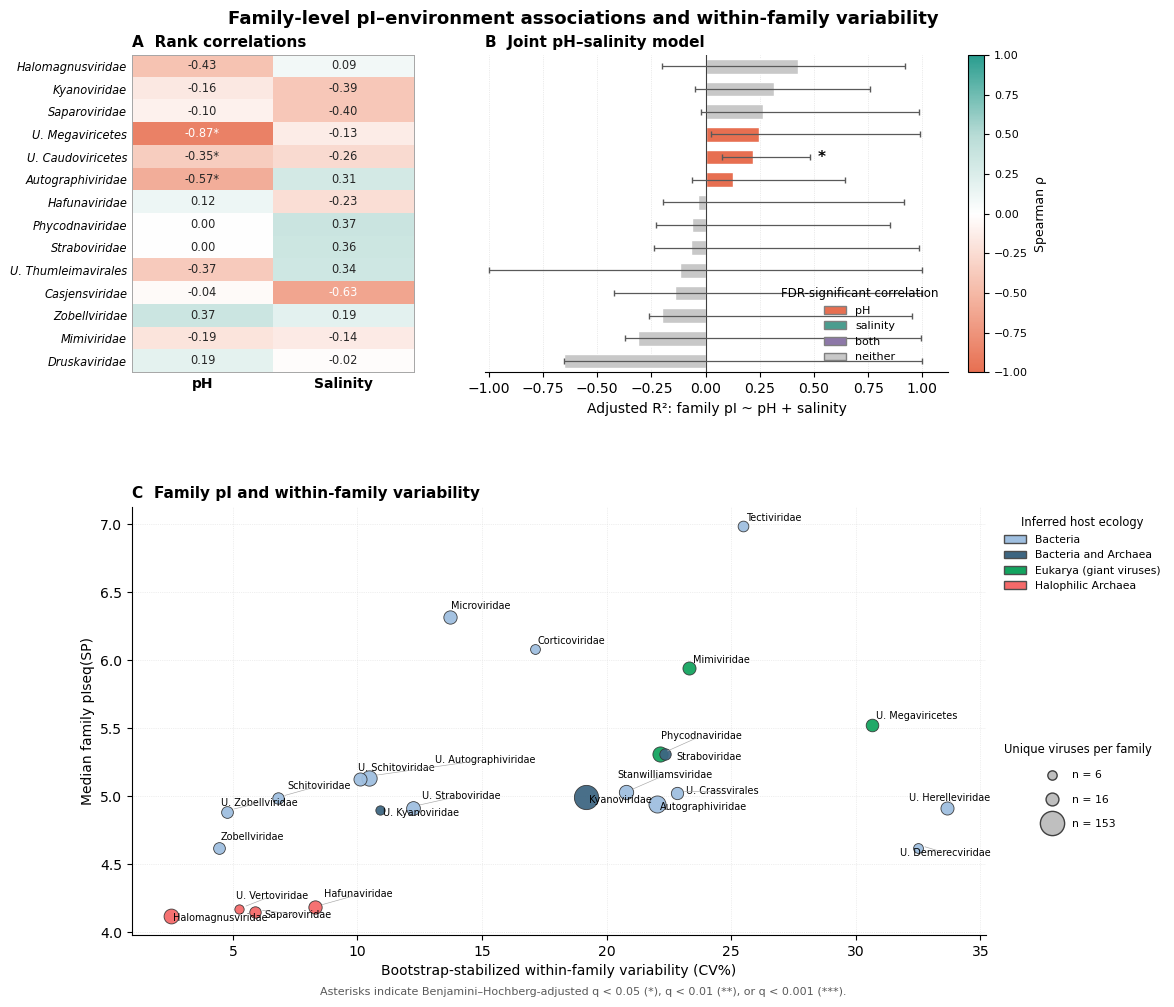

Saved:
/Users/skoog/Desktop/Revisions/Figure_4_family_environment_variability.png
/Users/skoog/Desktop/Revisions/Figure_4_family_environment_variability.svg


In [6]:
# Figure 4

import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib import gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

try:
    from adjustText import adjust_text
    HAVE_ADJUSTTEXT = True
except Exception:
    HAVE_ADJUSTTEXT = False

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none",
    "text.usetex": False,
})

HOST_COLORS = {
    "Bacteria": "#9FBFE0",
    "Bacteria and Archaea": "#3D6682",
    "Eukarya (giant viruses)": "#13A45F",
    "Eukarya (vertebrates/ invertebrates)": "#7F6B88",
    "Eukaryota, Archaea, and Bacteria": "#FFE46F",
    "Halophilic Archaea": "#F56969",
    "Other Archaea": "#09B0B2",
    "Virophage (GV-infected cells)": "#FD7C08",
    "Eukarya (Plants)": "#6050AF",
    "Unknown/Other": "#BDBDBD",
}

DRIVER_COLORS = {
    "pH": "#E76F51",
    "Salinity": "#4A9D8F",
    "Both": "#8D78A8",
    "Neither": "#C8C8C8",
}

RHO_CMAP = LinearSegmentedColormap.from_list(
    "rho_diverging",
    ["#E76F51", "#F5B9A6", "#FFFFFF", "#B8DCD6", "#2A9D8F"],
)


def _short_family(name):
    return str(name).replace("Unclassified ", "U. ")


def _sig_symbol(q):
    if pd.isna(q):
        return ""
    if q < 0.001:
        return "***"
    if q < 0.01:
        return "**"
    if q < 0.05:
        return "*"
    return ""


def plot_figure4(primary, plasticity, out_stem):
    fit = primary.sort_values("adjusted_R2", ascending=False).copy()
    order = fit["family"].tolist()
    fit = fit.set_index("family").loc[order]
    n_families = len(order)
    y = np.arange(n_families)

    fig = plt.figure(figsize=(12.2, 10.0))
    outer = gridspec.GridSpec(
        2, 2,
        figure=fig,
        height_ratios=[1.0, 1.35],
        width_ratios=[0.72, 1.28],
        hspace=0.36,
        wspace=0.18,
    )
    ax_a = fig.add_subplot(outer[0, 0])
    ax_b = fig.add_subplot(outer[0, 1])
    ax_c = fig.add_subplot(outer[1, :])

    # A
    heat = fit[["rho_pH", "rho_salinity"]].to_numpy(dtype=float)
    image = ax_a.imshow(heat, cmap=RHO_CMAP, vmin=-1, vmax=1, aspect="auto")
    for i, fam in enumerate(order):
        for j, (rho_col, q_col) in enumerate([
            ("rho_pH", "q_pH"),
            ("rho_salinity", "q_salinity"),
        ]):
            value = fit.loc[fam, rho_col]
            if np.isfinite(value):
                label = f"{value:.2f}{_sig_symbol(fit.loc[fam, q_col])}"
                color = "white" if abs(value) >= 0.58 else "0.15"
                ax_a.text(j, i, label, ha="center", va="center", fontsize=8.2, color=color)

    ax_a.set_xticks([0, 1])
    ax_a.set_xticklabels(["pH", "Salinity"], fontweight="bold")
    ax_a.set_yticks(y)
    ax_a.set_yticklabels([_short_family(f) for f in order], fontsize=8.2, fontstyle="italic")
    ax_a.set_ylim(n_families - 0.5, -0.5)
    ax_a.tick_params(length=0)
    ax_a.set_title("A  Rank correlations", loc="left", fontweight="bold", fontsize=11)
    for spine in ax_a.spines.values():
        spine.set_color("0.65")
        spine.set_linewidth(0.7)

    # B
    values = fit["adjusted_R2"].to_numpy(dtype=float)
    lows = fit["adjusted_R2_CI_low"].to_numpy(dtype=float)
    highs = fit["adjusted_R2_CI_high"].to_numpy(dtype=float)
    bar_colors = [DRIVER_COLORS.get(fit.loc[f, "significant_correlate"], "#C8C8C8") for f in order]

    ax_b.barh(y, values, color=bar_colors, edgecolor="white", height=0.66, zorder=2)
    for i, fam in enumerate(order):
        if np.isfinite(lows[i]) and np.isfinite(highs[i]):
            lower_error = max(values[i] - max(lows[i], -1.0), 0)
            upper_error = max(min(highs[i], 1.0) - values[i], 0)
            ax_b.errorbar(
                values[i], i,
                xerr=np.array([[lower_error], [upper_error]]),
                fmt="none", ecolor="0.35", elinewidth=0.9, capsize=2.5, zorder=4,
            )
        symbol = _sig_symbol(fit.loc[fam, "q_model"])
        if symbol:
            x_text = min(highs[i], 1.0) + 0.035 if np.isfinite(highs[i]) else values[i] + 0.035
            ax_b.text(x_text, i, symbol, va="center", fontsize=11, fontweight="bold")

    ax_b.axvline(0, color="0.25", lw=0.8)
    ax_b.set_yticks(y)
    ax_b.set_yticklabels([])
    ax_b.set_ylim(n_families - 0.5, -0.5)
    ax_b.set_xlim(-1.02, 1.12)
    ax_b.set_xlabel("Adjusted R²: family pI ~ pH + salinity")
    ax_b.set_title("B  Joint pH–salinity model", loc="left", fontweight="bold", fontsize=11)
    ax_b.grid(axis="x", ls=":", lw=0.5, color="0.85")
    ax_b.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        ax_b.spines[spine].set_visible(False)
    ax_b.tick_params(axis="y", length=0)

    colorbar = fig.colorbar(image, ax=ax_b, fraction=0.035, pad=0.04)
    colorbar.set_label("Spearman ρ", fontsize=9)
    colorbar.ax.tick_params(labelsize=8)

    driver_handles = [
        Patch(facecolor=DRIVER_COLORS[key], edgecolor="0.5", label=label)
        for key, label in [
            ("pH", "pH"),
            ("Salinity", "salinity"),
            ("Both", "both"),
            ("Neither", "neither"),
        ]
    ]
    ax_b.legend(
        handles=driver_handles,
        title="FDR-significant correlation",
        loc="lower right",
        frameon=False,
        fontsize=8,
        title_fontsize=8.5,
    )

    # C
    plot_data = plasticity.copy()
    n_min = int(plot_data["n_unique_genomes"].min())
    n_max = int(plot_data["n_unique_genomes"].max())

    def point_size(n):
        if n_max <= n_min:
            return 100
        scaled = (np.sqrt(n) - np.sqrt(n_min)) / (np.sqrt(n_max) - np.sqrt(n_min))
        return 45 + 260 * scaled

    ax_c.grid(ls=":", lw=0.5, color="0.88")
    ax_c.set_axisbelow(True)
    text_objects = []

    for _, row in plot_data.iterrows():
        color = HOST_COLORS.get(row["host_ecology"], "#BDBDBD")
        ax_c.scatter(
            row["CV_bootstrap"], row["median_pI"],
            s=point_size(row["n_unique_genomes"]),
            color=color, edgecolor="0.2", linewidth=0.6, alpha=0.94, zorder=3,
        )
        text_objects.append(
            ax_c.text(
                row["CV_bootstrap"] + 0.18,
                row["median_pI"] + 0.015,
                _short_family(row["family"]),
                fontsize=7.0,
            )
        )

    if HAVE_ADJUSTTEXT:
        adjust_text(
            text_objects,
            ax=ax_c,
            arrowprops=dict(arrowstyle="-", color="0.65", lw=0.45),
            expand_points=(1.2, 1.35),
            force_text=(0.25, 0.35),
        )

    ax_c.set_xlabel("Bootstrap-stabilized within-family variability (CV%)")
    ax_c.set_ylabel("Median family pIseq(SP)")
    ax_c.set_title("C  Family pI and within-family variability", loc="left", fontweight="bold", fontsize=11)
    for spine in ["top", "right"]:
        ax_c.spines[spine].set_visible(False)

    present_hosts = [h for h in HOST_COLORS if h in set(plot_data["host_ecology"])]
    host_legend = ax_c.legend(
        handles=[Patch(facecolor=HOST_COLORS[h], edgecolor="0.3", label=h) for h in present_hosts],
        title="Inferred host ecology",
        bbox_to_anchor=(1.01, 1.0),
        loc="upper left",
        frameon=False,
        fontsize=7.8,
        title_fontsize=8.3,
    )
    ax_c.add_artist(host_legend)

    size_refs = sorted(set([n_min, int(np.median(plot_data["n_unique_genomes"])), n_max]))
    ax_c.legend(
        handles=[
            Line2D(
                [], [], marker="o", linestyle="None",
                markersize=np.sqrt(point_size(n)),
                markerfacecolor="0.75", markeredgecolor="0.25",
                label=f"n = {n}",
            )
            for n in size_refs
        ],
        title="Unique viruses per family",
        bbox_to_anchor=(1.01, 0.47),
        loc="upper left",
        frameon=False,
        fontsize=7.8,
        title_fontsize=8.3,
        labelspacing=1.3,
    )

    fig.suptitle(
        "Family-level pI–environment associations and within-family variability",
        fontsize=13,
        fontweight="bold",
        y=0.995,
    )
    fig.text(
        0.5, 0.01,
        "Asterisks indicate Benjamini–Hochberg-adjusted q < 0.05 (*), q < 0.01 (**), or q < 0.001 (***).",
        ha="center", fontsize=8, color="0.35",
    )
    fig.subplots_adjust(left=0.13, right=0.83, bottom=0.07, top=0.95)

    png = out_stem + ".png"
    svg = out_stem + ".svg"
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(svg, bbox_inches="tight")
    plt.show()
    print("Saved:")
    print(png)
    print(svg)


plot_figure4(
    family_models_primary,
    family_plasticity_plot,
    os.path.join(OUTDIR, "Figure_4_family_environment_variability"),
)


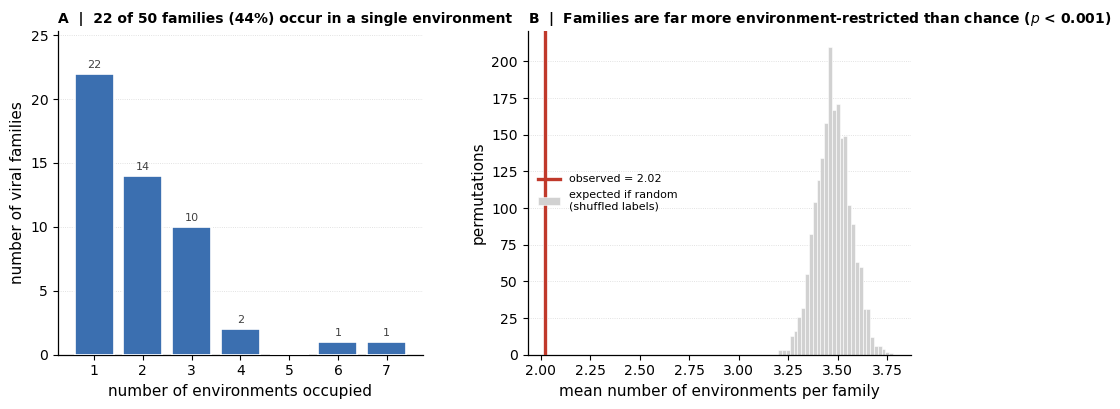

50 families | 1 env: 22 (44%) | <=2: 36 | median dominant-env fraction 0.83 | permutation p=0.0000


In [7]:
# families are environment-restricted
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

_src = host_df_all if "host_df_all" in dir() else df_ALL
d = _src.copy(); d["family"] = d["family"].astype(str).str.strip()
d = d[d["Environment_Bin"].astype(str) != "Unclassified"]
idc = "contig_id" if "contig_id" in d.columns else d.columns[0]
envs = sorted(d["Environment_Bin"].astype(str).unique())

M = d.pivot_table(index="family", columns="Environment_Bin", values=idc, aggfunc="count", fill_value=0).reindex(columns=envs, fill_value=0)
n_env = (M > 0).sum(axis=1); tot = M.sum(axis=1); dom_frac = M.div(tot, axis=0).max(axis=1)

fam_labels = d["family"].values; env_labels = d["Environment_Bin"].astype(str).values
rng = np.random.default_rng(0); obs = n_env.mean(); perm = []
for _ in range(2000):
    mm = pd.crosstab(fam_labels, rng.permutation(env_labels)); perm.append((mm > 0).sum(axis=1).mean())
perm = np.array(perm); p_perm = (perm <= obs).mean()

with plt.rc_context({"font.family":"DejaVu Sans","font.size":10,"axes.titlesize":11,"axes.labelsize":11,"axes.linewidth":0.9}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios":[1, 1.05], "wspace":0.28})
    vc = n_env.value_counts().reindex(range(1, len(envs)+1), fill_value=0)
    ax1.bar(vc.index, vc.values, color="#3B6FB0", edgecolor="white", lw=1.2, width=0.8, zorder=3)
    for x, v in zip(vc.index, vc.values):
        if v > 0: ax1.text(x, v+0.3, str(int(v)), ha="center", va="bottom", fontsize=8, color="0.25")
    ax1.set_xlabel("number of environments occupied"); ax1.set_ylabel("number of viral families")
    ax1.set_xticks(range(1, len(envs)+1)); ax1.set_ylim(0, vc.max()*1.15)
    ax1.set_axisbelow(True); ax1.grid(axis="y", ls=":", lw=0.6, color="0.85")
    ax1.set_title(f"A  |  {int((n_env==1).sum())} of {len(M)} families ({100*(n_env==1).mean():.0f}%) occur in a single environment", fontsize=10, loc="left", fontweight="bold")
    for s in ("top","right"): ax1.spines[s].set_visible(False)

    ax2.hist(perm, bins=30, color="0.82", edgecolor="white", lw=0.4, zorder=2, label="expected if random\n(shuffled labels)")
    ax2.axvline(obs, color="#C0392B", lw=2.4, zorder=4, label=f"observed = {obs:.2f}")
    ax2.set_xlabel("mean number of environments per family"); ax2.set_ylabel("permutations")
    ax2.set_axisbelow(True); ax2.grid(axis="y", ls=":", lw=0.6, color="0.85")
    ax2.set_title("B  |  Families are far more environment-restricted than chance ($p$ < 0.001)", fontsize=10, loc="left", fontweight="bold")
    ax2.legend(fontsize=8, frameon=False, loc="center left")
    for s in ("top","right"): ax2.spines[s].set_visible(False)

    OUTDIR = "/Users/skoog/Desktop/Revisions/"
    fig.savefig(OUTDIR + "family_environment_specificity.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTDIR + "family_environment_specificity.svg", bbox_inches="tight")
    plt.show()

M.assign(n_envs=n_env, dom_frac=dom_frac.round(2)).to_csv(OUTDIR + "family_environment_specificity.csv")
print(f"{len(M)} families | 1 env: {int((n_env==1).sum())} ({100*(n_env==1).mean():.0f}%) | <=2: {int((n_env<=2).sum())} | "
      f"median dominant-env fraction {dom_frac.median():.2f} | permutation p={p_perm:.4f}")

In [8]:
# helpers
import numpy as np, pandas as pd
# archaea split into halophilic vs other only
def _host_group_iphop(r):
    """iPHoP host domain/phylum -> broad group. Splits archaea into Halophilic vs Other only."""
    if not r.get("has_iphop", False): return np.nan
    dom, phy = str(r.get("host_domain")), str(r.get("host_phylum"))
    if dom == "Archaea":
        return "Halophilic Archaea" if phy == "Halobacteriota" else "Other Archaea"
    if dom == "Bacteria":               return "Bacteria"
    if dom in ("Eukaryota", "Eukarya"): return "Eukarya"
    return np.nan

# iPHoP host overrides the family default
def _final_host_group(r):
    """Authoritative host group for a virus. iPHoP-first, else viral-family-inferred ecology."""
    if r.get("has_iphop", False):
        g = _host_group_iphop(r)
        return g if pd.notna(g) else "Unknown/Other"
    eco = r.get("Host_ecology")
    if pd.notna(eco) and str(eco) not in ("Unknown/Other", "nan", ""):
        return str(eco)
    return "Unknown/Other"

def _grp_all_hosts(r):
    """3-focal-group collapse (Bacteria / Halophilic Archaea / Other Archaea) for the by-host figures.
       iPHoP-first; inferred archaea split by ecology; everything else -> NaN (excluded)."""
    if r.get("has_iphop", False):
        g = _host_group_iphop(r)
        return {"Thermophilic Archaea": "Other Archaea"}.get(g, g)
    hg = str(r.get("Host_group")); eco = str(r.get("Host_ecology"))
    if hg == "Archaea":
        return "Halophilic Archaea" if eco == "Halophilic Archaea" else "Other Archaea"
    if hg == "Bacteria":
        return "Bacteria"
    if hg.startswith("Eukary"):
        return "Eukarya"
    return np.nan


## Host integration

### iPHoP host assignment

In [9]:
# iPHoP host merge, per lake
# WATL merges on vOTU id
import re, glob, os, difflib, numpy as np, pandas as pd

HOST_DIR      = r"/Users/skoog/Desktop/Revisions/"
HOST_FILENAME = "Host_prediction_to_genus_m90.csv"
HOST_RANK     = "phylum"
RANKS         = ["domain","phylum","class","order","family","genus","species"]
PICKLE        = os.path.join(HOST_DIR, "filtered_All_envs_df_with_metadata.pkl")
FILE2LAKE_OVERRIDE = {}     # override lake per folder if needed

def _normid(x):
    s = pd.Series(x, dtype="object").astype(str).str.strip()
    s = s.str.replace(r"\.faa$", "", regex=True)
    s = s.str.replace("|", "_", regex=False)
    s = s.str.replace(r"_provirus_\d+_\d+$", "", regex=True)  # strip provirus suffix
    return s

# reference frame for file -> lake
_ref = pd.read_pickle(PICKLE).copy()
if "Average_pI" not in _ref.columns: _ref["Average_pI"] = _ref["Median_pI"]
_rf  = _ref["family"].astype(str).str.strip()
_ref = _ref[~(_rf.isin(DROP_FAMILIES) | _rf.str.replace(r"^Unclassified\s+","",regex=True).isin(DROP_FAMILIES))]
_ref = _ref[_ref["Environment_Bin"].notna()].copy()
_ref["_vid"]  = _normid(_ref["contig_id"])
_vid_lakes    = _ref.groupby("_vid")["name_full"].agg(lambda s: sorted(set(s)))
_env_of_lake  = _ref.drop_duplicates("name_full").set_index("name_full")["Environment_Bin"].to_dict()
_lakes_by_env = {}
for _lk, _e in _env_of_lake.items(): _lakes_by_env.setdefault(_e, []).append(_lk)
def _cleanfolder(x):
    x = re.sub(r"_split_by_contig.*$", "", str(x).lower())
    return re.sub(r"\s+", " ", re.sub(r"[_\-]", " ", x)).strip()

_hostcols = [f"host_{r}" for r in RANKS]

def _load_iphop(path):
    h = pd.read_csv(path)
    tc = "Host taxonomy" if "Host taxonomy" in h.columns else "Host genus"
    conf = "Confidence score" if "Confidence score" in h.columns else ("Confidence" if "Confidence" in h.columns else None)
    tax = h[tc].str.split(";", expand=True)
    tax = tax.iloc[:, :len(RANKS)]
    tax.columns = RANKS[:tax.shape[1]]
    for c in tax.columns:
        tax[c] = tax[c].astype(str).str.replace(r"^[a-z]__", "", regex=True).str.strip().replace({"": np.nan, "nan": np.nan})
    tax = tax.add_prefix("host_")
    for col in _hostcols:
        if col not in tax.columns: tax[col] = np.nan
    tax = tax[_hostcols]
    hh = pd.concat([h[["Virus"]].copy(), tax], axis=1)
    hh["Confidence score"] = h[conf] if conf else np.nan
    hh["_vid"] = _normid(hh["Virus"]); hh["_host_file"] = os.path.relpath(path, HOST_DIR)
    return hh.sort_values("Confidence score", ascending=False).drop_duplicates("_vid")

host_paths = sorted(glob.glob(os.path.join(HOST_DIR, "**", HOST_FILENAME), recursive=True))
if not host_paths:
    raise FileNotFoundError(f"No '{HOST_FILENAME}' found under {HOST_DIR} -- check HOST_DIR.")

_votu, _comp, _report = [], [], []
for p in host_paths:
    folder = os.path.relpath(p, HOST_DIR).split(os.sep)[0]
    hh = _load_iphop(p)
    matched = hh[hh["_vid"].isin(_vid_lakes.index)]
    if matched.empty:
        _report.append(dict(folder=folder[:40], kind="NO MATCH", target="-", matched=0, n_ids=len(hh))); continue
    is_votu = matched["_vid"].str.startswith("WATLvirus").mean() > 0.5
    if is_votu:
        _votu.append(matched)
        _report.append(dict(folder=folder[:40], kind="vOTU (WATL)", target="(all WATL lakes)",
                            matched=len(matched), n_ids=len(hh)))
    else:
        env_counts = {}
        for v in matched["_vid"]:
            for lk in _vid_lakes.loc[v]:
                e = _env_of_lake.get(lk); env_counts[e] = env_counts.get(e, 0) + 1
        best_env = FILE2LAKE_OVERRIDE.get(folder) or max(env_counts, key=env_counts.get)
        m2 = matched.copy(); m2["Environment_Bin"] = best_env
        _comp.append(m2)
        _report.append(dict(folder=folder[:40], kind="env-scoped", target=best_env,
                            matched=len(matched), n_ids=len(hh)))

print("iPHoP file classification (VERIFY the targets):")
print(pd.DataFrame(_report).to_string(index=False))

comp_hosts = (pd.concat(_comp, ignore_index=True).sort_values("Confidence score", ascending=False)
                .drop_duplicates(["Environment_Bin","_vid"])) if _comp else \
             pd.DataFrame(columns=["Environment_Bin","_vid","Confidence score","_host_file"]+_hostcols)
votu_hosts = (pd.concat(_votu, ignore_index=True).sort_values("Confidence score", ascending=False)
                .drop_duplicates("_vid")) if _votu else \
             pd.DataFrame(columns=["_vid","Confidence score","_host_file"]+_hostcols)
hosts = pd.concat([comp_hosts, votu_hosts], ignore_index=True)

def merge_iphop(frame):
    """Namespace-aware iPHoP merge onto any frame that has (name_full, contig_id)."""
    f = frame.copy()
    f["_vid"] = _normid(f["contig_id"])
    f = f.drop(columns=[c for c in ["Virus","Confidence score","_host_file","has_iphop"]+_hostcols
                        if c in f.columns], errors="ignore")
    m = f.merge(comp_hosts[["Environment_Bin","_vid","Confidence score","_host_file"]+_hostcols],
                on=["Environment_Bin","_vid"], how="left")
    m = m.merge(votu_hosts[["_vid","Confidence score","_host_file"]+_hostcols],
                on="_vid", how="left", suffixes=("","_votu"))
    for c in _hostcols + ["Confidence score","_host_file"]:
        m[c] = m[c].fillna(m[f"{c}_votu"])
    m = m.drop(columns=[f"{c}_votu" for c in _hostcols + ["Confidence score","_host_file"]])
    m["has_iphop"] = m["host_domain"].notna()
    return m

host_df = merge_iphop(filtered_All_envs_df_with_metadata)
host_df["Host_ecology"] = host_df["family"].astype(str).str.strip().map(host_ecology)
host_df["Host_source"]  = np.where(host_df["has_iphop"], "iPHoP",
                          np.where(host_df["Host_ecology"].notna(), "Taxonomy-inferred", "Unknown"))
host_df["Host_best"]    = np.where(host_df["has_iphop"], host_df[f"host_{HOST_RANK}"], host_df["Host_ecology"])
host_df["Host_best"]    = pd.Series(host_df["Host_best"], index=host_df.index, dtype=object).fillna("Unknown/Other")

N = len(host_df); n_ip = int(host_df["has_iphop"].sum()); n_tax = int((host_df["Host_source"]=="Taxonomy-inferred").sum())
print("\nHOST-PREDICTION COVERAGE (current scope)")
print(f"  iPHoP-predicted   : {n_ip:,} / {N:,}  ({100*n_ip/N:.1f}%)")
print(f"  taxonomy-inferred : {n_tax:,} / {N:,}  ({100*n_tax/N:.1f}%)")
print(f"  combined coverage : {100*(n_ip+n_tax)/N:.1f}%   (Unknown {100*(N-n_ip-n_tax)/N:.1f}%)")
cov = host_df.groupby("Environment_Bin").agg(n=("has_iphop","size"), iPHoP=("has_iphop","sum"),
        tax=("Host_source", lambda s:(s=="Taxonomy-inferred").sum()))
cov["iPHoP_%"] = (100*cov["iPHoP"]/cov["n"]).round(1)
print("\nper environment:\n", cov.to_string())

iPHoP file classification (VERIFY the targets):
                                  folder        kind                     target  matched  n_ids
Cock_soda_lake_split_by_contig_faa_updat  env-scoped           Saline soda lake      171    513
Cueva_de_la_mora_lake_11m_split_by_conti  env-scoped                Acidic lake        1      4
Cueva_de_la_mora_lake_35m_split_by_conti    NO MATCH                          -        0      2
Cueva_de_la_mora_lake_3m_split_by_contig  env-scoped                Acidic lake        1      2
Lake_Bitter_1_split_by_contig_faa_update  env-scoped      Hypersaline soda lake        1      5
Lake_Soyang_viruses_split_by_contig_faa_  env-scoped                 Freshwater       45    198
Lake_Victoria_split_by_contig_faa_update  env-scoped                 Freshwater        3     11
Lake_tanatar_TC_split_by_contig_faa_upda  env-scoped      Hypersaline soda lake        2     13
Lost_city_split_by_contig_faa_updated_re  env-scoped Alkaline hydrothermal vent       77

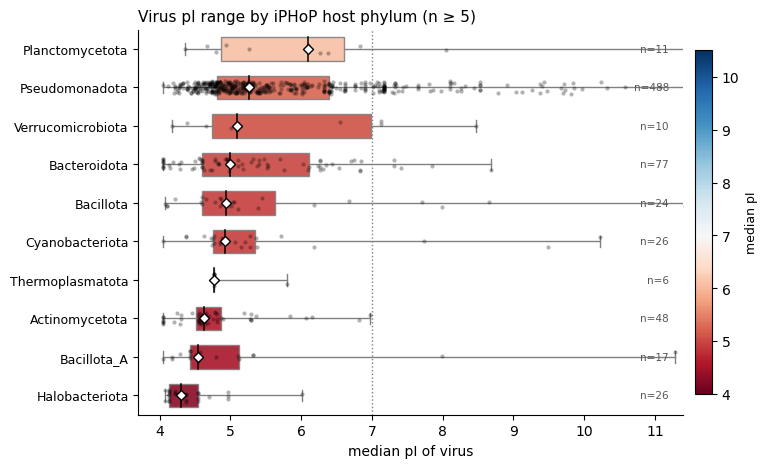

In [10]:
# per-host pI range
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable

MIN_N, CENTER, ACIDIC_COLOR = 5, 7.0, "red"
PICOL = "Median_pI"
sub = host_df[host_df["has_iphop"]].dropna(subset=[PICOL, f"host_{HOST_RANK}"]).copy()
sub[PICOL] = pd.to_numeric(sub[PICOL], errors="coerce")

rows = []
for name, g in sub.groupby(f"host_{HOST_RANK}"):
    if len(g) < MIN_N: continue
    w = pd.to_numeric(g.get("rpkm", pd.Series(1.0, index=g.index)), errors="coerce").fillna(1.0).values
    rows.append((name, g[PICOL].values, float(np.median(g[PICOL].values)), len(g)))
rows.sort(key=lambda t: t[2])
lo = np.floor(np.nanpercentile(sub[PICOL], 1)*2)/2; hi = np.ceil(np.nanpercentile(sub[PICOL], 99)*2)/2
norm = TwoSlopeNorm(vcenter=CENTER, vmin=min(lo, CENTER-1e-6), vmax=max(hi, CENTER+1e-6))
cmap = plt.get_cmap("RdBu" if ACIDIC_COLOR == "red" else "RdBu_r")
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(7.4, 0.36*len(rows) + 1.4))
bp = ax.boxplot([r[1] for r in rows], positions=np.arange(len(rows)), vert=False, widths=0.62,
                patch_artist=True, showfliers=False, whis=(0,100),
                medianprops=dict(color="black", lw=1.1), whiskerprops=dict(color="grey"),
                capprops=dict(color="grey"))
for patch, r in zip(bp["boxes"], rows): patch.set_facecolor(cmap(norm(r[2]))); patch.set_alpha(0.9); patch.set_edgecolor("grey")
for i, r in enumerate(rows):
    ax.scatter(r[1], i + rng.uniform(-0.16, 0.16, len(r[1])), s=9, color="black", alpha=0.3, zorder=3, linewidths=0)
    ax.text(hi+0.7, i, f"n={r[3]}", va="center", ha="right", fontsize=7.5, color="#555")
ax.scatter([r[2] for r in rows], np.arange(len(rows)), marker="D", s=26, color="white", edgecolor="black", zorder=4)
ax.axvline(CENTER, color="grey", ls=":", lw=1)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=9)
ax.set_xlim(lo-0.3, hi+0.9); ax.set_xlabel("median pI of virus")
ax.set_title(f"Virus pI range by iPHoP host {HOST_RANK} (n \u2265 {MIN_N})", fontsize=11, loc="left")
sm2 = ScalarMappable(norm=norm, cmap=cmap); sm2.set_array([])
cb = fig.colorbar(sm2, ax=ax, fraction=0.03, pad=0.02); cb.set_label("median pI", fontsize=9)
for s in ("top","right"): ax.spines[s].set_visible(False)
fig.savefig(r"/Users/skoog/Desktop/Revisions/host_pI_range_iphop.png", dpi=300, bbox_inches="tight")
plt.show()

### Host vs environment

In [11]:
# unclassified hosts, assigned from viral taxonomy
import re, numpy as np, pandas as pd

HOST_BACKOFF = [
    ("Halophilic Archaea", ["Thumleimavirales","Halopanivirales","Pleolipoviridae","Sphaerolipoviridae",
        "Simuloviridae","Haloferuviridae","Graaviviridae","Vertoviridae","Hafunaviridae","Halomagnusviridae",
        "Druskaviridae","Soleiviridae","Madisaviridae","Saparoviridae","Suolaviridae","Verdandiviridae",
        "Skuldviridae","Shortaselviridae","Halspiviridae","Halobacteri"]),
    ("Thermophilic Archaea", ["Rudiviridae","Tristromaviridae","Fuselloviridae","Lipothrixviridae","Ligamenvirales",
        "Sulfolobales","Turriviridae","Portogloboviridae","Spiraviridae","Globuloviridae","Ampullaviridae",
        "Bicaudaviridae","Clavaviridae","Guttaviridae"]),
    ("Methanogen Archaea", ["Leisingerviridae","Anaerodiviridae","Methanobacteri"]),
    ("Eukarya (giant viruses)", ["Nucleocytoviricota","Megaviricetes","Imitervirales","Algavirales","Pimascovirales",
        "Mimiviridae","Phycodnaviridae","Marseilleviridae","Pandoravir","Bamfordvirae","Allomimiviridae",
        "Schizomimiviridae","Mesomimiviridae","Poxviridae","Ascoviridae","Iridoviridae"]),
    ("Virophage (GV-infected cells)", ["Lavidaviridae","Maveriviricetes","Priklausovirales","virophage"]),
    ("Eukarya (vertebrates/ invertebrates)", ["Cressdnaviricota","Circoviridae","Smacoviridae","Parvoviridae",
        "Herpesvir","Adintoviridae","Naldaviricetes","Genomoviridae","Baculoviridae","Papillomavir","Polyomavir"]),
    ("Eukarya (plants/algae)", ["Tombusviridae","Virgaviridae","Bromoviridae","Potyviridae"]),
    ("Bacteria", ["Caudoviricetes","Crassvirales","Tubulavirales","Petitvirales","Vinavirales","Peduoviridae",
        "Autographiviridae","Straboviridae","Kyanoviridae","Zobellviridae","Schitoviridae","Rountreeviridae",
        "Casjensviridae","Chaseviridae","Guelinviridae","Demerecviridae","Drexlerviridae","Herelleviridae",
        "Mesyanzhinovviridae","Ackermannviridae","Inoviridae","Microviridae","Corticoviridae","Tectiviridae","phage"]),
]
HALO_RE = re.compile(r"\bhalo", re.I)
DEFAULT_BACTERIA_RE = re.compile(r"(viridae|virales|viricetes)\b", re.I)

def _assign(fam):
    s = str(fam)
    for cat, keys in HOST_BACKOFF:
        if any(k.lower() in s.lower() for k in keys): return cat, "keyword"
    if HALO_RE.search(s):             return "Halophilic Archaea", "halo-name heuristic"
    if DEFAULT_BACTERIA_RE.search(s): return "Bacteria", "default (Caudoviricetes)"
    return "Unknown/Other", "unassigned"

fam = host_df["family"].astype(str).str.strip()
host_df["Host_ecology"] = fam.map(host_ecology)
_res = fam.map(_assign)
host_df["_bo_cat"] = _res.map(lambda t: t[0]); host_df["_bo_via"] = _res.map(lambda t: t[1])
host_df["Host_broad"] = host_df["Host_ecology"].fillna(host_df["_bo_cat"])
host_df["Host_broad_source"] = np.where(host_df["Host_ecology"].notna(), "family map",
                                np.where(host_df["Host_broad"].eq("Unknown/Other"), "unassigned", host_df["_bo_via"]))
host_df.drop(columns=["_bo_cat","_bo_via"], inplace=True)

N = len(host_df)
print("BROAD-HOST ASSIGNMENT (viral-taxonomy based, ALL viruses):")
for lab in ["family map","keyword","halo-name heuristic","default (Caudoviricetes)","unassigned"]:
    n = int((host_df["Host_broad_source"] == lab).sum()); print(f"  {lab:<26}: {n:,} ({100*n/N:.1f}%)")
print(f"  --> total assigned: {100*(host_df['Host_broad']!='Unknown/Other').mean():.1f}%\n")

dflt = host_df.loc[host_df["Host_broad_source"]=="default (Caudoviricetes)","family"].astype(str).value_counts()
if len(dflt):
    print("families assigned Bacteria by DEFAULT rule (audit these):")
    print(dflt.to_string(), "\n")

und = host_df[host_df["Host_broad"]=="Unknown/Other"]["family"].astype(str).value_counts()
print(f">>> STILL UNCLASSIFIED: {int(und.sum())} viruses across {len(und)} family labels (full list):")
print(und.to_string() if len(und) else "   none")
und.rename_axis("family").reset_index(name="n_viruses").to_csv(r"/Users/skoog/Desktop/Revisions/unclassified_families.csv", index=False)

if "host_phylum" in host_df.columns:
    _mi = int((host_df["has_iphop"] & host_df["host_phylum"].isna()).sum())
    print(f"\nsanity: iPHoP viruses missing host_phylum = {_mi} (0 => fine H1-H4 analysis loses none)")

BROAD-HOST ASSIGNMENT (viral-taxonomy based, ALL viruses):
  family map                : 8,980 (100.0%)
  keyword                   : 0 (0.0%)
  halo-name heuristic       : 0 (0.0%)
  default (Caudoviricetes)  : 0 (0.0%)
  unassigned                : 0 (0.0%)
  --> total assigned: 100.0%

>>> STILL UNCLASSIFIED: 0 viruses across 0 family labels (full list):
   none

sanity: iPHoP viruses missing host_phylum = 0 (0 => fine H1-H4 analysis loses none)


## Master figure

## pI vs environment by host group

In [12]:
# host_df_all (all environments)
import numpy as np, pandas as pd, re
OUTDIR = "/Users/skoog/Desktop/Revisions/"

_all = pd.read_pickle(PICKLE).copy()
if "Average_pI" not in _all.columns: _all["Average_pI"] = _all["Median_pI"]

# same cleaning, no WATL restriction
_UNINF = {"Unclassified","Unknown","nan","NaN","NA",""}
_f = _all["family"].astype(str).str.strip()
_all = _all[~(_f.isin(DROP_FAMILIES) | _f.str.replace(r"^Unclassified\s+","",regex=True).isin(DROP_FAMILIES))]
_env = _all["Environment_Bin"].astype(str).str.strip()
_all = _all[_all["Environment_Bin"].notna() & ~_env.isin(_UNINF)]
_all = _all[~_all["family"].astype(str).str.strip().isin(_UNINF)].reset_index(drop=True)

# iPHoP merge
host_df_all = merge_iphop(_all)

# Host_broad
HOST_BACKOFF = [
 ("Halophilic Archaea",["Thumleimavirales","Halopanivirales","Pleolipoviridae","Sphaerolipoviridae","Simuloviridae","Haloferuviridae","Graaviviridae","Vertoviridae","Hafunaviridae","Halomagnusviridae","Druskaviridae","Soleiviridae","Madisaviridae","Saparoviridae","Suolaviridae","Verdandiviridae","Skuldviridae","Shortaselviridae","Halspiviridae","Halobacteri"]),
 ("Thermophilic Archaea",["Rudiviridae","Tristromaviridae","Fuselloviridae","Lipothrixviridae","Ligamenvirales","Sulfolobales","Turriviridae","Portogloboviridae","Spiraviridae","Globuloviridae","Ampullaviridae","Bicaudaviridae","Clavaviridae","Guttaviridae"]),
 ("Eukarya (giant viruses)",["Nucleocytoviricota","Megaviricetes","Imitervirales","Algavirales","Pimascovirales","Mimiviridae","Phycodnaviridae","Marseilleviridae","Allomimiviridae","Schizomimiviridae","Iridoviridae"]),
 ("Virophage (GV-infected cells)",["Lavidaviridae","Maveriviricetes","virophage"]),
 ("Eukarya (vertebrates/ invertebrates)",["Cressdnaviricota","Circoviridae","Smacoviridae","Parvoviridae","Herpesvir","Genomoviridae","Baculoviridae"]),
 ("Bacteria",["Caudoviricetes","Crassvirales","Tubulavirales","Petitvirales","Vinavirales","Peduoviridae","Autographiviridae","Straboviridae","Kyanoviridae","Zobellviridae","Schitoviridae","Casjensviridae","Chaseviridae","Demerecviridae","Drexlerviridae","Herelleviridae","Mesyanzhinovviridae","Ackermannviridae","Inoviridae","Microviridae","Corticoviridae","Tectiviridae","phage"]),
]
_HALO = re.compile(r"\bhalo", re.I); _DEF = re.compile(r"(viridae|virales|viricetes)\b", re.I)
def _assign(fam):
    s = str(fam)
    for cat, keys in HOST_BACKOFF:
        if any(k.lower() in s.lower() for k in keys): return cat
    if _HALO.search(s): return "Halophilic Archaea"
    if _DEF.search(s):  return "Bacteria"
    return "Unknown/Other"
_famS = host_df_all["family"].astype(str).str.strip()
host_df_all["Host_broad"] = _famS.map(host_ecology)
_m = host_df_all["Host_broad"].isna()
host_df_all.loc[_m, "Host_broad"] = host_df_all.loc[_m, "family"].map(_assign)
host_df_all["Host_broad"] = host_df_all["Host_broad"].fillna("Unknown/Other")

print(f"ALL-ENV host_df_all: {len(host_df_all):,} viruses | {host_df_all['name_full'].nunique()} lakes | "
      f"{host_df_all['Environment_Bin'].nunique()} environments | iPHoP {host_df_all['has_iphop'].mean()*100:.1f}%")


ALL-ENV host_df_all: 8,980 viruses | 53 lakes | 7 environments | iPHoP 8.6%


In [13]:
# merged host grouping
def _harmonize(hb):
    hb = str(hb)
    if hb in ("Eukarya (giant viruses)","Eukarya (vertebrates/ invertebrates)",
              "Eukarya (plants/algae)","Virophage (GV-infected cells)"): return "Eukarya"
    if hb in ("Thermophilic Archaea","Methanogen Archaea"): return "Other Archaea"
    return hb

def _merged(r):
    if r.get("has_iphop", False):
        g = _host_group_iphop(r)
        return g if pd.notna(g) else _harmonize(r.get("Host_broad"))
    return _harmonize(r.get("Host_broad"))

host_df_all["Host_merged"] = host_df_all.apply(_merged, axis=1)
host_df_all.loc[host_df_all["Host_merged"].isna(), "Host_merged"] = "Unknown/Other"

_prov = pd.Series(np.where(host_df_all["has_iphop"], "iPHoP", "inferred")).value_counts()
print("merged-label provenance:", _prov.to_dict())
print("merged groups:", host_df_all.loc[host_df_all.Host_merged!="Unknown/Other","Host_merged"].value_counts().to_dict())

merged-label provenance: {'inferred': 8211, 'iPHoP': 769}
merged groups: {'Bacteria': 8547, 'Bacteria and Archaea': 178, 'Halophilic Archaea': 160, 'Eukarya': 82, 'Other Archaea': 13}


In [14]:
# Other Archaea composition
oa = host_df_all[host_df_all.apply(_host_group_iphop, axis=1) == "Other Archaea"]
print(f"'Other Archaea' (iPHoP): {len(oa)} viruses across "
      f"{oa['name_full'].nunique()} lakes, {oa['Environment_Bin'].nunique()} environments\n")
print("host phyla:")
print(oa["host_phylum"].value_counts().to_string())
print("\nby environment:")
print(oa["Environment_Bin"].value_counts().to_string())
print("\nby lake:")
print(oa["name_full"].value_counts().to_string())

'Other Archaea' (iPHoP): 13 viruses across 8 lakes, 5 environments

host phyla:
host_phylum
Thermoplasmatota     6
Nanoarchaeota        2
Methanobacteriota    2
Thermoproteota       2
Asgardarchaeota      1

by environment:
Environment_Bin
Alkaline-brine lakes (WATL)    5
Alkaline hydrothermal vent     4
Saline soda lake               2
Hypersaline soda lake          1
Freshwater                     1

by lake:
name_full
Lost City         4
Pink Lake         2
Cock Soda Lake    2
Balicup Lake      1
Lake Clifton      1
Pink Lake         1
Lake Tanatar-5    1
Malaren B         1


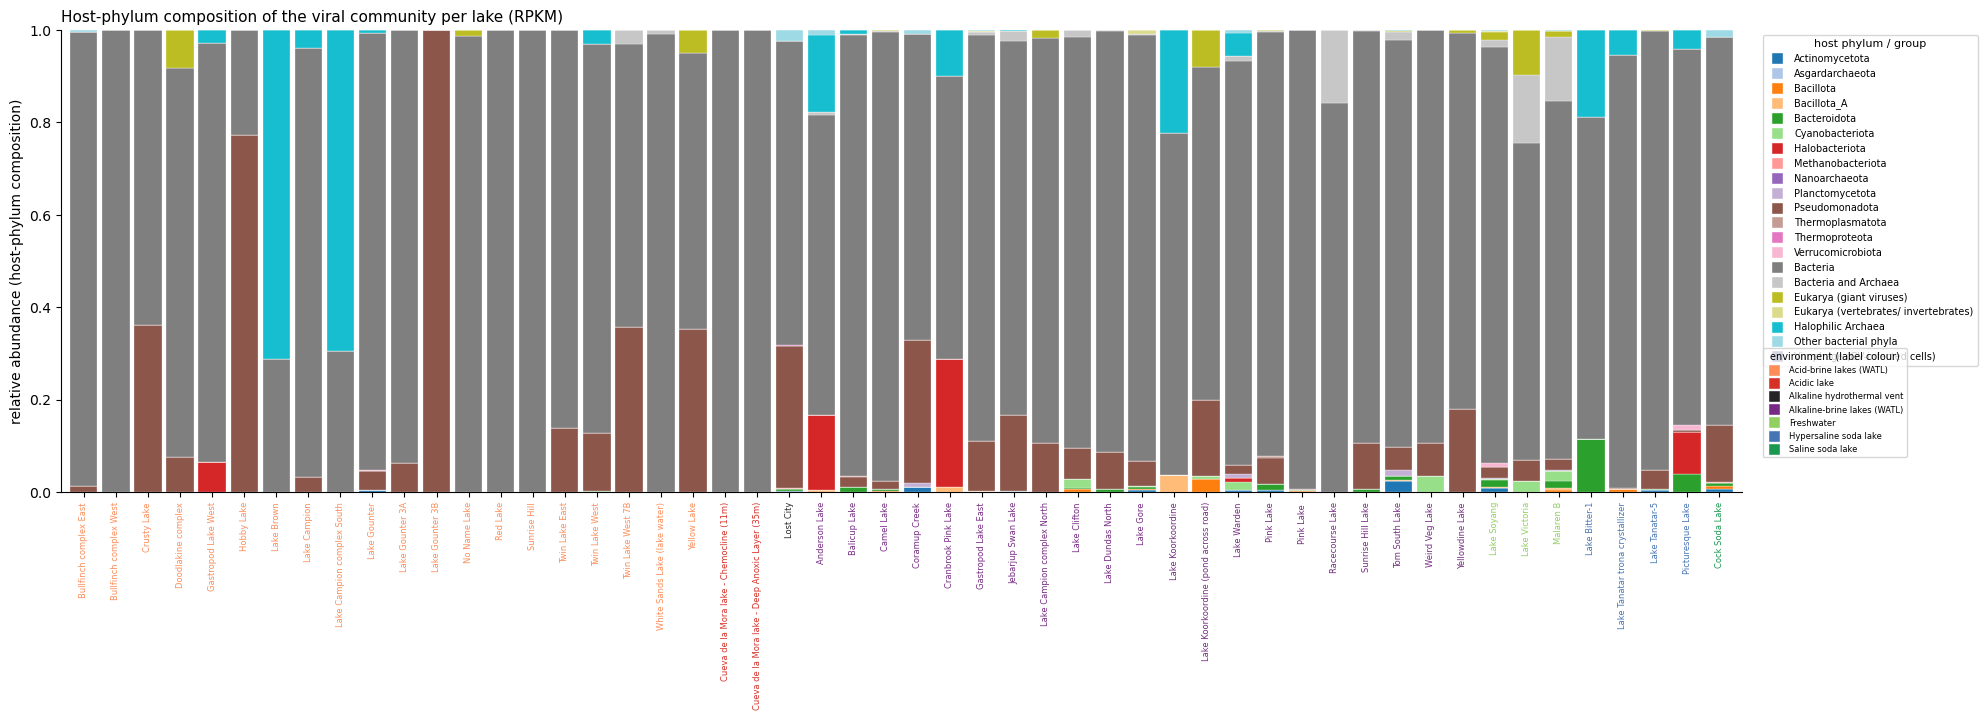

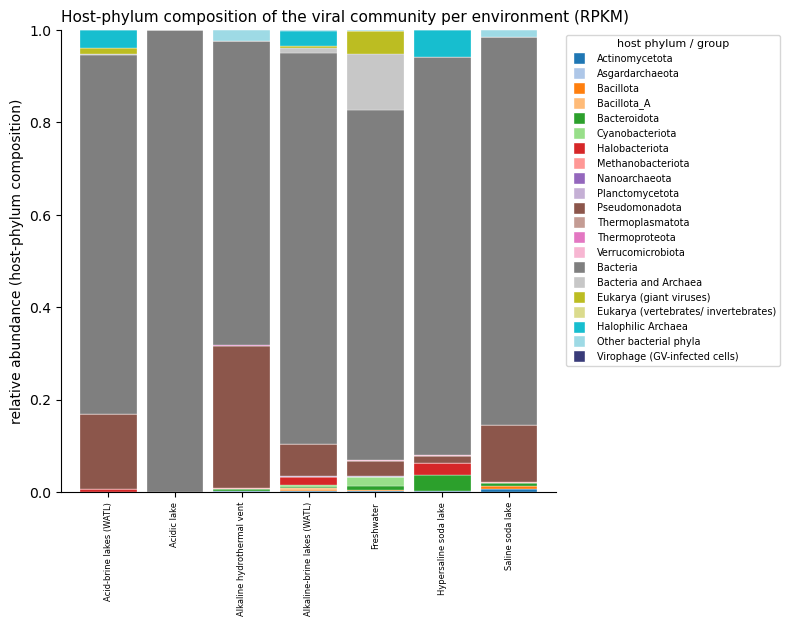

In [15]:
# host phylum composition (RPKM)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def host_composition_bars(host_df, X_LEVEL="name_full", TOP_BACT_PHYLA=8, out_png=None, out_csv=None):
    d = host_df.copy(); d["rpkm"] = pd.to_numeric(d.get("rpkm",1.0), errors="coerce").fillna(0.0)
    d = d.dropna(subset=["name_full","Environment_Bin"])
    if "has_iphop" not in d.columns: d["has_iphop"] = d.get("host_domain", pd.Series(index=d.index)).notna()
    for c in ("host_phylum","host_domain","Host_broad"): d[c] = d.get(c, pd.Series(index=d.index, dtype=object)).astype(object)

    # host category per virus
    ip = d[d["has_iphop"] & d["host_phylum"].notna()]
    phy2dom = ip.groupby("host_phylum")["host_domain"].first(); counts = ip["host_phylum"].value_counts()
    bact = [p for p in counts.index if phy2dom.get(p) == "Bacteria"][:TOP_BACT_PHYLA]
    keep = set(phy2dom.index[phy2dom.ne("Bacteria")]) | set(bact)
    d["hostcat"] = d.apply(lambda r: (r["host_phylum"] if (r["has_iphop"] and pd.notna(r["host_phylum"]) and r["host_phylum"] in keep)
                            else ("Other bacterial phyla" if (r["has_iphop"] and pd.notna(r["host_phylum"])) else r["Host_broad"])), axis=1)

    comp = d.groupby([X_LEVEL,"hostcat"])["rpkm"].sum().reset_index()
    tot  = d.groupby(X_LEVEL)["rpkm"].sum(); comp["frac"] = comp["rpkm"]/comp[X_LEVEL].map(tot)
    piv  = comp.pivot_table(index=X_LEVEL, columns="hostcat", values="frac", fill_value=0)

    envmap = d.groupby("name_full")["Environment_Bin"].first() if X_LEVEL=="name_full" else None
    xorder = sorted(piv.index, key=lambda l: (str(envmap.get(l)), l)) if X_LEVEL=="name_full" else sorted(piv.index)
    piv = piv.loc[xorder]
    cats = sorted(piv.columns, key=lambda c: (c not in keep, str(c))); piv = piv[cats]
    pal = {c:col for c,col in zip(cats, list(plt.get_cmap("tab20").colors)+list(plt.get_cmap("tab20b").colors))}
    envcol = {e: ENV_PALETTE.get(e, "0.6") for e in sorted(d["Environment_Bin"].unique())}

    fig, ax = plt.subplots(figsize=(0.34*len(xorder)+4, 6)); bottom = np.zeros(len(xorder)); X = np.arange(len(xorder))
    for c in cats:
        ax.bar(X, piv[c].values, bottom=bottom, color=pal[c], width=0.85, edgecolor="white", lw=0.2); bottom += piv[c].values
    ax.set_xticks(X); ax.set_xticklabels(xorder, rotation=90, fontsize=6)
    if X_LEVEL=="name_full":
        for i,l in enumerate(xorder): ax.get_xticklabels()[i].set_color(envcol.get(envmap.get(l),"k"))
    ax.set_ylabel("relative abundance (host-phylum composition)"); ax.set_ylim(0,1); ax.set_xlim(-0.7,len(xorder)-0.3)
    for s in ("top","right"): ax.spines[s].set_visible(False)
    leg = [Line2D([0],[0],marker="s",color="w",markerfacecolor=pal[c],markersize=9,label=c) for c in cats]
    l1 = ax.legend(handles=leg, title="host phylum / group", bbox_to_anchor=(1.01,1), loc="upper left", fontsize=7, title_fontsize=8)
    if X_LEVEL=="name_full":
        ax.add_artist(l1)
        eleg = [Line2D([0],[0],marker="s",color="w",markerfacecolor=envcol[e],markersize=9,label=e) for e in sorted(envcol)]
        ax.legend(handles=eleg, title="environment (label colour)", bbox_to_anchor=(1.01,0.32), loc="upper left", fontsize=6, title_fontsize=7)
    ax.set_title(f"Host-phylum composition of the viral community per {'lake' if X_LEVEL=='name_full' else 'environment'} (RPKM)", fontsize=11, loc="left")
    if out_png: fig.savefig(out_png, dpi=300, bbox_inches="tight")
    if out_csv: piv.to_csv(out_csv)
    plt.show(); return fig

OUTDIR = "/Users/skoog/Desktop/Revisions/"
src = host_df_all if "host_df_all" in dir() else host_df
_ = host_composition_bars(src, "name_full",       out_png=OUTDIR+"host_composition_per_lake.png", out_csv=OUTDIR+"host_composition_per_lake.csv")
_ = host_composition_bars(src, "Environment_Bin", out_png=OUTDIR+"host_composition_per_env.png",  out_csv=OUTDIR+"host_composition_per_env.csv")

## pH vs salinity by host group

In [16]:
# host group: iPHoP first, then fallback on family 
import numpy as np, pandas as pd

def _collapse4(label):
    s = str(label)
    if "Virophage" in s:            return "Virophage"
    if "Eukary" in s:               return "Eukarya"
    a, b = ("Archaea" in s), ("Bacteria" in s)
    if a and b:                     return "Bacteria and Archaea"
    if a:                           return "Archaea"
    if b:                           return "Bacteria"
    return np.nan

def _iphop_domain4(r):
    if not r.get("has_iphop", False): return np.nan
    dom = str(r.get("host_domain"))
    return {"Archaea":"Archaea", "Bacteria":"Bacteria",
            "Eukaryota":"Eukarya", "Eukarya":"Eukarya"}.get(dom, np.nan)

def add_host_group(df):
    d = df.copy()
    fam   = d["family"].astype(str).str.strip()
    g_ip  = d.apply(_iphop_domain4, axis=1)          # iPHoP
    g_fam = fam.map(host_ecology).map(_collapse4)    # family fallback
    d["Host_group"] = g_ip
    need = d["Host_group"].isna()
    d.loc[need, "Host_group"] = g_fam[need]
    d["Host_group_source"] = np.where(g_ip.notna(), "iPHoP",
                              np.where(g_fam.notna(), "family-dict", "unassigned"))
    d["Host_group"] = d["Host_group"].fillna("Unknown/Other")
    return d

host_df_all = add_host_group(host_df_all)
watl_df     = host_df_all[host_df_all["Environment_Bin"].astype(str)
                          .str.contains("WATL")].copy()

def _cov(d, name):
    N = len(d); src = d["Host_group_source"].value_counts()
    print(f"\n{name}: {N:,} viruses")
    for k in ["iPHoP", "family-dict", "unassigned"]:
        n = int(src.get(k, 0)); print(f"   {k:<12}: {n:,} ({100*n/max(N,1):.1f}%)")
    print("   groups:", d.loc[d.Host_group != 'Unknown/Other', 'Host_group']
                          .value_counts().to_dict())

_cov(host_df_all, "ALL environments")
_cov(watl_df,     "WATL only")



ALL environments: 8,980 viruses
   iPHoP       : 769 (8.6%)
   family-dict : 8,211 (91.4%)
   unassigned  : 0 (0.0%)
   groups: {'Bacteria': 8547, 'Bacteria and Archaea': 178, 'Archaea': 173, 'Eukarya': 81, 'Virophage': 1}

WATL only: 5,021 viruses
   iPHoP       : 410 (8.2%)
   family-dict : 4,611 (91.8%)
   unassigned  : 0 (0.0%)
   groups: {'Bacteria': 4770, 'Archaea': 148, 'Bacteria and Archaea': 72, 'Eukarya': 30, 'Virophage': 1}


## pI vs pH / salinity, WATL and all-env fits

In [17]:
lake_env = host_df_all.drop_duplicates("name_full")[["name_full","pH","Salinity"]].dropna()
from scipy.stats import spearmanr
rho, p = spearmanr(lake_env["pH"], lake_env["Salinity"])
print(f"pH vs Salinity across lakes: ρ = {rho:.3f}, p = {p:.4f}, n = {len(lake_env)} lakes")

pH vs Salinity across lakes: ρ = -0.316, p = 0.0210, n = 53 lakes


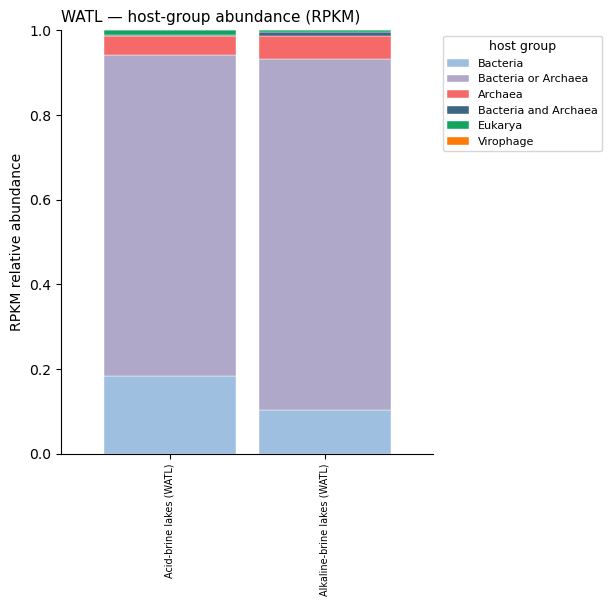

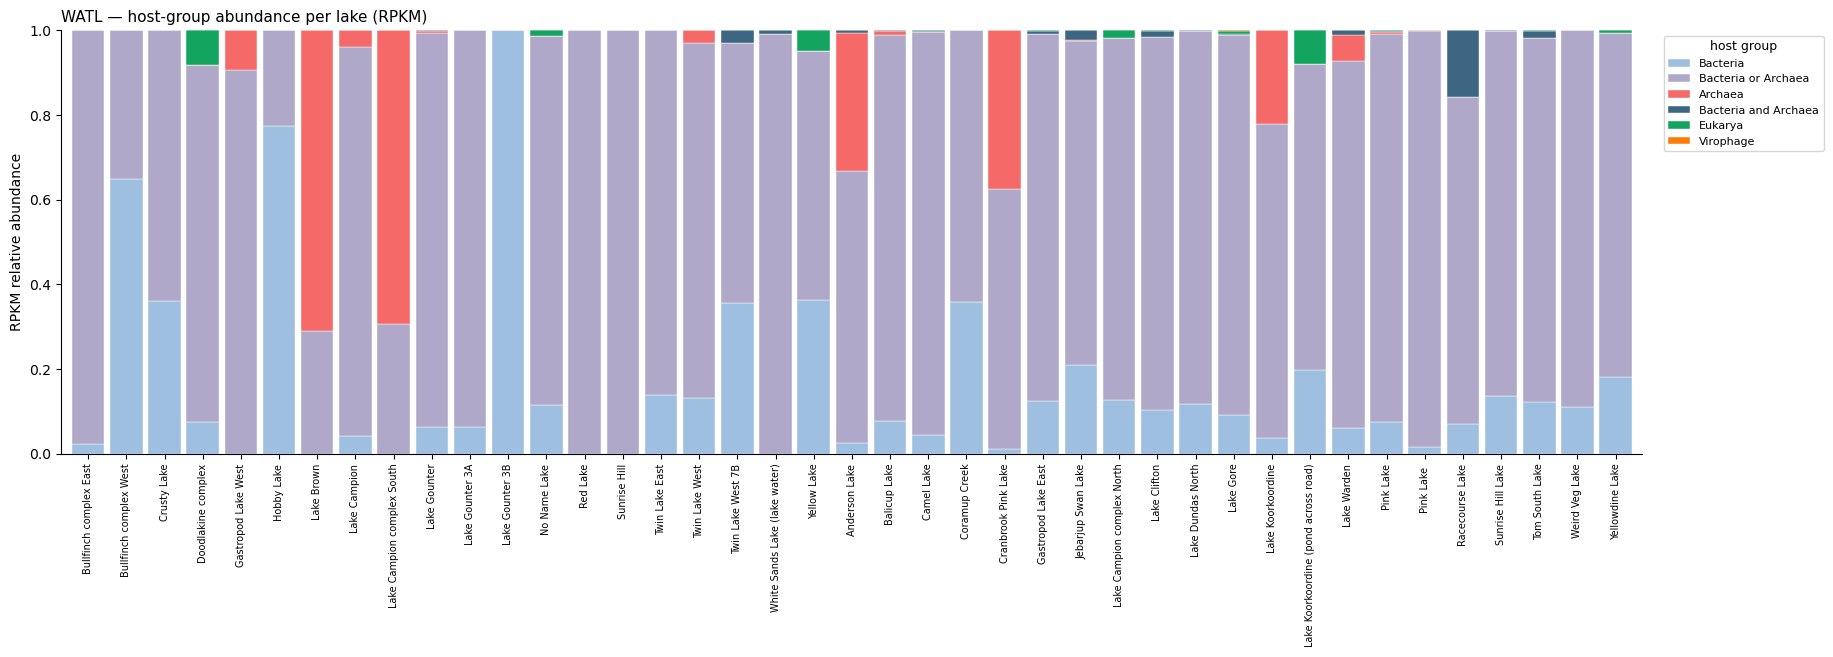

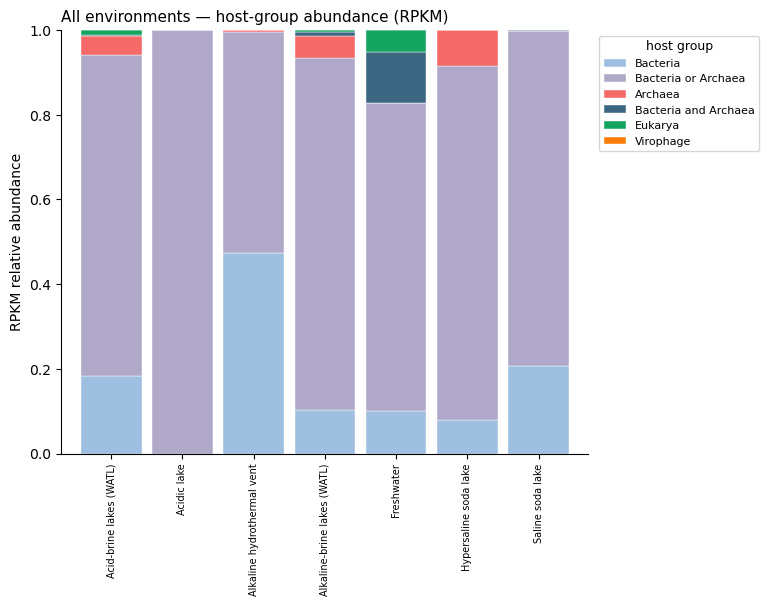

In [18]:
# RPKM stacked bars by host group
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
GROUP_PAL   = {"Bacteria":"#9FBFE0", "Archaea":"#F56969", "Eukarya":"#13A45F",
               "Virophage":"#FD7C08", "Bacteria and Archaea":"#3D6682",
               "Bacteria or Archaea":"#B0A8C8", "Unknown/Other":"#B9B9B9"}
GROUP_ORDER = ["Bacteria", "Bacteria or Archaea", "Archaea", "Bacteria and Archaea",
               "Eukarya", "Virophage", "Unknown/Other"]

def _boa_group(r):
    fam = str(r.get("family")).strip().lower()
    hg  = str(r.get("Host_group"))
    if (not r.get("has_iphop", False)) and fam == "unclassified caudoviricetes" and hg == "Bacteria":
        return "Bacteria or Archaea"
    return hg

def host_group_stack(df, x_level="Environment_Bin", title="", out_png=None, out_csv=None):
    d = df.copy(); d["rpkm"] = pd.to_numeric(d.get("rpkm", 1.0), errors="coerce").fillna(0.0)
    d = d.dropna(subset=[x_level])
    d["_hg"] = d.apply(_boa_group, axis=1)
    comp = d.groupby([x_level, "_hg"])["rpkm"].sum().reset_index()
    tot  = d.groupby(x_level)["rpkm"].sum()
    comp["frac"] = comp["rpkm"] / comp[x_level].map(tot)
    piv  = comp.pivot_table(index=x_level, columns="_hg", values="frac", fill_value=0)
    cats = [c for c in GROUP_ORDER if c in piv.columns]
    if x_level == "name_full":
        envmap = d.groupby("name_full")["Environment_Bin"].first()
        xorder = sorted(piv.index, key=lambda l: (str(envmap.get(l)), l))
    else:
        xorder = sorted(piv.index)
    piv = piv.loc[xorder, cats]
    fig, ax = plt.subplots(figsize=(0.4*len(xorder) + 4, 5.5))
    bottom = np.zeros(len(xorder)); X = np.arange(len(xorder))
    for c in cats:
        ax.bar(X, piv[c].values, bottom=bottom, color=GROUP_PAL[c], width=0.85,
               edgecolor="white", lw=0.3, label=c); bottom += piv[c].values
    ax.set_xticks(X); ax.set_xticklabels(xorder, rotation=90, fontsize=7)
    ax.set_ylim(0, 1); ax.set_xlim(-0.7, len(xorder) - 0.3)
    ax.set_ylabel("RPKM relative abundance")
    ax.set_title(title or f"Host-group abundance per "
                 f"{'lake' if x_level=='name_full' else 'environment'} (RPKM)",
                 fontsize=11, loc="left")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.legend(title="host group", bbox_to_anchor=(1.01, 1), loc="upper left",
              fontsize=8, title_fontsize=9)
    if out_png: fig.savefig(out_png, dpi=300, bbox_inches="tight")
    if out_csv: piv.to_csv(out_csv)
    plt.show(); return piv

_ = host_group_stack(watl_df, "Environment_Bin",
                     "WATL \u2014 host-group abundance (RPKM)",
                     OUTDIR + "hostgroup_abund_WATL_env.png",  OUTDIR + "hostgroup_abund_WATL_env.csv")
_ = host_group_stack(watl_df, "name_full",
                     "WATL \u2014 host-group abundance per lake (RPKM)",
                     OUTDIR + "hostgroup_abund_WATL_lake.png", OUTDIR + "hostgroup_abund_WATL_lake.csv")
_ = host_group_stack(host_df_all, "Environment_Bin",
                     "All environments \u2014 host-group abundance (RPKM)",
                     OUTDIR + "hostgroup_abund_ALLENV_env.png", OUTDIR + "hostgroup_abund_ALLENV_env.csv")

## PCoA (Bray-Curtis) with pH / salinity envfit

overall: 8,980 viruses
  iPHoP-predicted     : 769 (8.6%)
  + family-inferred   : 8,211 (91.4%)   <- added by host assumptions
  = combined coverage : 8,980 (100.0%)
  still unknown       : 0 (0.0%)

by environment:
 _src                         iPHoP  family-inferred  unknown     n  pct_iphop  pct_combined
Environment_Bin                                                                            
Acid-brine lakes (WATL)         86              994        0  1080        8.0         100.0
Acidic lake                      2               14        0    16       12.5         100.0
Alkaline hydrothermal vent      76              423        0   499       15.2         100.0
Alkaline-brine lakes (WATL)    324             3617        0  3941        8.2         100.0
Freshwater                      86             1117        0  1203        7.1         100.0
Hypersaline soda lake           24              240        0   264        9.1         100.0
Saline soda lake               171             

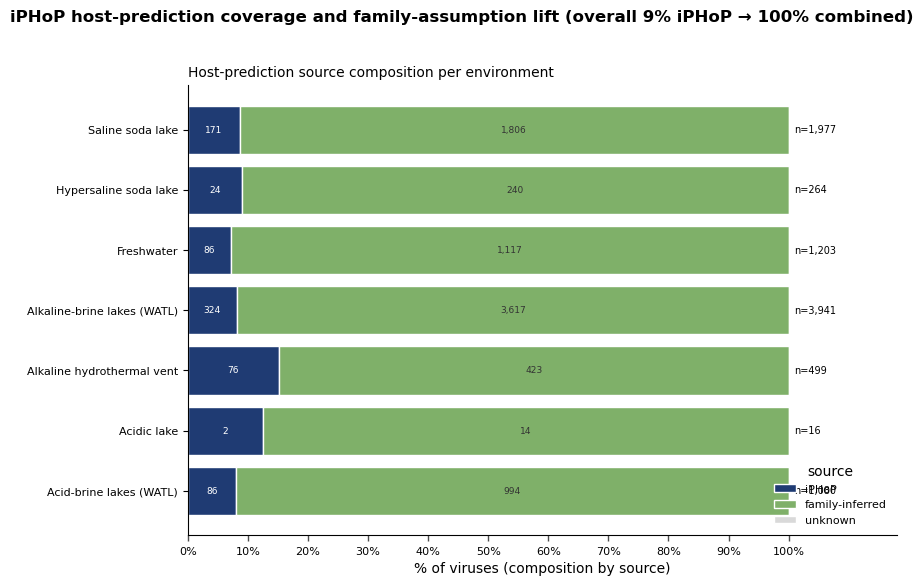

Saved: /Users/skoog/Desktop/Revisions/iPHoP_host_prediction_coverage.svg


In [19]:
# iPHoP coverage
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "DejaVu Sans"

OUTDIR = "/Users/skoog/Desktop/Revisions/"
os.makedirs(OUTDIR, exist_ok=True)

INFER_COL = "Host_group"  # or Host_broad

d = host_df_all.copy()
d["_src"] = np.where(
    d["has_iphop"],
    "iPHoP",
    np.where(d[INFER_COL].astype(str).ne("Unknown/Other"), "family-inferred", "unknown")
)

N = len(d)
n_ip = int((d["_src"] == "iPHoP").sum())
n_inf = int((d["_src"] == "family-inferred").sum())
n_unk = int((d["_src"] == "unknown").sum())

print(f"overall: {N:,} viruses")
print(f"  iPHoP-predicted     : {n_ip:,} ({100*n_ip/N:.1f}%)")
print(f"  + family-inferred   : {n_inf:,} ({100*n_inf/N:.1f}%)   <- added by host assumptions")
print(f"  = combined coverage : {n_ip+n_inf:,} ({100*(n_ip+n_inf)/N:.1f}%)")
print(f"  still unknown       : {n_unk:,} ({100*n_unk/N:.1f}%)")

tab = (
    d.groupby(["Environment_Bin", "_src"]).size().unstack(fill_value=0)
    .reindex(columns=["iPHoP", "family-inferred", "unknown"], fill_value=0)
)
tab["n"] = tab.sum(axis=1)
tab["pct_iphop"] = (100 * tab["iPHoP"] / tab["n"]).round(1)
tab["pct_combined"] = (100 * (tab["iPHoP"] + tab["family-inferred"]) / tab["n"]).round(1)

print("\nby environment:\n", tab.sort_values("pct_combined").to_string())

order = tab.sort_values("pct_combined").index
y = np.arange(len(order))
COL = {"iPHoP": "#1f3b73", "family-inferred": "#7FB069", "unknown": "#d9d9d9"}

fig, ax2 = plt.subplots(figsize=(9, 0.5 * len(order) + 2.2))

props = tab[["iPHoP", "family-inferred", "unknown"]].div(tab["n"], axis=0)
left = np.zeros(len(order))

for seg in ["iPHoP", "family-inferred", "unknown"]:
    vals = props.loc[order, seg].to_numpy(dtype=float) * 100
    raw_counts = tab.loc[order, seg].to_numpy(dtype=int)

    ax2.barh(y, vals, left=left, color=COL[seg], edgecolor="white", label=seg)

    for yi, (v, l, raw) in enumerate(zip(vals, left, raw_counts)):
        if v > 4:
            ax2.text(
                l + v / 2, yi, f"{raw:,}",
                ha="center", va="center", fontsize=6.5,
                color="white" if seg == "iPHoP" else "0.2"
            )

    left += vals

for yi, env in enumerate(order):
    ax2.text(101, yi, f"n={int(tab.loc[env, 'n']):,}", va="center", fontsize=7)

ax2.set_yticks(y)
ax2.set_yticklabels(order, fontsize=8)
ax2.set_xlim(0, 118)
ax2.set_xticks(np.arange(0, 101, 10))
ax2.set_xticklabels([f"{t}%" for t in np.arange(0, 101, 10)], fontsize=8)
ax2.tick_params(axis="x", which="major", length=4.5, width=1.0, direction="out", bottom=True, color="0.3")
ax2.set_xlabel("% of viruses (composition by source)")
ax2.set_title("Host-prediction source composition per environment", fontsize=10, loc="left")
ax2.legend(title="source", fontsize=8, loc="lower right", frameon=False)

for s in ("top", "right"):
    ax2.spines[s].set_visible(False)

fig.suptitle(
    f"iPHoP host-prediction coverage and family-assumption lift "
    f"(overall {100*n_ip/N:.0f}% iPHoP → {100*(n_ip+n_inf)/N:.0f}% combined)",
    fontsize=12, fontweight="bold", y=1.02
)

plt.tight_layout()

svg_path = os.path.join(OUTDIR, "iPHoP_host_prediction_coverage.svg")
fig.savefig(svg_path, format="svg", bbox_inches="tight")

plt.show()
print("Saved:", svg_path)

In [20]:
# export per-virus host assignments
import pandas as pd, numpy as np

d = host_df_all.copy()
if "Host_ecology" not in d.columns:
    d["Host_ecology"] = d["family"].astype(str).str.strip().map(host_ecology)
for col in ["host_domain","host_phylum","host_class","host_order","host_family","host_genus"]:
    if col not in d.columns: d[col] = np.nan

d["_has_iphop"]    = d["has_iphop"].fillna(False)
d["_has_inferred"] = d["Host_ecology"].notna() & (~d["Host_ecology"].astype(str).isin(["Unknown/Other","nan",""]))

d["host_assignment_source"] = np.where(d["_has_iphop"], "iPHoP",
                              np.where(d["_has_inferred"], "family-inferred", "unassigned"))

d["final_host_group"] = d.apply(_final_host_group, axis=1)

def _final_domain(r):
    if r["_has_iphop"]: return str(r.get("host_domain"))
    if r["_has_inferred"]:
        eco = str(r["Host_ecology"])
        if eco == "Bacteria":                         return "Bacteria"
        if eco in ("Halophilic Archaea","Thermophilic Archaea","Other Archaea"): return "Archaea"
        if eco == "Bacteria and Archaea":             return "Bacteria and Archaea"
        if eco == "Eukaryota, Archaea, and Bacteria": return "Eukaryota, Archaea, and Bacteria"
        if eco.startswith("Eukary"):                  return "Eukaryota"
        if "Virophage" in eco:                        return "Eukaryota (virophage)"
        return eco
    return "Unassigned"
d["assigned_host_domain"] = d.apply(_final_domain, axis=1)

def _host_name(r):
    if r["_has_iphop"]:
        for rank in ["host_genus","host_family","host_order","host_class","host_phylum","host_domain"]:
            v = r.get(rank)
            if pd.notna(v) and str(v).strip() not in ("","nan"): return str(v)
        return "(iPHoP, rank unresolved)"
    if r["_has_inferred"]: return str(r["Host_ecology"])
    return "Unassigned"
d["assigned_host"] = d.apply(_host_name, axis=1)

for rank in ["host_phylum","host_class","host_order","host_family","host_genus"]:
    d[rank] = np.where(d["_has_iphop"], d[rank].astype(str).replace("nan",""), "")
d["family_inferred_ecology"] = np.where(d["_has_iphop"], "", d["Host_ecology"].astype(str).replace("nan",""))

export = d.drop_duplicates(subset=["contig_id"]).copy()
cols = ["contig_id","family","host_assignment_source","final_host_group","assigned_host_domain",
        "assigned_host","host_phylum","host_class","host_order","host_family","host_genus",
        "family_inferred_ecology","name_full","Environment_Bin","Median_pI"]
cols = [c for c in cols if c in export.columns]
out = export[cols].sort_values(["host_assignment_source","final_host_group","assigned_host","family"])

OUTDIR = "/Users/skoog/Desktop/Revisions/"
out.to_csv(OUTDIR + "virus_host_assignments.csv", index=False)
print(f"Exported {len(out)} distinct viruses -> virus_host_assignments.csv\n")
print("final_host_group breakdown:"); print(out["final_host_group"].value_counts(dropna=False).to_string())
print("\nby source:"); print(out["host_assignment_source"].value_counts().to_string())
print("\nconsistency (final_host_group vs assigned_host_domain):")
print(out.groupby(["final_host_group","assigned_host_domain"]).size().reset_index(name="n").to_string(index=False))


Exported 6953 distinct viruses -> virus_host_assignments.csv

final_host_group breakdown:
final_host_group
Bacteria                                6633
Bacteria and Archaea                     160
Halophilic Archaea                        81
Eukarya (giant viruses)                   65
Other Archaea                              9
Eukarya (vertebrates/ invertebrates)       4
Virophage (GV-infected cells)              1

by source:
host_assignment_source
family-inferred    6386
iPHoP               567

consistency (final_host_group vs assigned_host_domain):
                    final_host_group  assigned_host_domain    n
                            Bacteria              Bacteria 6633
                Bacteria and Archaea  Bacteria and Archaea  160
             Eukarya (giant viruses)             Eukaryota   65
Eukarya (vertebrates/ invertebrates)             Eukaryota    4
                  Halophilic Archaea               Archaea   81
                       Other Archaea               Arc



######## Unclassified Caudoviricetes mode: exclude ########

=== Bubble correlations: permutation p, BH-FDR q, lake-bootstrap 95% CI ===
           scope                   group predictor  n_lakes     rho  p_perm  rho_lo  rho_hi  q_fdr
all environments      Halophilic Archaea        pH       17  0.0919  0.7245 -0.4079  0.5852 0.7793
all environments      Halophilic Archaea  Salinity       17 -0.4555  0.0683 -0.8544  0.0739 0.2732
all environments                Bacteria        pH       44 -0.6799  0.0001 -0.8234 -0.4100 0.0008
all environments                Bacteria  Salinity       44  0.1256  0.4177 -0.2693  0.4628 0.5660
all environments           Other Archaea        pH        7  0.3553  0.4245 -0.6629  0.9075 0.5660
all environments           Other Archaea  Salinity        7 -0.5559  0.2149 -0.9865  0.6635 0.4298
all environments Eukarya (giant viruses)        pH       17 -0.3213  0.2082 -0.7420  0.1995 0.4298
all environments Eukarya (giant viruses)  Salinity       17 -0.0735  

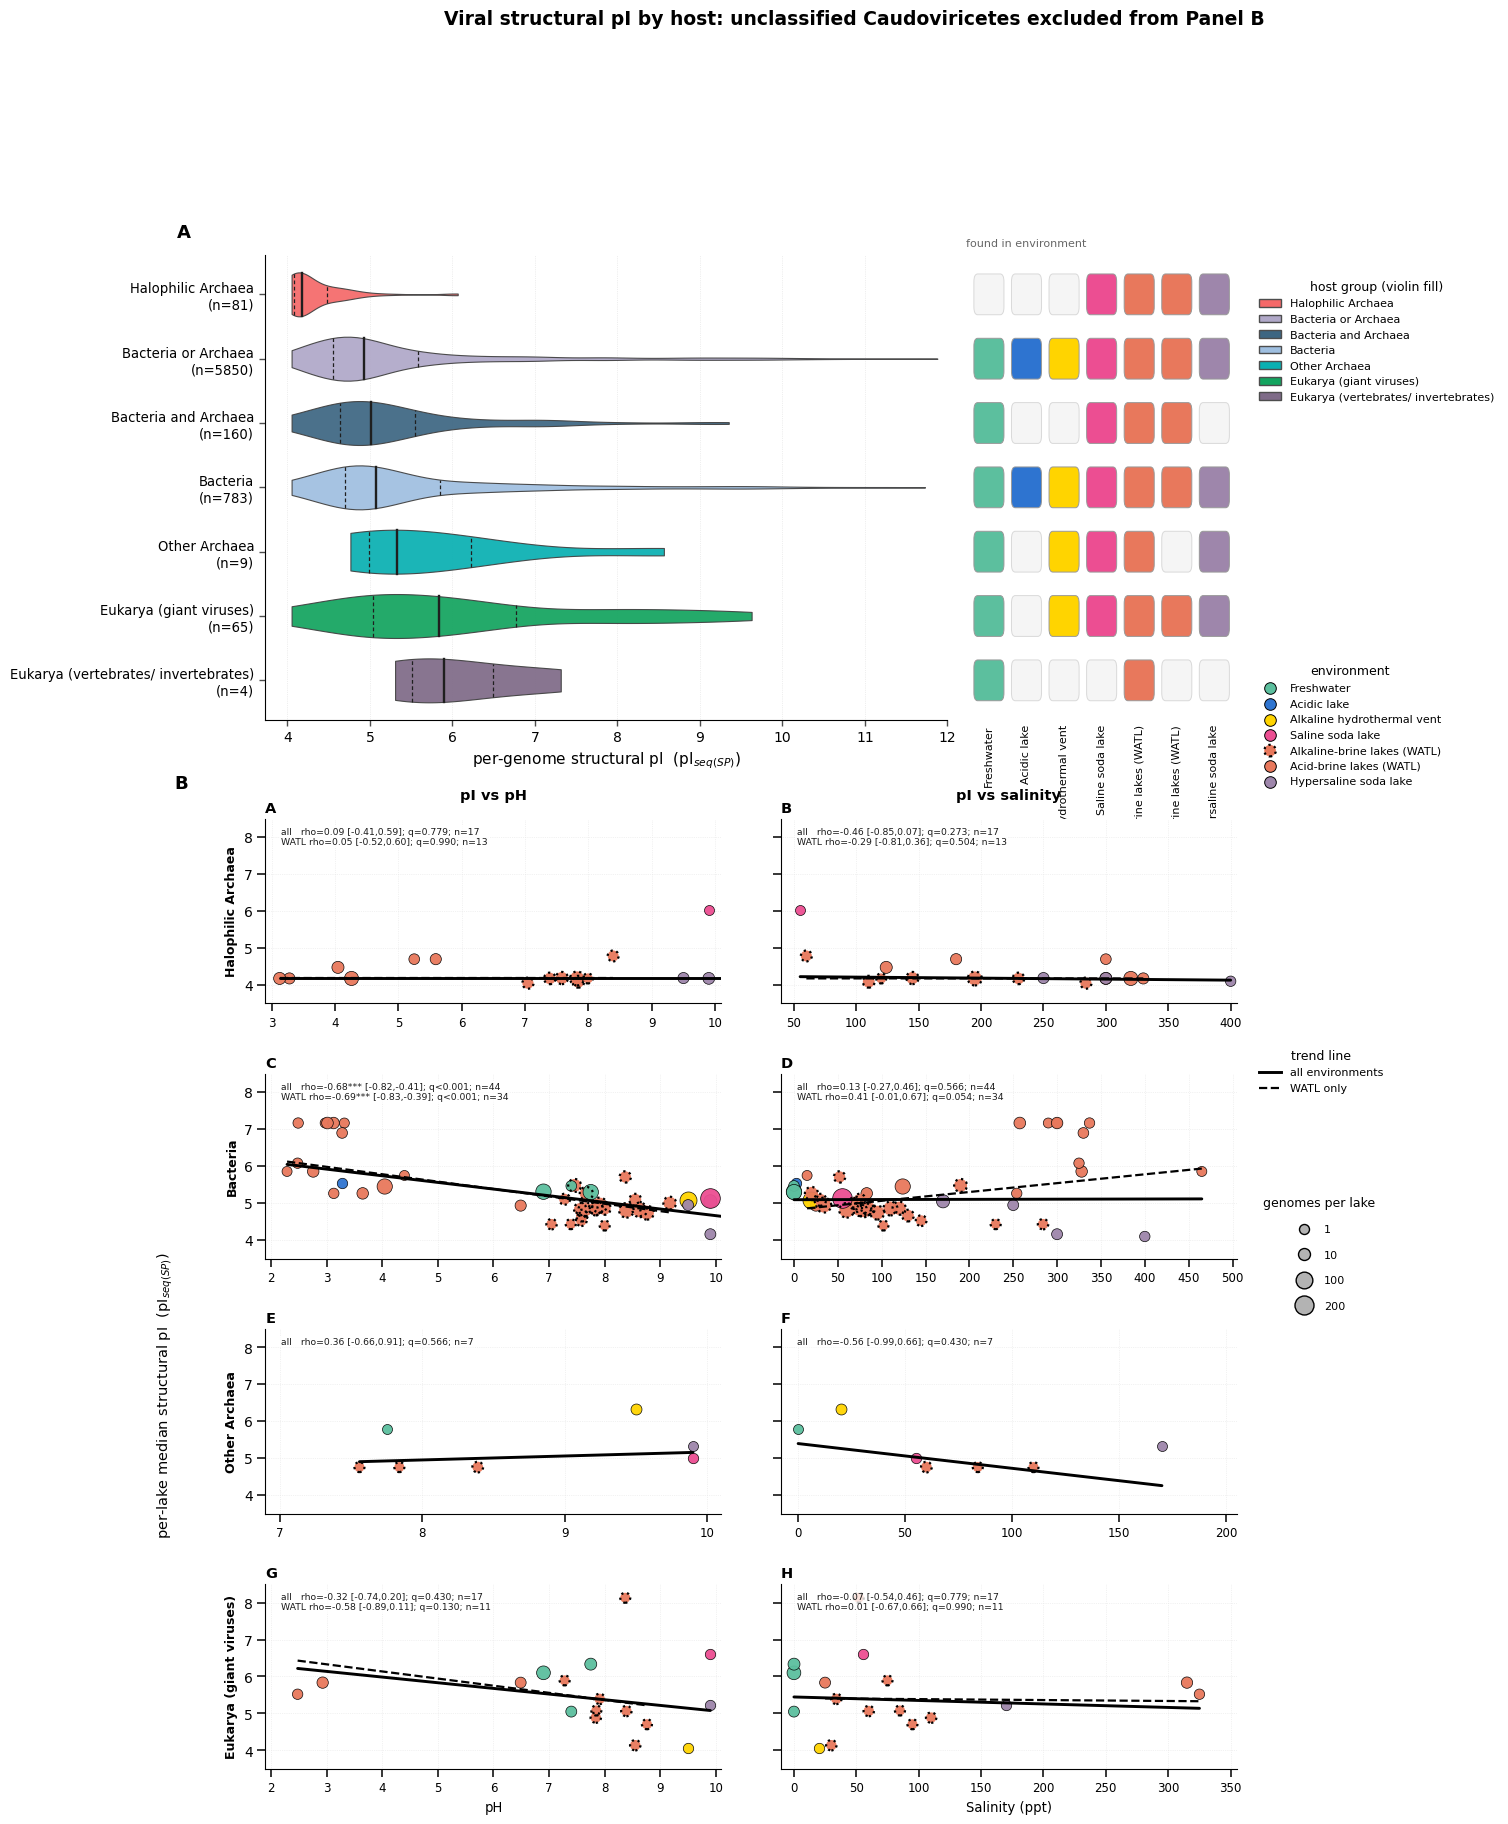

In [21]:
# True = one value per lake, False = per site/season
LAKE_UNIT_FIG5 = True

# combined figure: violins + presence, pI vs pH/salinity by host
import numpy as np, pandas as pd, re
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu, gaussian_kde, spearmanr, rankdata, theilslopes
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import warnings; warnings.filterwarnings("ignore")

# panel B host order
# non-iPHoP Unclassified Caudoviricetes excluded from B
BASE_SCATTER_ORDER = ["Halophilic Archaea", "Bacteria", "Other Archaea", "Eukarya (giant viruses)"]
UNCLASSIFIED_CAUDO_LABEL = "Unclassified Caudoviricetes"
VALID_UNCLASSIFIED_MODES = {"exclude", "bacteria", "separate"}

_ENVCOLOR = {"freshwater":"#5CBF9E","freshwater lake":"#5CBF9E","acidic lake":"#2E74D0",
    "alkaline hydrothermal vent":"#FFD400","saline soda lake":"#EC4E92",
    "alkaline-brine lake (watl)":"#E8785C","acid-brine lake (watl)":"#E8785C","hypersaline soda lake":"#9E86AB"}
_ENV_ORDER = ["Freshwater","Acidic lake","Alkaline hydrothermal vent","Saline soda lake",
              "Alkaline-brine lakes (WATL)","Acid-brine lakes (WATL)","Hypersaline soda lake"]
def _norm_env(e):
    s=str(e).lower().replace("wahl","watl"); s=re.sub(r"\blakes\b","lake",s); return re.sub(r"\s+"," ",s).strip()
def env_color(e): return _ENVCOLOR.get(_norm_env(e), "0.6")

def is_alkaline_brine(e):
    """Return True for alkaline-brine WATL/WAHL environments."""
    return _norm_env(e) == "alkaline-brine lake (watl)"

def _permutation_spearman(x, y, n_perm=9999, seed=0):
    """Two-sided permutation p-value for Spearman rho."""
    x=np.asarray(x,float); y=np.asarray(y,float)
    ok=np.isfinite(x)&np.isfinite(y); x=x[ok]; y=y[ok]
    if len(x)<4 or np.unique(x).size<2 or np.unique(y).size<2:
        return np.nan, np.nan
    rho=float(spearmanr(x,y).statistic)
    rx=rankdata(x).astype(float); ry=rankdata(y).astype(float)
    rx-=rx.mean(); ry-=ry.mean()
    den=np.sqrt(np.dot(rx,rx)*np.dot(ry,ry))
    if den==0: return np.nan, np.nan
    rng=np.random.default_rng(seed); extreme=0
    for _ in range(n_perm):
        rp=float(np.dot(rx,ry[rng.permutation(len(ry))])/den)
        if abs(rp) >= abs(rho)-1e-15: extreme += 1
    p=(extreme+1)/(n_perm+1)
    return rho,p

def _bootstrap_spearman_ci(x, y, n_boot=2000, seed=0):
    """Percentile 95% CI for rho by resampling whole lake-level rows."""
    x=np.asarray(x,float); y=np.asarray(y,float)
    ok=np.isfinite(x)&np.isfinite(y); x=x[ok]; y=y[ok]
    if len(x)<4 or np.unique(x).size<2 or np.unique(y).size<2:
        return np.nan, np.nan
    rng=np.random.default_rng(seed); vals=[]; n=len(x)
    for _ in range(n_boot):
        idx=rng.integers(0,n,n); xb=x[idx]; yb=y[idx]
        if np.unique(xb).size<2 or np.unique(yb).size<2: continue
        r=spearmanr(xb,yb).statistic
        if np.isfinite(r): vals.append(float(r))
    if len(vals)<max(200,int(0.5*n_boot)):
        return np.nan, np.nan
    return tuple(np.percentile(vals,[2.5,97.5]))

def _bubble_stats(gl, groups, min_lakes=5, n_perm=9999, n_boot=2000, seed=7):
    """Spearman tests per host group; BH within each scope."""
    rows=[]
    scopes=[("all environments",gl),("WATL only",gl[gl["_watl"]])]
    for si,(scope,base) in enumerate(scopes):
        for gi,grp in enumerate(groups):
            for pi,pred in enumerate(["pH","Salinity"]):
                sub=base.loc[base["_grp"].eq(grp),[pred,"pI","name_full"]].dropna()
                n_lakes=int(sub["name_full"].nunique())
                rho=p=lo=hi=np.nan
                if n_lakes>=min_lakes:
                    s=seed+10000*si+1000*gi+100*pi
                    rho,p=_permutation_spearman(sub[pred],sub["pI"],n_perm=n_perm,seed=s)
                    lo,hi=_bootstrap_spearman_ci(sub[pred],sub["pI"],n_boot=n_boot,seed=s+1)
                rows.append(dict(scope=scope,group=grp,predictor=pred,n_lakes=n_lakes,
                                 rho=rho,p_perm=p,rho_lo=lo,rho_hi=hi))
    S=pd.DataFrame(rows); S["q_fdr"]=np.nan
    for scope in S["scope"].unique():
        m=S["scope"].eq(scope)&S["p_perm"].notna()
        if m.any(): S.loc[m,"q_fdr"]=multipletests(S.loc[m,"p_perm"],method="fdr_bh")[1]
    return S

def _clustered_host_model(gl, groups=None):
    """Host x environment model on lake medians, SEs clustered by lake."""
    d=gl.dropna(subset=["pI","pH","Salinity","_grp","name_full"]).copy()
    preferred=["Bacteria","Halophilic Archaea",UNCLASSIFIED_CAUDO_LABEL,
               "Other Archaea","Eukarya (giant viruses)"]
    requested=groups if groups is not None else preferred
    cats=[g for g in requested if g in set(d["_grp"])]
    if len(cats)<2:
        print("Clustered host interaction model skipped: fewer than two host groups.")
        return None,pd.DataFrame(),pd.DataFrame()

    reference="Bacteria" if "Bacteria" in cats else cats[0]
    d=d[d["_grp"].isin(cats)].copy()
    d["_grp"]=pd.Categorical(d["_grp"],categories=cats)
    formula=f'pI ~ C(_grp, Treatment(reference="{reference}")) * (pH + Salinity)'
    try:
        fit=smf.ols(formula,d).fit(cov_type="cluster",
            cov_kwds={"groups":d["name_full"],"use_correction":True})
    except Exception as exc:
        print("Clustered host interaction model failed:",exc)
        return None,pd.DataFrame(),pd.DataFrame()
    names=list(fit.params.index)
    tests=[]
    for pred in ["pH","Salinity"]:
        terms=[i for i,nm in enumerate(names) if ":" in nm and nm.endswith(":"+pred)]
        if terms:
            R=np.zeros((len(terms),len(names)))
            for r,i in enumerate(terms): R[r,i]=1
            wt=fit.wald_test(R,scalar=True)
            tests.append(dict(test=f"host x {pred}",Wald=float(np.asarray(wt.statistic).squeeze()),p=float(wt.pvalue)))
    T=pd.DataFrame(tests)
    if len(T): T["q_fdr"]=multipletests(T["p"],method="fdr_bh")[1]

    slopes=[]
    for pred in ["pH","Salinity"]:
        if pred not in names:
            continue
        base_idx=names.index(pred)
        for grp in cats:
            c=np.zeros(len(names)); c[base_idx]=1
            if grp!=reference:
                target=f'C(_grp, Treatment(reference="{reference}"))[T.{grp}]:{pred}'
                if target in names: c[names.index(target)]=1
            tt=fit.t_test(c); ci=np.asarray(tt.conf_int()).reshape(-1)
            slopes.append(dict(group=grp,predictor=pred,
                               slope=float(np.asarray(tt.effect).squeeze()),
                               CI_low=float(ci[0]),CI_high=float(ci[1]),p=float(tt.pvalue)))
    ST=pd.DataFrame(slopes)
    if len(ST):
        ST["q_fdr"]=np.nan
        for pred in ST["predictor"].unique():
            m=ST["predictor"].eq(pred)
            ST.loc[m,"q_fdr"]=multipletests(ST.loc[m,"p"],method="fdr_bh")[1]
    return fit,T,ST

_CATC = {"Halophilic Archaea":"#F56969","Other Archaea":"#09B0B2","Bacteria":"#9FBFE0",
    "Bacteria and Archaea":"#3D6682","Bacteria or Archaea":"#B0A8C8",
    "Eukarya (giant viruses)":"#13A45F","Eukarya (vertebrates/ invertebrates)":"#7F6B88",
    "Eukarya (Plants)":"#6050AF","Eukarya (other)":"#13A45F",
    "Virophage (GV-infected cells)":"#FD7C08",
    "Unclassified Caudoviricetes":"#C7A76A","Unknown/Other":"lightgrey"}
def _cat_color(c): return _CATC.get(c, "0.7")

# Unclassified Caudoviricetes grouping
def _has_iphop_prediction(r):
    value=r.get("has_iphop",False)
    return bool(value) if pd.notna(value) else False


def _is_unclassified_caudo(r):
    return str(r.get("family")).strip().lower()=="unclassified caudoviricetes"


def _cat_group(r, unclassified_mode="exclude"):
    """Panel A grouping; mode also controls how non-iPHoP unclassified Caudoviricetes appear."""
    hg=str(r.get("Host_group")); eco=str(r.get("Host_ecology"))
    has_iphop=_has_iphop_prediction(r)
    if has_iphop:
        dom=str(r.get("host_domain")); phy=str(r.get("host_phylum"))
        if dom=="Archaea": return "Halophilic Archaea" if phy=="Halobacteriota" else "Other Archaea"
        if dom=="Bacteria": return "Bacteria"
        if dom in ("Eukaryota","Eukarya"): return eco if eco.startswith("Eukary") else "Eukarya (other)"
        return dom

    if _is_unclassified_caudo(r):
        if unclassified_mode=="bacteria": return "Bacteria"
        if unclassified_mode=="separate": return UNCLASSIFIED_CAUDO_LABEL
        return "Bacteria or Archaea"

    if hg=="Archaea": return "Halophilic Archaea" if eco=="Halophilic Archaea" else "Other Archaea"
    if hg.startswith("Eukary"): return eco if eco.startswith("Eukary") else "Eukarya (other)"
    if "Virophage" in hg: return "Virophage (GV-infected cells)"
    if hg in ("Bacteria","Bacteria and Archaea"): return hg
    if hg in ("nan","None",""): return "Unknown/Other"
    return hg


def _grp_scatter(r, unclassified_mode="exclude"):
    """Panel B grouping for the three Unclassified Caudoviricetes treatments."""
    if _has_iphop_prediction(r):
        g=_host_group_iphop(r)
        return {"Thermophilic Archaea":"Other Archaea"}.get(g,g)

    if _is_unclassified_caudo(r):
        if unclassified_mode=="exclude": return np.nan
        if unclassified_mode=="bacteria": return "Bacteria"
        if unclassified_mode=="separate": return UNCLASSIFIED_CAUDO_LABEL

    hg=str(r.get("Host_group")); eco=str(r.get("Host_ecology"))
    if hg=="Archaea": return "Halophilic Archaea" if eco=="Halophilic Archaea" else "Other Archaea"
    if hg=="Bacteria": return "Bacteria"
    if hg.startswith("Eukary"): return "Eukarya (giant viruses)" if eco=="Eukarya (giant viruses)" else np.nan
    return np.nan

def _violin(ax,v,y,color,VW):
    v=np.asarray(v,float); v=v[np.isfinite(v)]
    if len(v)<2 or np.std(v)<1e-9:
        ax.scatter(v,[y]*len(v),color=color,edgecolor="0.2",s=24,lw=0.6,zorder=3)
        if len(v): ax.plot([np.median(v)]*2,[y-VW*0.18,y+VW*0.18],color="0.12",lw=1.5,zorder=5); return
    pc=ax.violinplot([v],positions=[y],vert=False,widths=VW,showmedians=False,showextrema=False)
    b=pc["bodies"][0]; b.set_facecolor(color); b.set_alpha(0.93); b.set_edgecolor("0.25"); b.set_linewidth(0.8)
    kde=gaussian_kde(v); xs=np.linspace(v.min(),v.max(),200); dens=kde(xs); dens=dens/dens.max()*(VW/2)
    q1,med,q3=np.percentile(v,[25,50,75])
    for q,lw,ls in [(q1,0.9,(0,(3,2))),(med,1.7,"-"),(q3,0.9,(0,(3,2)))]:
        hw=np.interp(q,xs,dens); ax.plot([q,q],[y-hw,y+hw],color="0.12",lw=lw,ls=ls,zorder=5)


def build_merged_figure(host_df, PICOL=None, XMAX=12, MIN_N=3,
                        MIN_LAKES_GRP=5, MIN_VIRUSES_PER_LAKE=1,
                        N_PERM=9999, N_BOOT=2000, STATS_SEED=7,
                        unclassified_mode="exclude", figure_title=None,
                        out_svg=None, out_png=None, out_stats_csv=None):
    PICOL = PICOL or "Median_pI"
    unclassified_mode=str(unclassified_mode).strip().lower()
    if unclassified_mode not in VALID_UNCLASSIFIED_MODES:
        raise ValueError(
            f"unclassified_mode must be one of {sorted(VALID_UNCLASSIFIED_MODES)}; "
            f"received {unclassified_mode!r}."
        )
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "svg.fonttype": "none",
        "mathtext.fontset": "dejavusans",
        "text.usetex": False,
    })

    # violin data
    dv = host_df.copy()
    if "Host_ecology" not in dv.columns:
        dv["Host_ecology"] = dv["family"].astype(str).str.strip().map(host_ecology).fillna("Unknown/Other")
    dv[PICOL] = pd.to_numeric(dv[PICOL], errors="coerce")
    dv["grp"] = dv.apply(lambda r:_cat_group(r,unclassified_mode), axis=1)
    dv = dv.dropna(subset=[PICOL,"grp"]); dv = dv[~dv["grp"].isin(["Unknown/Other"])]
    _envmap = dv.groupby("contig_id")["Environment_Bin"].apply(lambda s:set(s.dropna())) if "contig_id" in dv.columns else None
    if "contig_id" in dv.columns: dv = dv.drop_duplicates(subset=["contig_id"])
    envs = [e for e in _ENV_ORDER if e in set(dv["Environment_Bin"])]
    counts = dv["grp"].value_counts(); keep=[g for g in counts.index if counts[g]>=MIN_N]
    vrows=[dict(grp=g, n=int((dv.grp==g).sum()), vals=dv.loc[dv.grp==g,PICOL].values,
                median=float(dv.loc[dv.grp==g,PICOL].median()),
                envset=(set().union(*[_envmap[c] for c in dv.loc[dv.grp==g,"contig_id"] if c in _envmap]) if _envmap is not None else set(dv.loc[dv.grp==g,"Environment_Bin"].dropna().unique())))
           for g in keep]
    vtbl = pd.DataFrame(vrows)
    # order A by median pI
    vtbl = vtbl.sort_values("median").reset_index(drop=True)
    ordered = list(vtbl["grp"])
    nV = len(vtbl)

    # scatter data
    ds = host_df.copy()
    if "Host_ecology" not in ds.columns:
        ds["Host_ecology"] = ds["family"].astype(str).str.strip().map(host_ecology).fillna("Unknown/Other")
    for c in (PICOL,"pH","Salinity"): ds[c]=pd.to_numeric(ds[c],errors="coerce")
    ds["rpkm"]=pd.to_numeric(ds.get("rpkm",1.0),errors="coerce").fillna(1.0)
    ds["_grp"]=ds.apply(lambda r:_grp_scatter(r,unclassified_mode),axis=1)
    ds=ds.dropna(subset=[PICOL,"pH","Salinity","name_full","_grp"])
    # collapse sites to lakes
    if LAKE_UNIT_FIG5:
        import re as _re
        _AL={"Sunrise Hill":"Sunrise Hill Lake"}
        def _pl5(n):
            t=_re.sub(r"\s+"," ",str(n)).strip()
            if "cueva de la mora" in t.lower(): return "Cueva de la Mora"
            return _AL.get(t,t)
        ds["name_full"]=ds["name_full"].map(_pl5)
        _bin=(ds.groupby("name_full")["Environment_Bin"]
                .agg(lambda s:s.value_counts().idxmax()))
        ds["Environment_Bin"]=ds["name_full"].map(_bin)
    scatter_order=list(BASE_SCATTER_ORDER)
    if unclassified_mode=="separate":
        scatter_order.insert(scatter_order.index("Bacteria")+1,UNCLASSIFIED_CAUDO_LABEL)
    ds=ds[ds["_grp"].isin(scatter_order)]
    envs_s=sorted(ds["Environment_Bin"].unique())
    gl=(ds.groupby(["_grp","name_full","Environment_Bin"]).apply(lambda g:pd.Series(
        {"pI":float(g[PICOL].median()),"pH":g["pH"].median(),"Salinity":g["Salinity"].median(),"n":len(g)})).reset_index())
    gl=gl[gl["n"]>=MIN_VIRUSES_PER_LAKE].copy()
    gl["_watl"]=gl["Environment_Bin"].astype(str).str.upper().str.contains("WATL|WAHL")
    sgroups=[g for g in scatter_order if g in set(gl["_grp"])]

    bubble_stats=_bubble_stats(gl,sgroups,min_lakes=MIN_LAKES_GRP,
                               n_perm=N_PERM,n_boot=N_BOOT,seed=STATS_SEED)
    interaction_fit,interaction_tests,interaction_slopes=_clustered_host_model(gl,groups=sgroups)
    print(f"\n\n######## Unclassified Caudoviricetes mode: {unclassified_mode} ########")
    print("\n=== Bubble correlations: permutation p, BH-FDR q, lake-bootstrap 95% CI ===")
    print(bubble_stats.round(4).to_string(index=False))
    if len(interaction_tests):
        print("\n=== Cluster-robust host interaction tests (pH and salinity in same model) ===")
        print(interaction_tests.round(4).to_string(index=False))
        print("\n=== Cluster-robust adjusted slopes by host group ===")
        print(interaction_slopes.round(4).to_string(index=False))
    if out_stats_csv:
        bubble_stats.to_csv(out_stats_csv,index=False)
        stem=re.sub(r"\.csv$","",out_stats_csv,flags=re.I)
        interaction_tests.to_csv(stem+"_interaction_tests.csv",index=False)
        interaction_slopes.to_csv(stem+"_interaction_slopes.csv",index=False)
    smin,smax=int(gl["n"].min()),int(gl["n"].max())
    def _size(n):
        min_size = 52   # was 30
        max_size = 200
        if smax <= smin:
            return 70
        scaled = (np.sqrt(n)-np.sqrt(smin))/(np.sqrt(smax)-np.sqrt(smin))
        return min_size + scaled*(max_size-min_size)
    def _refsizes():
        nice=[1,5,10,25,50,100,150,200,250,300,400,500]; c=[x for x in nice if smin<=x<=smax]
        if smin not in c: c=[smin]+c
        top=max([x for x in nice if x<=smax],default=smax)
        if top not in c: c.append(top)
        c=sorted(set(c))
        if len(c)>4: idx=sorted(set(np.linspace(0,len(c)-1,4).round().astype(int))); c=[c[i] for i in idx]
        return c
    def _star(q):
        return "***" if (pd.notna(q) and q<.001) else "**" if (pd.notna(q) and q<.01) else "*" if (pd.notna(q) and q<.05) else ""
    def _qtxt(q):
        if pd.isna(q): return "q=NA"
        if q<0.001: return "q<0.001"
        return f"q={q:.3f}"

    # layout
    nS=len(sgroups)
    fig=plt.figure(figsize=(15.7, 0.68*nV + 2.75*nS + 3.9))
    outer=GridSpec(2,2, figure=fig, height_ratios=[0.68*nV+1.3, 2.75*nS+1.4],
                   width_ratios=[1.0, 0.24], hspace=0.14, wspace=0.02)

    # top
    topgs=GridSpecFromSubplotSpec(1,2, subplot_spec=outer[0,0], width_ratios=[6,0.34*len(envs)], wspace=0.04)
    axV=fig.add_subplot(topgs[0]); axH=fig.add_subplot(topgs[1])
    xmin=np.nanmin(np.concatenate(vtbl["vals"].values)); pad=0.04*(XMAX-xmin)
    ROW=0.82; pos=np.arange(nV)[::-1]*ROW; YL=(pos.min()-0.5,pos.max()+0.5)
    axV.grid(axis="x",ls=":",lw=0.5,color="0.88"); axV.set_axisbelow(True); VW=0.56
    for i,(_,r) in enumerate(vtbl.iterrows()): _violin(axV,r["vals"],pos[i],_cat_color(r["grp"]),VW)
    axV.set_yticks(pos); axV.set_yticklabels([f"{r['grp']}\n(n={r.n})" for _,r in vtbl.iterrows()],fontsize=9.5)
    axV.set_ylim(*YL); axV.set_xlim(xmin-pad,XMAX)
    axV.set_xlabel("per-genome structural pI  (pI$_{seq(SP)}$)",fontsize=11)
    for s in ("top","right"): axV.spines[s].set_visible(False)
    axV.tick_params(which="major",length=4.5,width=1.0,direction="out",bottom=True,left=True,color="0.3"); axV.minorticks_off()
    bh,bw=0.52,0.80
    for i,(_,r) in enumerate(vtbl.iterrows()):
        for j,e in enumerate(envs):
            pres=e in r["envset"]
            axH.add_patch(FancyBboxPatch((j-bw/2,pos[i]-bh/2),bw,bh,boxstyle="round,pad=0,rounding_size=0.10",
                facecolor=env_color(e) if pres else "#F5F5F5", edgecolor="0.6" if pres else "0.85", lw=0.7, mutation_aspect=1.0, zorder=2))
    axH.set_xlim(-0.6,len(envs)-0.4); axH.set_ylim(*YL); axH.set_yticks([])
    axH.set_xticks(range(len(envs))); axH.set_xticklabels(envs,rotation=90,fontsize=8,color="black")
    for s in ("top","right","left","bottom"): axH.spines[s].set_visible(False)
    axH.tick_params(length=0); axH.set_title("found in environment",loc="left",fontsize=8,color="0.4",pad=6)
    axV.set_title("A", fontsize=13, fontweight="bold", loc="left", x=-0.13, y=1.02)

    # bottom
    botgs=GridSpecFromSubplotSpec(nS,2, subplot_spec=outer[1,0], wspace=0.13, hspace=0.38)
    ENVCOL={e:env_color(e) for e in envs_s}
    def fitline(ax,sub,xcol,ls,lw):
        """Robust Theil-Sen line for display; inference comes from bubble_stats."""
        x=sub[xcol].to_numpy(float); yv=sub["pI"].to_numpy(float)
        m=np.isfinite(x)&np.isfinite(yv)
        if m.sum()<max(4,MIN_LAKES_GRP) or np.unique(x[m]).size<2: return
        try:
            slope,intercept,_,_=theilslopes(yv[m],x[m],alpha=0.95)
            xs=np.linspace(x[m].min(),x[m].max(),40)
            ax.plot(xs,intercept+slope*xs,ls,color="black",lw=lw,zorder=6,solid_capstyle="round")
        except Exception:
            pass
    PAN="ABCDEFGHIJ"
    for i,grp in enumerate(sgroups):
        sub=gl[gl._grp==grp]; axp=fig.add_subplot(botgs[i,0]); axs=fig.add_subplot(botgs[i,1])
        def panel(ax,xcol,xlabel,first,bottom,pl):
            ax.set_axisbelow(True); ax.grid(axis="both",ls=":",lw=0.5,color="0.9")
            for e,gg in sub.groupby("Environment_Bin"):
                # to numpy (pandas 2 indexing error)
                x_values = gg[xcol].to_numpy(dtype=float)
                y_values = gg["pI"].to_numpy(dtype=float)
                n_values = gg["n"].to_numpy(dtype=float)
                sizes = np.asarray([_size(n) for n in n_values], dtype=float)
                if is_alkaline_brine(e):
                    ax.scatter(x_values,y_values,s=sizes,marker="o",
                               facecolors=ENVCOL.get(e,"grey"),edgecolors="none",
                               linewidths=0,alpha=0.95,zorder=3)
                    ax.scatter(x_values,y_values,s=sizes,marker="o",
                               facecolors="none",edgecolors="black",linewidths=1.6,
                               linestyles=":",alpha=1.0,zorder=4)
                else:
                    ax.scatter(x_values,y_values,s=sizes,marker="o",
                               facecolors=ENVCOL.get(e,"grey"),edgecolors="black",
                               linewidths=0.5,alpha=0.95,zorder=3)
            fitline(ax,sub,xcol,"-",2.1)
            fitline(ax,sub[sub._watl],xcol,"--",1.6)
            lines=[]
            for scope,label in [("all environments","all  "),("WATL only","WATL")]:
                rr=bubble_stats[(bubble_stats.scope==scope)&
                                (bubble_stats.group==grp)&
                                (bubble_stats.predictor==xcol)]
                if len(rr) and pd.notna(rr.iloc[0].rho):
                    r=rr.iloc[0]
                    ci=f" [{r.rho_lo:.2f},{r.rho_hi:.2f}]" if pd.notna(r.rho_lo) else ""
                    lines.append(f"{label} rho={r.rho:.2f}{_star(r.q_fdr)}{ci}; "
                                 f"{_qtxt(r.q_fdr)}; n={int(r.n_lakes)}")
            if lines:
                ax.text(
                    0.035, 0.955, "\n".join(lines),
                    transform=ax.transAxes,
                    fontsize=6.7,
                    va="top", ha="left",
                    family="DejaVu Sans",
                    color="0.1",
                    zorder=8,
                    bbox=dict(
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.78,
                        boxstyle="round,pad=0.15",
                    ),
                )
            ax.annotate(pl,xy=(0.0,1.02),xycoords="axes fraction",fontsize=10.5,fontweight="bold",va="bottom",ha="left")
            for s in ("top","right"): ax.spines[s].set_visible(False)
            ax.minorticks_off(); ax.tick_params(axis="both",which="major",length=5.5,width=1.1,direction="out",bottom=True,left=True,color="black")
            ax.set_yticks([4,5,6,7,8])

            # x ranges
            vals = sub[xcol].dropna().to_numpy(float)
            if len(vals):
                if xcol == "pH":
                    ph_min = max(2, int(np.floor(vals.min())))
                    ph_max = min(10, int(np.ceil(vals.max())))
                    if ph_max <= ph_min:
                        ph_max = min(10, ph_min + 1)
                    ax.set_xlim(ph_min - 0.1, ph_max + 0.1)
                    ax.set_xticks(np.arange(ph_min, ph_max + 1, 1))
                elif xcol == "Salinity":
                    sal_min = max(0, int(np.floor(vals.min() / 50.0) * 50))
                    sal_max = int(np.ceil(vals.max() / 50.0) * 50)
                    if sal_max <= sal_min:
                        sal_max = sal_min + 50
                    # pad before 0
                    sal_left_pad = max(8.0, 0.03 * (sal_max - sal_min))
                    ax.set_xlim(sal_min - sal_left_pad, sal_max + 5)
                    ax.set_xticks(np.arange(sal_min, sal_max + 1, 50))

            ax.tick_params(axis="x", labelbottom=True, labelsize=8.5)
            if bottom:
                ax.set_xlabel(xlabel,fontsize=9.5)
            if first: ax.set_ylabel(f"{grp}",fontsize=9.0,fontweight="bold")
            else:
                plt.setp(ax.get_yticklabels(),visible=False)
                ax.tick_params(axis="y", labelleft=False)
        bottom=(i==nS-1)
        panel(axp,"pH","pH",True,bottom,PAN[2*i]); panel(axs,"Salinity","Salinity (ppt)",False,bottom,PAN[2*i+1])
        axp.set_ylim(3.5,8.5); axs.set_ylim(3.5,8.5)
        if i==0:
            axp.set_title("pI vs pH",fontsize=10.5,fontweight="bold",pad=14)
            axs.set_title("pI vs salinity",fontsize=10.5,fontweight="bold",pad=14)
            axp.annotate("B", xy=(-0.20,1.14), xycoords="axes fraction", fontsize=13, fontweight="bold", va="bottom", ha="left")
    fig.text(0.055,0.30,"per-lake median structural pI  (pI$_{seq(SP)}$)",rotation=90,va="center",fontsize=10.5)

    # legend
    axL=fig.add_subplot(outer[:,1]); axL.axis("off")
    all_envs=[e for e in _ENV_ORDER if e in (set(envs)|set(envs_s))]
    env_h=[]
    for e in all_envs:
        env_h.append(axL.scatter([],[],s=70,marker="o",facecolors=env_color(e),
                                 edgecolors="black",
                                 linewidths=1.6 if is_alkaline_brine(e) else 0.7,
                                 linestyles=":" if is_alkaline_brine(e) else "-",label=e))
    host_h=[Patch(facecolor=_cat_color(g),edgecolor="0.3",label=g) for g in ordered]
    trend_h=[Line2D([0],[0],color="black",ls="-",lw=2.1,label="all environments"),
             Line2D([0],[0],color="black",ls="--",lw=1.6,label="WATL only")]
    size_h=[Line2D([],[],marker="o",linestyle="None",markersize=np.sqrt(_size(n)),markerfacecolor="0.7",markeredgecolor="black",label=str(n)) for n in _refsizes()]
    y=0.99
    l1=axL.legend(handles=host_h,title="host group (violin fill)",loc="upper left",bbox_to_anchor=(0.0,y),fontsize=8,title_fontsize=9,frameon=False); axL.add_artist(l1)
    y-=0.03+0.032*len(host_h)
    l2=axL.legend(handles=env_h,title="environment",loc="upper left",bbox_to_anchor=(0.0,y),fontsize=8,title_fontsize=9,frameon=False); axL.add_artist(l2)
    y-=0.03+0.032*len(env_h)
    l3=axL.legend(handles=trend_h,title="trend line",loc="upper left",bbox_to_anchor=(0.0,y),fontsize=8,title_fontsize=9,frameon=False); axL.add_artist(l3)
    y-=0.03+0.032*len(trend_h)
    axL.legend(handles=size_h,title="genomes per lake",loc="upper left",bbox_to_anchor=(0.0,y),fontsize=8,title_fontsize=9,labelspacing=1.4,borderpad=0.8,frameon=False)

    if figure_title is None:
        mode_titles={
            "exclude":"Viral structural pI by host: unclassified Caudoviricetes excluded from Panel B",
            "bacteria":"Viral structural pI by host: unclassified Caudoviricetes included with Bacteria",
            "separate":"Viral structural pI by host: unclassified Caudoviricetes shown separately",
        }
        figure_title=mode_titles[unclassified_mode]
    fig.suptitle(figure_title,fontsize=13.5,fontweight="bold",y=1.005)
    if out_svg: fig.savefig(out_svg,format="svg",bbox_inches="tight")
    if out_png: fig.savefig(out_png,dpi=300,bbox_inches="tight")
    plt.show()
    return fig

OUTDIR = "/Users/skoog/Desktop/Revisions/"

COMMON_FIGURE_KWARGS = dict(
    PICOL="Median_pI",
    XMAX=12,
    MIN_N=3,
    MIN_LAKES_GRP=5,
    MIN_VIRUSES_PER_LAKE=1,
    N_PERM=9999,
    N_BOOT=2000,
    STATS_SEED=7,
)

fig_original = build_merged_figure(
    host_df_all,
    unclassified_mode="exclude",
    out_svg=OUTDIR + "combined_host_pI_MERGED.svg",
    out_png=OUTDIR + "combined_host_pI_MERGED.png",
    out_stats_csv=OUTDIR + "combined_host_pI_bubble_stats.csv",
    **COMMON_FIGURE_KWARGS,
)


In [22]:
# Fig 5A sensitivity, iPHoP-only hosts

import numpy as np
import pandas as pd
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

PICOL = "Median_pI"

d_iphop = host_df_all[host_df_all["has_iphop"].fillna(False)].copy()
d_iphop[PICOL] = pd.to_numeric(d_iphop[PICOL], errors="coerce")
d_iphop["host_group_iphop_only"] = d_iphop.apply(_host_group_iphop, axis=1)
d_iphop["host_group_iphop_only"] = d_iphop["host_group_iphop_only"].replace(
    {"Thermophilic Archaea": "Other Archaea"}
)
d_iphop = d_iphop[
    d_iphop["host_group_iphop_only"].isin(
        ["Bacteria", "Halophilic Archaea", "Other Archaea"]
    )
].dropna(subset=[PICOL]).copy()

if "contig_id" in d_iphop.columns:
    d_iphop = d_iphop.drop_duplicates(subset=["contig_id"])

groups = ["Bacteria", "Halophilic Archaea", "Other Archaea"]
arrays = [
    d_iphop.loc[d_iphop["host_group_iphop_only"] == group, PICOL].to_numpy()
    for group in groups
]

H_iphop, p_iphop = kruskal(*arrays)

summary_iphop = (
    d_iphop.groupby("host_group_iphop_only")[PICOL]
    .agg(n="size", median="median")
    .reindex(groups)
    .reset_index()
)

pair_rows = []
for i, group_1 in enumerate(groups):
    for group_2 in groups[i + 1:]:
        a = d_iphop.loc[
            d_iphop["host_group_iphop_only"] == group_1, PICOL
        ].to_numpy()
        b = d_iphop.loc[
            d_iphop["host_group_iphop_only"] == group_2, PICOL
        ].to_numpy()

        U, p = mannwhitneyu(a, b, alternative="two-sided")
        delta = (
            sum(np.sum(x > b) for x in a)
            - sum(np.sum(x < b) for x in a)
        ) / (len(a) * len(b))

        pair_rows.append({
            "group_1": group_1,
            "group_2": group_2,
            "n_1": len(a),
            "n_2": len(b),
            "U": U,
            "p_raw": p,
            "cliffs_delta": delta,
        })

pairwise_iphop = pd.DataFrame(pair_rows)
pairwise_iphop["q_fdr"] = multipletests(
    pairwise_iphop["p_raw"], method="fdr_bh"
)[1]

print("=== iPHoP-only Figure 5A validation ===")
print(summary_iphop.round(3).to_string(index=False))
print(
    f"\nKruskal-Wallis H = {H_iphop:.3f}, df = {len(groups)-1}, "
    f"p = {p_iphop:.3e}, n = {len(d_iphop):,} unique viruses"
)
print("\nPairwise Mann-Whitney tests with BH-FDR:")
print(pairwise_iphop.round(4).to_string(index=False))

summary_iphop.to_csv(
    OUTDIR + "Figure5A_iPHoP_only_host_summary.csv", index=False
)
pairwise_iphop.to_csv(
    OUTDIR + "Figure5A_iPHoP_only_pairwise_statistics.csv", index=False
)

=== iPHoP-only Figure 5A validation ===
host_group_iphop_only   n  median
             Bacteria 550   5.106
   Halophilic Archaea   8   4.461
        Other Archaea   9   5.332

Kruskal-Wallis H = 8.676, df = 2, p = 1.306e-02, n = 567 unique viruses

Pairwise Mann-Whitney tests with BH-FDR:
           group_1            group_2  n_1  n_2      U  p_raw  cliffs_delta  q_fdr
          Bacteria Halophilic Archaea  550    8 3431.0 0.0066        0.5595 0.0099
          Bacteria      Other Archaea  550    9 1951.5 0.2765       -0.2115 0.2765
Halophilic Archaea      Other Archaea    8    9    8.0 0.0055       -0.7778 0.0099


## Supplementary sensitivity, WAHLs only

In [23]:
# Fig 3e-f input check

check = host_df_all.copy()

print("FRESHWATER METADATA")
print(
    check[
        check["name_full"].isin(
            ["Malaren B", "Lake Soyang", "Lake Victoria"]
        )
    ][["name_full", "pH", "Salinity"]]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nSUNRISE HILL OBSERVATIONS")
print(
    check[
        check["name_full"].isin(
            ["Sunrise Hill", "Sunrise Hill Lake"]
        )
    ][["name_full", "pH", "Salinity", "Environment_Bin"]]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nNUMBER OF NAMED SITES")
print(check["name_full"].nunique())


FRESHWATER METADATA
    name_full   pH  Salinity
    Malaren B 7.75      0.10
Lake Victoria 7.40      0.05
  Lake Soyang 6.90      0.04

SUNRISE HILL OBSERVATIONS
        name_full   pH  Salinity             Environment_Bin
Sunrise Hill Lake 7.46     190.0 Alkaline-brine lakes (WATL)
     Sunrise Hill 6.53     297.0     Acid-brine lakes (WATL)

NUMBER OF NAMED SITES
53


In [24]:
fig3_data = host_df_all.copy()

# physical lake names
fig3_data["Physical_lake"] = (
    fig3_data["name_full"].astype(str).str.strip()
)

# Sunrise Hill = Sunrise Hill Lake
fig3_data["Physical_lake"] = fig3_data["Physical_lake"].replace({
    "Sunrise Hill": "Sunrise Hill Lake"
})

# Cueva de la Mora layers kept, one physical lake
fig3_data.loc[
    fig3_data["name_full"].str.contains(
        "Cueva de la Mora", case=False, na=False
    ),
    "Physical_lake"
] = "Cueva de la Mora"

print("Named sites in original dataset:",
      fig3_data["name_full"].nunique())

print("Unique physical lakes:",
      fig3_data["Physical_lake"].nunique())

print("\nSUNRISE HILL")
print(
    fig3_data[
        fig3_data["Physical_lake"] == "Sunrise Hill Lake"
    ][["name_full", "Physical_lake", "pH", "Environment_Bin"]]
    .drop_duplicates()
    .to_string(index=False)
)


Named sites in original dataset: 53
Unique physical lakes: 49

SUNRISE HILL
        name_full     Physical_lake   pH             Environment_Bin
Sunrise Hill Lake Sunrise Hill Lake 7.46 Alkaline-brine lakes (WATL)
     Sunrise Hill Sunrise Hill Lake 6.53     Acid-brine lakes (WATL)


In [25]:
# lakes with more than one pH
ph_counts = (
    fig3_data.groupby("Physical_lake")["pH"]
    .nunique()
)

multiple_ph = ph_counts[ph_counts > 1].index

print("LAKES WITH MORE THAN ONE pH VALUE")
print(
    fig3_data[
        fig3_data["Physical_lake"].isin(multiple_ph)
    ][["Physical_lake", "name_full", "pH", "Salinity"]]
    .drop_duplicates()
    .sort_values(["Physical_lake", "pH"])
    .to_string(index=False)
)

print("\nNumber of lakes with multiple pH values:",
      len(multiple_ph))

LAKES WITH MORE THAN ONE pH VALUE
      Physical_lake                                       name_full    pH  Salinity
   Cueva de la Mora   Cueva de la Mora lake - Upper Oxic Layer (3m) 2.600       2.0
   Cueva de la Mora        Cueva de la Mora lake - Chemocline (11m) 3.950       2.0
   Cueva de la Mora Cueva de la Mora lake - Deep Anoxic Layer (35m) 4.500       2.0
Gastropod Lake West                             Gastropod Lake West 4.255     295.0
Gastropod Lake West                             Gastropod Lake West 4.260     320.0
         Hobby Lake                                      Hobby Lake 2.760     328.0
         Hobby Lake                                      Hobby Lake 2.980     300.0
        Lake Warden                                     Lake Warden 7.820     195.0
        Lake Warden                                     Lake Warden 8.760      95.0
          Pink Lake                                      Pink Lake  8.140     191.0
          Pink Lake                       

In [26]:
import pandas as pd

chem = fig3_data[
    ["Physical_lake", "name_full", "pH", "Salinity"]
].drop_duplicates().copy()

chem = chem.dropna(subset=["pH", "Salinity"])

# mean chemistry over distinct observations
lake_chemistry = (
    chem.groupby("Physical_lake")
    .agg(
        mean_pH=("pH", "mean"),
        mean_salinity=("Salinity", "mean"),
        n_measurements=("pH", "nunique")
    )
    .reset_index()
)

print("LAKES WITH MULTIPLE ENVIRONMENTAL MEASUREMENTS")
print(
    lake_chemistry[
        lake_chemistry["n_measurements"] > 1
    ].to_string(index=False)
)

print("\nTOTAL PHYSICAL LAKES WITH ENVIRONMENTAL DATA:")
print(len(lake_chemistry))


LAKES WITH MULTIPLE ENVIRONMENTAL MEASUREMENTS
      Physical_lake  mean_pH  mean_salinity  n_measurements
   Cueva de la Mora 3.683333            2.0               3
Gastropod Lake West 4.257500          307.5               2
         Hobby Lake 2.870000          314.0               2
        Lake Warden 8.290000          145.0               2
          Pink Lake 8.265000          125.5               2
  Sunrise Hill Lake 6.995000          243.5               2
        Yellow Lake 3.016500          257.5               2

TOTAL PHYSICAL LAKES WITH ENVIRONMENTAL DATA:
49


In [27]:
import numpy as np
import pandas as pd

# RPKM-weighted median pI per lake
def weighted_median_fig3(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)

    valid = (
        np.isfinite(values) &
        np.isfinite(weights) &
        (weights > 0)
    )
    values = values[valid]
    weights = weights[valid]

    if len(values) == 0:
        return np.nan

    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    cumulative = np.cumsum(weights)
    positions = (
        cumulative - 0.5 * weights
    ) / weights.sum()

    return np.interp(0.5, positions, values)

lake_viral_pI = (
    fig3_data.groupby("Physical_lake")
    .apply(
        lambda g: pd.Series({
            "weighted_pI": weighted_median_fig3(
                g["Median_pI"], g["rpkm"]
            ),
            "n_viruses": g["contig_id"].nunique()
        })
    )
    .reset_index()
)

lake_correlation_df = lake_viral_pI.merge(
    lake_chemistry,
    on="Physical_lake",
    how="inner"
)

print("NUMBER OF PHYSICAL LAKES:", len(lake_correlation_df))

print("\nREPEATED LAKES:")
print(
    lake_correlation_df[
        lake_correlation_df["Physical_lake"].isin([
            "Gastropod Lake West",
            "Hobby Lake",
            "Lake Warden",
            "Pink Lake",
            "Sunrise Hill Lake",
            "Yellow Lake",
            "Cueva de la Mora"
        ])
    ].to_string(index=False)
)

NUMBER OF PHYSICAL LAKES: 49

REPEATED LAKES:
      Physical_lake  weighted_pI  n_viruses  mean_pH  mean_salinity  n_measurements
   Cueva de la Mora     5.030955       16.0 3.683333            2.0               3
Gastropod Lake West     5.021123       87.0 4.257500          307.5               2
         Hobby Lake     5.874722       19.0 2.870000          314.0               2
        Lake Warden     4.541686      293.0 8.290000          145.0               2
          Pink Lake     4.588289      278.0 8.265000          125.5               2
  Sunrise Hill Lake     4.286535      151.0 6.995000          243.5               2
        Yellow Lake     5.877572       30.0 3.016500          257.5               2


In [28]:
from scipy.stats import spearmanr
import pandas as pd

# WAHL lakes
wahl_lakes = set(
    fig3_data.loc[
        fig3_data["Environment"].isin([
            "WATL wet season",
            "WATL dry season"
        ]),
        "Physical_lake"
    ]
)

corr_df = lake_correlation_df.copy()
corr_df["is_WAHL"] = corr_df["Physical_lake"].isin(wahl_lakes)

results = []

for subset_name, subset in [
    ("All environments", corr_df),
    ("WAHLs only", corr_df[corr_df["is_WAHL"]])
]:
    for variable in ["mean_pH", "mean_salinity"]:
        valid = subset.dropna(
            subset=["weighted_pI", variable]
        )

        rho, p = spearmanr(
            valid[variable],
            valid["weighted_pI"]
        )

        results.append({
            "Dataset": subset_name,
            "Variable": variable,
            "n_lakes": len(valid),
            "Spearman_rho": rho,
            "p_value": p
        })

results_df = pd.DataFrame(results)

print("CORRECTED LAKE-LEVEL CORRELATIONS")
print(results_df.to_string(index=False))


CORRECTED LAKE-LEVEL CORRELATIONS
         Dataset      Variable  n_lakes  Spearman_rho  p_value
All environments       mean_pH       49     -0.445057 0.001354
All environments mean_salinity       49     -0.227332 0.116208
      WAHLs only       mean_pH       39     -0.487652 0.001639
      WAHLs only mean_salinity       39      0.058323 0.724330


In [29]:
from statsmodels.stats.multitest import multipletests

# BH on the four p-values
results_df["q_value"] = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)[1]

print(
    results_df[
        ["Dataset", "Variable", "n_lakes",
         "Spearman_rho", "p_value", "q_value"]
    ].to_string(index=False)
)


         Dataset      Variable  n_lakes  Spearman_rho  p_value  q_value
All environments       mean_pH       49     -0.445057 0.001354 0.003278
All environments mean_salinity       49     -0.227332 0.116208 0.154945
      WAHLs only       mean_pH       39     -0.487652 0.001639 0.003278
      WAHLs only mean_salinity       39      0.058323 0.724330 0.724330


In [30]:
from scipy.stats import spearmanr
import pandas as pd

season_chem = fig3_data[
    ["Physical_lake", "name_full", "Environment", "pH", "Salinity"]
].drop_duplicates().copy()

# wet/dry WAHL
season_chem["Season"] = season_chem["Environment"].map({
    "WATL wet season": "Wet",
    "WATL dry season": "Dry"
})

wahl_chem = season_chem[
    season_chem["Season"].isin(["Wet", "Dry"])
].copy()

# one row per lake x season
wahl_chem = (
    wahl_chem.groupby(["Physical_lake", "Season"])
    [["pH", "Salinity"]]
    .mean()
    .reset_index()
)

# one row per lake
base = lake_correlation_df[
    ["Physical_lake", "weighted_pI",
     "mean_pH", "mean_salinity"]
].copy()

wide = wahl_chem.pivot(
    index="Physical_lake",
    columns="Season",
    values=["pH", "Salinity"]
)
wide.columns = [
    f"{variable}_{season}"
    for variable, season in wide.columns
]
wide = wide.reset_index()

base = base.merge(wide, on="Physical_lake", how="left")

# three scenarios
out = []

for scenario in ["Mean", "Wet", "Dry"]:
    t = base.copy()

    if scenario == "Mean":
        t["test_pH"] = t["mean_pH"]
        t["test_salinity"] = t["mean_salinity"]
    else:
        t["test_pH"] = t[f"pH_{scenario}"].fillna(
            t["mean_pH"]
        )
        t["test_salinity"] = t[f"Salinity_{scenario}"].fillna(
            t["mean_salinity"]
        )

    for label, subset in [
        ("All environments", t),
        ("WAHLs only", t[t["Physical_lake"].isin(wahl_lakes)])
    ]:
        for variable in ["test_pH", "test_salinity"]:
            s = subset.dropna(
                subset=["weighted_pI", variable]
            )

            rho, pval = spearmanr(
                s[variable], s["weighted_pI"]
            )

            out.append({
                "Scenario": scenario,
                "Dataset": label,
                "Variable": variable,
                "n": len(s),
                "rho": rho,
                "p": pval
            })

season_results = pd.DataFrame(out)

print(season_results.to_string(index=False))


Scenario          Dataset      Variable  n       rho        p
    Mean All environments       test_pH 49 -0.445057 0.001354
    Mean All environments test_salinity 49 -0.227332 0.116208
    Mean       WAHLs only       test_pH 39 -0.487652 0.001639
    Mean       WAHLs only test_salinity 39  0.058323 0.724330
     Wet All environments       test_pH 49 -0.449649 0.001190
     Wet All environments test_salinity 49 -0.239790 0.097014
     Wet       WAHLs only       test_pH 39 -0.489271 0.001573
     Wet       WAHLs only test_salinity 39  0.054185 0.743200
     Dry All environments       test_pH 49 -0.449649 0.001190
     Dry All environments test_salinity 49 -0.214056 0.139705
     Dry       WAHLs only       test_pH 39 -0.502024 0.001129
     Dry       WAHLs only test_salinity 39  0.073508 0.656520


In [31]:
from scipy.stats import spearmanr
import pandas as pd

# other lakes unchanged
other_lakes = lake_correlation_df[
    lake_correlation_df["Physical_lake"] != "Cueva de la Mora"
][["Physical_lake", "weighted_pI", "mean_pH"]].copy()

# Cueva depths
cueva = fig3_data[
    fig3_data["Physical_lake"] == "Cueva de la Mora"
].copy()

results_cueva = []

for depth_name, group in cueva.groupby("name_full"):

    depth_pi = weighted_median_fig3(
        group["Median_pI"],
        group["rpkm"]
    )

    depth_ph = group["pH"].median()

    comparison = pd.concat([
        other_lakes,
        pd.DataFrame([{
            "Physical_lake": depth_name,
            "weighted_pI": depth_pi,
            "mean_pH": depth_ph
        }])
    ], ignore_index=True)

    rho, pval = spearmanr(
        comparison["mean_pH"],
        comparison["weighted_pI"]
    )

    results_cueva.append({
        "Cueva_depth": depth_name,
        "n_lakes": len(comparison),
        "rho": rho,
        "p": pval
    })

cueva_results = pd.DataFrame(results_cueva)

print("CUEVA DE LA MORA SENSITIVITY ANALYSIS")
print(cueva_results.to_string(index=False))


CUEVA DE LA MORA SENSITIVITY ANALYSIS
                                    Cueva_depth  n_lakes       rho        p
       Cueva de la Mora lake - Chemocline (11m)       49 -0.442914 0.001438
Cueva de la Mora lake - Deep Anoxic Layer (35m)       49 -0.446281 0.001309
  Cueva de la Mora lake - Upper Oxic Layer (3m)       49       NaN      NaN


In [32]:
upper = fig3_data[
    fig3_data["name_full"].str.contains(
        "Upper Oxic Layer", case=False, na=False
    )
]

print(
    upper[
        ["name_full", "contig_id", "Median_pI", "rpkm", "pH"]
    ].to_string(index=False)
)

print("\nWeighted median:",
      weighted_median_fig3(upper["Median_pI"], upper["rpkm"]))

                                    name_full                       contig_id  Median_pI  rpkm  pH
Cueva de la Mora lake - Upper Oxic Layer (3m) k141_25273_provirus_11012_37104   4.654682   NaN 2.6

Weighted median: nan


In [33]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np

other_lakes = lake_correlation_df[
    lake_correlation_df["Physical_lake"] != "Cueva de la Mora"
][["Physical_lake", "weighted_pI", "mean_pH"]].copy()

cueva = fig3_data[
    fig3_data["Physical_lake"] == "Cueva de la Mora"
].copy()

results_cueva = []

for depth_name, group in cueva.groupby("name_full"):

    depth_pi = weighted_median_fig3(
        group["Median_pI"], group["rpkm"]
    )

    # single virus, no weighting
    valid_pi = group["Median_pI"].dropna()

    if np.isnan(depth_pi) and len(valid_pi) == 1:
        depth_pi = valid_pi.iloc[0]

    depth_ph = group["pH"].median()

    comparison = pd.concat([
        other_lakes,
        pd.DataFrame([{
            "Physical_lake": "Cueva de la Mora",
            "weighted_pI": depth_pi,
            "mean_pH": depth_ph
        }])
    ], ignore_index=True)

    comparison = comparison.dropna(
        subset=["mean_pH", "weighted_pI"]
    )

    rho, pval = spearmanr(
        comparison["mean_pH"],
        comparison["weighted_pI"]
    )

    results_cueva.append({
        "Cueva_depth": depth_name,
        "n_lakes": len(comparison),
        "rho": rho,
        "p": pval
    })

cueva_results = pd.DataFrame(results_cueva)

print("CUEVA DE LA MORA SENSITIVITY ANALYSIS")
print(cueva_results.to_string(index=False))


CUEVA DE LA MORA SENSITIVITY ANALYSIS
                                    Cueva_depth  n_lakes       rho        p
       Cueva de la Mora lake - Chemocline (11m)       49 -0.442914 0.001438
Cueva de la Mora lake - Deep Anoxic Layer (35m)       49 -0.446281 0.001309
  Cueva de la Mora lake - Upper Oxic Layer (3m)       49 -0.411991 0.003268


In [34]:
# save
lake_correlation_df.to_csv(
    "Figure3_corrected_lake_correlations.csv",
    index=False
)

season_results.to_csv(
    "Figure3_season_sensitivity.csv",
    index=False
)

cueva_results.to_csv(
    "Figure3_Cueva_depth_sensitivity.csv",
    index=False
)

print("Saved all three analysis tables.")


Saved all three analysis tables.


In [35]:
# setup
import os, re, difflib
import numpy as np, pandas as pd
from scipy.stats import spearmanr, rankdata
from statsmodels.stats.multitest import multipletests

SENS_OUT  = "/Users/skoog/Desktop/Revisions/sensitivity/"
os.makedirs(SENS_OUT, exist_ok=True)
PERM_N, BOOT_N, SEED = 9999, 2000, 11

# physical lake aliases
LAKE_ALIASES = {
    "Sunrise Hill":      "Sunrise Hill Lake",
    # Gounter 3A/3B and Twin Lake West 7B are separate lakes
}
CUEVA_KEY = "Cueva de la Mora"

def physical_lake(name):
    s = re.sub(r"\s+", " ", str(name)).strip()
    if CUEVA_KEY.lower() in s.lower():
        return CUEVA_KEY
    return LAKE_ALIASES.get(s, s)

rv = host_df_all.copy()
for _c in ("Median_pI", "pH", "Salinity", "rpkm"):
    rv[_c] = pd.to_numeric(rv[_c], errors="coerce")
rv = rv.dropna(subset=["Median_pI", "name_full"]).copy()
rv["name_raw"]      = rv["name_full"].astype(str)
rv["name_full"]     = rv["name_full"].astype(str).str.strip()
rv["Physical_lake"] = rv["name_full"].map(physical_lake)
rv["is_WAHL"]       = rv["Environment"].astype(str).str.startswith("WATL")
rv["Season"]        = rv["Environment"].map({"WATL wet season": "wet",
                                             "WATL dry season": "dry"}).fillna("single")
if "Fraction" not in rv.columns:
    rv["Fraction"] = np.where(rv["is_WAHL"], "unknown", "metagenome")
rv["Fraction"] = rv["Fraction"].fillna("metagenome")

# helpers
def wmed(values, weights):
    """Weighted median; falls back to the plain median when no valid weights."""
    v = np.asarray(values, float); w = np.asarray(weights, float)
    ok = np.isfinite(v) & np.isfinite(w) & (w > 0)
    if not ok.any():
        v = v[np.isfinite(v)]
        return float(np.median(v)) if v.size else np.nan
    v, w = v[ok], w[ok]
    o = np.argsort(v); v, w = v[o], w[o]
    c = (np.cumsum(w) - 0.5 * w) / w.sum()
    return float(np.interp(0.5, c, v))

def perm_spearman(x, y, n_perm=PERM_N, seed=SEED):
    """Spearman rho with a two-sided permutation p (vectorised)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    if len(x) < 4 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan, np.nan
    rx = rankdata(x); ry = rankdata(y)
    rx = rx - rx.mean(); ry = ry - ry.mean()
    den = np.sqrt((rx @ rx) * (ry @ ry))
    rho = float(rx @ ry / den)
    rng = np.random.default_rng(seed); hits = 0; done = 0
    while done < n_perm:
        b = min(2000, n_perm - done)
        P = np.argsort(rng.random((b, len(ry))), axis=1)
        hits += int((np.abs(ry[P] @ rx / den) >= abs(rho) - 1e-12).sum())
        done += b
    return rho, (hits + 1) / (n_perm + 1)

def boot_spearman_ci(x, y, n_boot=BOOT_N, seed=SEED, clusters=None):
    """Percentile CI for rho. With `clusters`, whole clusters (lakes) are resampled."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    if len(x) < 4: return np.nan, np.nan
    rng = np.random.default_rng(seed); vals = []
    if clusters is None:
        idx_sets = None
    else:
        cl = np.asarray(clusters)[ok]; ucl = np.unique(cl)
        idx_sets = [np.where(cl == u)[0] for u in ucl]
    for _ in range(n_boot):
        if idx_sets is None:
            idx = rng.integers(0, len(x), len(x))
        else:
            pick = rng.integers(0, len(idx_sets), len(idx_sets))
            idx = np.concatenate([idx_sets[i] for i in pick])
        if np.unique(x[idx]).size < 2 or np.unique(y[idx]).size < 2: continue
        r = spearmanr(x[idx], y[idx]).statistic
        if np.isfinite(r): vals.append(r)
    if len(vals) < 0.5 * n_boot: return np.nan, np.nan
    return tuple(np.percentile(vals, [2.5, 97.5]))

# lake-level tables
def genome_by_unit(df, unit="Physical_lake"):
    """One row per genome per unit (RPKM summed over that unit's samples)."""
    return (df.groupby([unit, "contig_id"], as_index=False)
              .agg(Median_pI=("Median_pI", "first"),
                   rpkm=("rpkm", lambda s: s.sum(min_count=1))))

def unit_pI(df, unit="Physical_lake"):
    g = genome_by_unit(df, unit)
    rows = []
    for u, x in g.groupby(unit):
        rows.append({unit: u,
                     "pI_unweighted": float(x["Median_pI"].median()),
                     "pI_weighted":   wmed(x["Median_pI"], x["rpkm"]),
                     "n": int(x["contig_id"].nunique()),
                     "weights_missing": bool(~np.isfinite(x["rpkm"]).all()
                                             or (x["rpkm"] <= 0).all())})
    return pd.DataFrame(rows)

def site_observations(df):
    """Distinct chemistry observations: one row per lake x site-name x season."""
    return (df.groupby(["Physical_lake", "name_full", "Season"], as_index=False)
              .agg(pH=("pH", "mean"), Salinity=("Salinity", "mean"),
                   rpkm=("rpkm", lambda s: s.sum(min_count=1)),
                   n_genomes=("contig_id", "nunique"), n_rows=("contig_id", "size")))

CHEM_SCENARIOS = {
    "mean":               "mean of distinct seasonal / layer observations (primary)",
    "wet":                "wet-season value (dry-only lakes keep dry)",
    "dry":                "dry-season value where sampled, wet otherwise",
    "rpkm_weighted":      "observations weighted by total viral RPKM",
    "detection_weighted": "observations weighted by genome-sample detections (detection-weighted)",
}

def lake_chemistry(df, how="mean"):
    obs = site_observations(df).dropna(subset=["pH", "Salinity"])
    out = []
    for lk, o in obs.groupby("Physical_lake"):
        if how in ("wet", "dry"):
            pref = o[o["Season"] == how]
            o2 = pref if len(pref) else o
            w = np.ones(len(o2))
        else:
            o2 = o
            w = {"mean": np.ones(len(o)),
                 "rpkm_weighted": o["rpkm"].fillna(0).to_numpy(float),
                 "detection_weighted": o["n_rows"].to_numpy(float)}[how]
            if not np.isfinite(w).all() or w.sum() <= 0: w = np.ones(len(o2))
        out.append({"Physical_lake": lk,
                    "pH": float(np.average(o2["pH"], weights=w)),
                    "Salinity": float(np.average(o2["Salinity"], weights=w)),
                    "n_obs": len(o), "seasons": ",".join(sorted(set(o["Season"])))})
    return pd.DataFrame(out)

def _lake_bin(df):
    m = {}
    for lk, x in df.groupby("Physical_lake"):
        m[lk] = x["Environment_Bin"].value_counts().idxmax()
    return m

def build_lake_table(df, chem="mean"):
    """Physical-lake table: weighted + unweighted pI, chemistry, WAHL flag, bin."""
    t = unit_pI(df).merge(lake_chemistry(df, chem), on="Physical_lake", how="inner")
    wahl = set(df.loc[df["is_WAHL"], "Physical_lake"])
    t["is_WAHL"] = t["Physical_lake"].isin(wahl)
    b = _lake_bin(df)
    t["Environment_Bin"] = t["Physical_lake"].map(b)
    # lakes that switch bin between seasons: bin by scenario pH
    m = t["is_WAHL"]
    t.loc[m, "Environment_Bin"] = np.where(t.loc[m, "pH"] < 7,
                                           "Acid-brine lakes (WATL)", "Alkaline-brine lakes (WATL)")
    return t

def corr_table(tab, label, pi_cols=("pI_weighted", "pI_unweighted"),
               preds=("pH", "Salinity"), seed=SEED, n_perm=PERM_N, n_boot=BOOT_N):
    """Spearman (permutation p, lake-bootstrap CI), BH within analysis x scope."""
    rows = []
    for si, (scope, sub) in enumerate([("All environments", tab), ("WAHLs only", tab[tab["is_WAHL"]])]):
        for wi, pc in enumerate(pi_cols):
            for pi, pr in enumerate(preds):
                s = sub.dropna(subset=[pc, pr]); sd = seed + 100 * si + 10 * wi + pi
                rho, p = perm_spearman(s[pr], s[pc], n_perm=n_perm, seed=sd)
                lo, hi = boot_spearman_ci(s[pr], s[pc], n_boot=n_boot, seed=sd + 1)
                rows.append(dict(analysis=label, scope=scope,
                                 weighting="RPKM-weighted" if pc == "pI_weighted" else "unweighted",
                                 predictor=pr, n_lakes=len(s), rho=rho, p_perm=p,
                                 rho_lo=lo, rho_hi=hi))
    R = pd.DataFrame(rows); R["q_fdr"] = np.nan
    for sc in R["scope"].unique():
        m = R["scope"].eq(sc) & R["p_perm"].notna()
        if m.any(): R.loc[m, "q_fdr"] = multipletests(R.loc[m, "p_perm"], method="fdr_bh")[1]
    return R

SENS_RESULTS = {}

# WAHL lake identity
obs = site_observations(rv[rv["is_WAHL"]])
wide = obs.pivot_table(index="Physical_lake", columns="Season",
                       values=["pH", "Salinity", "n_genomes"], aggfunc="mean")
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
names = (rv[rv["is_WAHL"]].groupby("Physical_lake")["name_full"]
         .agg(lambda s: " | ".join(sorted(set(s)))))
wide = wide.join(names.rename("name_variants")).reset_index()
_n_both = int(wide[[c for c in wide.columns if c.startswith("pH_")]].notna().sum(axis=1).ge(2).sum())
print(f"WAHL physical lakes: {len(wide)} (manuscript states 37) | sampled in both seasons: {_n_both} "
      f"(manuscript: dry-season samples from 12 lakes)")
print(wide.round(3).to_string(index=False))

lakes = sorted(wide["Physical_lake"].astype(str))
close = sorted({tuple(sorted((a, b))) for a in lakes
                for b in difflib.get_close_matches(a, lakes, n=3, cutoff=0.85) if a != b})
if close:
    print("\nPossible name variants of the SAME lake (add to LAKE_ALIASES if so):")
    for a, b in close: print(f"   '{a}'  <->  '{b}'")
print("\nFraction labels present:", rv["Fraction"].value_counts().to_dict())
wide.to_csv(SENS_OUT + "WAHL_physical_lake_identity_check.csv", index=False)


WAHL physical lakes: 39 (manuscript states 37) | sampled in both seasons: 6 (manuscript: dry-season samples from 12 lakes)
                       Physical_lake  Salinity_dry  Salinity_wet  n_genomes_dry  n_genomes_wet  pH_dry  pH_wet                        name_variants
                       Anderson Lake           NaN         145.0            NaN           35.0     NaN   7.580                        Anderson Lake
                        Balicup Lake           NaN         110.0            NaN          327.0     NaN   7.840                         Balicup Lake
              Bullfinch complex East           NaN          83.0            NaN           99.0     NaN   3.650               Bullfinch complex East
              Bullfinch complex West           NaN          15.0            NaN            6.0     NaN   4.400               Bullfinch complex West
                          Camel Lake           NaN          85.0            NaN          326.0     NaN   7.850                           

In [36]:
# seasonal chemistry choice
import warnings
warnings.filterwarnings("ignore", module="statsmodels")
import statsmodels.formula.api as smf

res = []

# previous frame
_sub = rv.dropna(subset=["pH", "Salinity"])
rows = []
for (nm, eb), g in _sub.groupby(["name_raw", "Environment_Bin"]):
    rows.append(dict(Physical_lake=nm, Environment_Bin=eb,
                     pI_unweighted=float(g["Median_pI"].median()),
                     pI_weighted=wmed(g["Median_pI"], g["rpkm"].fillna(1.0)),
                     pH=g["pH"].median(), Salinity=g["Salinity"].median(), n=len(g),
                     is_WAHL=bool(g["is_WAHL"].any())))
prev_tab = pd.DataFrame(rows)
res.append(corr_table(prev_tab, "name x bin, detection-row median chemistry"))

# physical-lake scenarios
lake_tabs = {}
for how, desc in CHEM_SCENARIOS.items():
    lake_tabs[how] = build_lake_table(rv, chem=how)
    res.append(corr_table(lake_tabs[how], f"physical lake: {desc}"))

# season-matched
wet_part = rv[rv["Season"].isin(["wet", "single"])]
res.append(corr_table(build_lake_table(wet_part, "mean"),
                      "season-matched: wet-season pI vs wet chemistry (+ comparators)"))
dry_part = rv[rv["Season"].eq("dry")]
if dry_part["Physical_lake"].nunique() >= 4:
    t = build_lake_table(dry_part, "mean")
    res.append(corr_table(t, "season-matched: dry-season pI vs dry chemistry").query("scope == 'WAHLs only'"))

season_results = pd.concat(res, ignore_index=True)

# lake-season units, lake as cluster
ls = rv.copy()
ls["LakeSeason"] = ls["Physical_lake"] + " | " + ls["Season"]
ls_tab = unit_pI(ls, unit="LakeSeason")
chem_ls = (ls.groupby("LakeSeason")
             .agg(pH=("pH", "mean"), Salinity=("Salinity", "mean"),
                  Physical_lake=("Physical_lake", "first"), is_WAHL=("is_WAHL", "any"))
             .reset_index())
ls_tab = ls_tab.merge(chem_ls, on="LakeSeason").dropna(subset=["pH", "Salinity"])

cl_rows = []
for scope, sub in [("All environments", ls_tab), ("WAHLs only", ls_tab[ls_tab["is_WAHL"]])]:
    for pc in ("pI_weighted", "pI_unweighted"):
        for pr in ("pH", "Salinity"):
            s = sub.dropna(subset=[pc, pr])
            rho = spearmanr(s[pr], s[pc]).statistic
            lo, hi = boot_spearman_ci(s[pr], s[pc], clusters=s["Physical_lake"])
            z = s.assign(x=(s[pr] - s[pr].mean()) / s[pr].std(), y=s[pc])
            ols = smf.ols("y ~ x", z).fit(cov_type="cluster",
                                          cov_kwds={"groups": z["Physical_lake"], "use_correction": True})
            try:
                mm = smf.mixedlm("y ~ x", z, groups=z["Physical_lake"]).fit(reml=True)
                mm_b, mm_p = float(mm.params["x"]), float(mm.pvalues["x"])
            except Exception:
                mm_b, mm_p = np.nan, np.nan
            cl_rows.append(dict(analysis="lake-season units (lake-clustered)", scope=scope,
                                weighting="RPKM-weighted" if pc == "pI_weighted" else "unweighted",
                                predictor=pr, n_units=len(s), n_lakes=s["Physical_lake"].nunique(),
                                rho=rho, rho_lo=lo, rho_hi=hi,
                                ols_slope_perSD=float(ols.params["x"]), ols_p_clustered=float(ols.pvalues["x"]),
                                mixed_slope_perSD=mm_b, mixed_p=mm_p))
lakeseason_results = pd.DataFrame(cl_rows)

SENS_RESULTS["season_scenarios"]   = season_results
SENS_RESULTS["lake_season_units"]  = lakeseason_results
SENS_RESULTS["lake_table_primary"] = lake_tabs["mean"]

with pd.option_context("display.width", 220, "display.max_colwidth", 70):
    print("=== Community-level Spearman under alternative chemistry definitions ===")
    print(season_results.round(4).to_string(index=False))
    print("\n=== Lake-season samples as units, lake as cluster ===")
    print(lakeseason_results.round(4).to_string(index=False))
print(f"\nPrimary table: {len(lake_tabs['mean'])} physical lakes "
      f"({int(lake_tabs['mean']['is_WAHL'].sum())} WAHL) vs name x bin frame: "
      f"{len(prev_tab)} points ({int(prev_tab['is_WAHL'].sum())} WAHL)")


=== Community-level Spearman under alternative chemistry definitions ===
                                                                             analysis            scope     weighting predictor  n_lakes     rho  p_perm  rho_lo  rho_hi  q_fdr
                                           name x bin, detection-row median chemistry All environments RPKM-weighted        pH       53 -0.4301  0.0017 -0.6468 -0.1746 0.0048
                                           name x bin, detection-row median chemistry All environments RPKM-weighted  Salinity       53 -0.2336  0.0890 -0.5344  0.0896 0.0951
                                           name x bin, detection-row median chemistry All environments    unweighted        pH       53 -0.4126  0.0024 -0.6268 -0.1517 0.0048
                                           name x bin, detection-row median chemistry All environments    unweighted  Salinity       53 -0.2288  0.0951 -0.5339  0.0779 0.0951
                                           name x bi

In [37]:
# comparator checks
import warnings
warnings.filterwarnings("ignore", module="statsmodels")
base_tab = build_lake_table(rv, chem="mean")
res = []

# Cueva de la Mora
cueva_rows = rv[rv["Physical_lake"] == CUEVA_KEY]
depth_tabs = {}
if len(cueva_rows):
    others = base_tab[base_tab["Physical_lake"] != CUEVA_KEY]
    dp = unit_pI(cueva_rows, unit="name_full")
    dchem = (cueva_rows.groupby("name_full", as_index=False)
                       .agg(pH=("pH", "mean"), Salinity=("Salinity", "mean")))
    dp = dp.merge(dchem, on="name_full").rename(columns={"name_full": "Physical_lake"})
    dp["is_WAHL"] = False; dp["Environment_Bin"] = "Acidic lake"
    print("Cueva depth-level values:")
    print(dp[["Physical_lake", "n", "pI_unweighted", "pI_weighted", "pH",
              "weights_missing"]].round(3).to_string(index=False))
    res.append(corr_table(base_tab, "Cueva collapsed to one lake (primary)"))
    res.append(corr_table(pd.concat([others, dp], ignore_index=True),
                          "Cueva: three depths as separate points"))
    res.append(corr_table(others, "Cueva excluded"))
    for _, r in dp.iterrows():
        short = re.sub(r".*-\s*", "", r["Physical_lake"])
        res.append(corr_table(pd.concat([others, r.to_frame().T], ignore_index=True)
                                .astype({"pI_weighted": float, "pI_unweighted": float,
                                         "pH": float, "Salinity": float, "is_WAHL": bool}),
                              f"Cueva: only {short}"))

# leave-one-site-out / drop classes
comparators = sorted(base_tab.loc[~base_tab["is_WAHL"], "Physical_lake"])
loo = []
for lk in comparators:
    R = corr_table(base_tab[base_tab["Physical_lake"] != lk], f"leave out {lk}",
                   n_perm=1999, n_boot=500)
    loo.append(R[R["scope"] == "All environments"])
loo = pd.concat(loo, ignore_index=True)

single_site = [b for b, n in base_tab.groupby("Environment_Bin")["Physical_lake"].nunique().items()
               if n == 1 and not str(b).upper().count("WATL")]
res.append(corr_table(base_tab[base_tab["Environment_Bin"] != "Freshwater"],
                      "freshwater lakes excluded"))
res.append(corr_table(base_tab[~base_tab["Environment_Bin"].isin(single_site)],
                      f"single-site classes excluded ({', '.join(single_site)})"))

# perturbation
# freshwater pH 7-9 (Soyang 6.9); others +/-0.5 pH, +/-25% salinity
PERTURB = {
    "Malaren B":     dict(pH=(6.9, 9.0), Salinity=(0.02, 0.30)),
    "Lake Soyang":   dict(pH=(6.5, 9.0), Salinity=(0.01, 0.10)),
    "Lake Victoria": dict(pH=(6.9, 9.0), Salinity=(0.03, 0.15)),
}
DEFAULT_PH_PM, DEFAULT_SAL_FRAC = 0.5, 0.25
N_DRAW = 2000

def _ranges(row):
    if row["Physical_lake"] in PERTURB: return PERTURB[row["Physical_lake"]]
    s = row["Salinity"]
    return dict(pH=(row["pH"] - DEFAULT_PH_PM, row["pH"] + DEFAULT_PH_PM),
                Salinity=(max(0.0, s * (1 - DEFAULT_SAL_FRAC)), s * (1 + DEFAULT_SAL_FRAC)))

pt = base_tab.reset_index(drop=True).copy()
comp_idx = np.where(~pt["is_WAHL"].to_numpy())[0]
rngs = [_ranges(pt.loc[i]) for i in comp_idx]
rng = np.random.default_rng(SEED)
draws = []
for scen, idxs in [("all comparators", comp_idx),
                   ("freshwater only", np.array([i for i in comp_idx if pt.loc[i, "Physical_lake"] in PERTURB]))]:
    for _ in range(N_DRAW):
        ph = pt["pH"].to_numpy(float).copy(); sal = pt["Salinity"].to_numpy(float).copy()
        for i in idxs:
            r = rngs[list(comp_idx).index(i)]
            ph[i] = rng.uniform(*r["pH"]); sal[i] = rng.uniform(*r["Salinity"])
        for pc in ("pI_weighted", "pI_unweighted"):
            y = pt[pc].to_numpy(float)
            for pr, x in (("pH", ph), ("Salinity", sal)):
                rr = spearmanr(x, y)
                draws.append((scen, pc, pr, rr.statistic, rr.pvalue))
D = pd.DataFrame(draws, columns=["perturbed", "pI", "predictor", "rho", "p"])
perturb_summary = (D.groupby(["perturbed", "pI", "predictor"])
                     .agg(rho_median=("rho", "median"),
                          rho_2_5=("rho", lambda v: np.percentile(v, 2.5)),
                          rho_97_5=("rho", lambda v: np.percentile(v, 97.5)),
                          frac_p_lt_0_05=("p", lambda v: float(np.mean(v < 0.05))),
                          p_max=("p", "max"))
                     .reset_index())

# worst case: freshwater at top of pH range
wc = base_tab.copy()
for lk, r in PERTURB.items():
    wc.loc[wc["Physical_lake"] == lk, "pH"] = r["pH"][1]
    wc.loc[wc["Physical_lake"] == lk, "Salinity"] = r["Salinity"][1]
res.append(corr_table(wc, "worst case: freshwater at upper end of pH/salinity range"))

comparator_results = pd.concat(res, ignore_index=True)
SENS_RESULTS["cueva_and_comparators"] = comparator_results
SENS_RESULTS["leave_one_site_out"]    = loo
SENS_RESULTS["perturbation_summary"]  = perturb_summary

with pd.option_context("display.width", 220, "display.max_colwidth", 80):
    print("\n=== Cueva / comparator-class / worst-case correlations ===")
    print(comparator_results.round(4).to_string(index=False))
    print("\n=== Leave-one-comparator-site-out (all environments) ===")
    print(loo.round(4).to_string(index=False))
    print(f"\n=== Perturbation ({N_DRAW} draws; asymptotic Spearman p) ===")
    print(perturb_summary.round(4).to_string(index=False))


Cueva depth-level values:
                                  Physical_lake  n  pI_unweighted  pI_weighted   pH  weights_missing
       Cueva de la Mora lake - Chemocline (11m) 10          4.782        4.997 3.95             True
Cueva de la Mora lake - Deep Anoxic Layer (35m)  5          4.846        5.011 4.50            False
  Cueva de la Mora lake - Upper Oxic Layer (3m)  1          4.655        4.655 2.60             True

=== Cueva / comparator-class / worst-case correlations ===
                                                                                analysis            scope     weighting predictor  n_lakes     rho  p_perm  rho_lo  rho_hi  q_fdr
                                                   Cueva collapsed to one lake (primary) All environments RPKM-weighted        pH       49 -0.4334  0.0024 -0.6642 -0.1565 0.0096
                                                   Cueva collapsed to one lake (primary) All environments RPKM-weighted  Salinity       49 -0.2331  0.1086

### Family-adjusted host slopes

In [38]:
# within-family vs family turnover, bacterial pH slope
import warnings
warnings.filterwarnings("ignore", module="statsmodels")
import statsmodels.formula.api as smf

FAM_HOST_MODE   = "exclude"
FAM_GROUPS      = ["Bacteria", "Halophilic Archaea", "ALL"]
DROP_UNCLASS_SENS = True          # drop Unclassified families

_fam = rv.copy()
_fam["_grp"] = _fam.apply(lambda r: _grp_scatter(r, FAM_HOST_MODE), axis=1)
_chem = lake_chemistry(rv, "mean")

def _genome_lake(df):
    g = (df.groupby(["Physical_lake", "contig_id"], as_index=False)
           .agg(pI=("Median_pI", "first"), family=("family", "first")))
    g = g.merge(_chem[["Physical_lake", "pH", "Salinity"]], on="Physical_lake").dropna()
    return g

def _clustered(formula, data):
    return smf.ols(formula, data).fit(cov_type="cluster",
                                      cov_kwds={"groups": data["Physical_lake"], "use_correction": True})

def _mundlak(d):
    d = d.copy()
    for v in ("pH", "Salinity"):
        d[f"{v}_b"] = d.groupby("family")[v].transform("mean")
        d[f"{v}_w"] = d[v] - d[f"{v}_b"]
    return d

def _family_models(d, unit_label, group):
    out = []
    m0 = _clustered("pI ~ pH + Salinity", d)
    m1 = _clustered("pI ~ pH + Salinity + C(family)", d)
    dm = _mundlak(d)
    m2 = _clustered("pI ~ pH_w + pH_b + Salinity_w + Salinity_b", dm)
    for name, fit, term in [("M0 no family", m0, "pH"),
                            ("M1 family fixed effects (within-family)", m1, "pH"),
                            ("M2 within-family pH", m2, "pH_w"),
                            ("M2 between-family pH (turnover)", m2, "pH_b")]:
        ci = fit.conf_int().loc[term]
        out.append(dict(group=group, unit=unit_label, model=name, term=term,
                        slope=float(fit.params[term]), ci_lo=float(ci[0]), ci_hi=float(ci[1]),
                        p=float(fit.pvalues[term]), n_rows=int(fit.nobs),
                        n_lakes=d["Physical_lake"].nunique(), n_families=d["family"].nunique(),
                        n_families_multi_lake=int((d.groupby("family")["Physical_lake"].nunique() > 1).sum())))
    try:
        dd = d.assign(_one=1)
        mm = smf.mixedlm("pI ~ pH + Salinity", dd, groups="_one",
                         vc_formula={"family": "0 + C(family)", "lake": "0 + C(Physical_lake)"}
                         ).fit(reml=True, method="lbfgs")
        ci = mm.conf_int().loc["pH"]
        out.append(dict(group=group, unit=unit_label, model="M3 crossed RE (family, lake)", term="pH",
                        slope=float(mm.params["pH"]), ci_lo=float(ci[0]), ci_hi=float(ci[1]),
                        p=float(mm.pvalues["pH"]), n_rows=len(dd),
                        n_lakes=d["Physical_lake"].nunique(), n_families=d["family"].nunique()))
    except Exception as e:
        print(f"   [{group}/{unit_label}] mixed model failed: {e}")
    return out

def _variance_split(d, group):
    tot = d["pI"].var(ddof=0)
    fam_mean = d.groupby("family")["pI"].transform("mean")
    within = d["pI"] - fam_mean
    between = fam_mean.var(ddof=0)
    dm = _mundlak(d)
    r2_within_pH = (np.corrcoef(within, dm["pH_w"])[0, 1] ** 2) if dm["pH_w"].std() > 0 else np.nan
    return dict(group=group, n_genome_lake=len(d), n_families=d["family"].nunique(),
                var_total=tot, share_between_family=between / tot,
                share_within_family=within.var(ddof=0) / tot,
                within_family_share_explained_by_pH=r2_within_pH,
                total_share_within_family_pH=(within.var(ddof=0) / tot) * r2_within_pH)

def _shift_share(d, group, n_boot=BOOT_N, seed=SEED):
    base = d.groupby("family")["pI"].mean()
    d = d.assign(base=d["family"].map(base))
    L = (d.groupby("Physical_lake")
           .agg(total=("pI", "mean"), comp=("base", "mean"), pH=("pH", "first"),
                Salinity=("Salinity", "first"), n=("pI", "size"))
           .reset_index())
    L["within"] = L["total"] - L["comp"]
    def _slopes(T):
        X = np.c_[np.ones(len(T)), T["pH"]]
        b = np.linalg.lstsq(X, T[["total", "comp", "within"]].to_numpy(), rcond=None)[0][1]
        return b
    b = _slopes(L)
    rng = np.random.default_rng(seed); B = []
    for _ in range(n_boot):
        T = L.iloc[rng.integers(0, len(L), len(L))]
        if T["pH"].nunique() > 1: B.append(_slopes(T))
    B = np.array(B)
    row = dict(group=group, n_lakes=len(L),
               slope_total=b[0], slope_composition=b[1], slope_within=b[2],
               pct_composition=100 * b[1] / b[0] if b[0] != 0 else np.nan)
    for j, nm in enumerate(["total", "composition", "within"]):
        row[f"slope_{nm}_lo"], row[f"slope_{nm}_hi"] = np.percentile(B[:, j], [2.5, 97.5])
    for nm in ("total", "comp", "within"):
        r, p = perm_spearman(L["pH"], L[nm], n_perm=4999, seed=seed)
        row[f"rho_pH_{nm}"], row[f"p_pH_{nm}"] = r, p
    return row, L

fam_models, fam_var, fam_ss, fam_lakes = [], [], [], {}
for grp in FAM_GROUPS:
    src = _fam if grp == "ALL" else _fam[_fam["_grp"] == grp]
    for sens in ([False, True] if DROP_UNCLASS_SENS else [False]):
        lab = grp + (" | 'Unclassified' families dropped" if sens else "")
        s = src[~src["family"].astype(str).str.startswith("Unclassified")] if sens else src
        g = _genome_lake(s)
        if g["Physical_lake"].nunique() < 5 or g["family"].nunique() < 2:
            print(f"skip {lab}: too few lakes/families"); continue
        fam_models += _family_models(g, "genome x lake", lab)
        cell = (g.groupby(["Physical_lake", "family"], as_index=False)
                  .agg(pI=("pI", "median"), pH=("pH", "first"), Salinity=("Salinity", "first")))
        fam_models += _family_models(cell, "family x lake median", lab)
        fam_var.append(_variance_split(g, lab))
        r, L = _shift_share(g, lab); fam_ss.append(r); fam_lakes[lab] = L

family_models_tab  = pd.DataFrame(fam_models)
family_var     = pd.DataFrame(fam_var)
family_shift   = pd.DataFrame(fam_ss)
SENS_RESULTS["family_models"]        = family_models_tab
SENS_RESULTS["variance_split"]       = family_var
SENS_RESULTS["shift_share"]          = family_shift

with pd.option_context("display.width", 250):
    print("=== pH slope with and without family (SE clustered by lake) ===")
    print(family_models_tab.round(4).to_string(index=False))
    print("\n=== Variance decomposition (genome x lake rows) ===")
    print(family_var.round(3).to_string(index=False))
    print("\n=== Shift-share decomposition of lake-mean pI slope on pH ===")
    print(family_shift.round(4).to_string(index=False))

for _, r in family_shift.iterrows():
    m1 = family_models_tab.query("group == @r.group and unit == 'genome x lake' "
                                "and model.str.startswith('M1')", engine="python")
    w = m1.iloc[0] if len(m1) else None
    if w is not None:
        print(f"\n[{r.group}] total lake slope {r.slope_total:+.3f}/pH; composition "
              f"{r.slope_composition:+.3f} ({r.pct_composition:.0f}%), within-family "
              f"{r.slope_within:+.3f} [{r.slope_within_lo:+.3f}, {r.slope_within_hi:+.3f}]. "
              f"Family-FE slope {w.slope:+.3f} [{w.ci_lo:+.3f}, {w.ci_hi:+.3f}], p={w.p:.3g}.")


skip Halophilic Archaea | 'Unclassified' families dropped: too few lakes/families
=== pH slope with and without family (SE clustered by lake) ===
                                     group                 unit                                   model term   slope   ci_lo   ci_hi      p  n_rows  n_lakes  n_families  n_families_multi_lake
                                  Bacteria        genome x lake                            M0 no family   pH -0.0480 -0.1037  0.0076 0.0907     920       44          30                   19.0
                                  Bacteria        genome x lake M1 family fixed effects (within-family)   pH -0.0548 -0.1285  0.0190 0.1457     920       44          30                   19.0
                                  Bacteria        genome x lake                     M2 within-family pH pH_w -0.0548 -0.1538  0.0443 0.2785     920       44          30                   19.0
                                  Bacteria        genome x lake         M2 between-fam

### Bulk metagenomes only

In [39]:
# bulk only, viromes dropped
if not rv["Fraction"].isin(["virome"]).any():
    print("No virome libraries in the abundance data: every library behind Fig. 3 is a bulk "
          "(Brine DNA) metagenome, so the community-level correlations are already bulk-only. "
          "Nothing to recompute for point 4.")
else:
    bulk = rv[rv["Fraction"] != "virome"]
    n_all, n_bulk = rv["contig_id"].nunique(), bulk["contig_id"].nunique()
    vir_lakes = sorted(rv.loc[rv["Fraction"] == "virome", "Physical_lake"].unique())
    print(f"genomes: {n_all} with viromes -> {n_bulk} bulk-only "
          f"({n_all - n_bulk} detected only in viromes) | virome libraries in "
          f"{len(vir_lakes)} lakes: {vir_lakes}")

    bulk_tab = build_lake_table(bulk, chem="mean")
    full_tab = build_lake_table(rv, chem="mean")
    bulk_res = pd.concat([corr_table(full_tab, "with virome libraries (primary)"),
                          corr_table(bulk_tab, "bulk metagenomes only")], ignore_index=True)

    # shift in lakes that had viromes
    cmp_ = full_tab.merge(bulk_tab, on="Physical_lake", suffixes=("_all", "_bulk"))
    cmp_ = cmp_[cmp_["Physical_lake"].isin(vir_lakes)]
    cmp_["delta_weighted"] = cmp_["pI_weighted_bulk"] - cmp_["pI_weighted_all"]
    cmp_["delta_unweighted"] = cmp_["pI_unweighted_bulk"] - cmp_["pI_unweighted_all"]

    SENS_RESULTS["bulk_only"] = bulk_res
    SENS_RESULTS["virome_lake_shift"] = cmp_[["Physical_lake", "pH_all", "n_all", "n_bulk",
                                               "pI_weighted_all", "pI_weighted_bulk", "delta_weighted",
                                               "pI_unweighted_all", "pI_unweighted_bulk", "delta_unweighted"]]
    with pd.option_context("display.width", 220):
        print("\n=== Community-level correlations with vs without FeCl3 viromes ===")
        print(bulk_res.round(4).to_string(index=False))
        print("\n=== Lake-median shift from dropping virome libraries ===")
        print(SENS_RESULTS["virome_lake_shift"].round(3).to_string(index=False))


No virome libraries in the abundance data: every library behind Fig. 3 is a bulk (Brine DNA) metagenome, so the community-level correlations are already bulk-only. Nothing to recompute for point 4.


### Fig. 3e/f

57 sampling units from 49 lakes (45 WAHL units from 39 WAHL lakes)
lakes contributing >1 unit:
      Physical_lake                                                     Unit    pH  Salinity   n  pI_weighted
   Cueva de la Mora   Cueva de la Mora lake - Upper Oxic Layer (3m) | single 2.600       2.0   1        4.655
   Cueva de la Mora        Cueva de la Mora lake - Chemocline (11m) | single 3.950       2.0  10        4.997
   Cueva de la Mora Cueva de la Mora lake - Deep Anoxic Layer (35m) | single 4.500       2.0   5        5.011
Gastropod Lake West                                Gastropod Lake West | wet 4.255     295.0  34        4.761
Gastropod Lake West                                Gastropod Lake West | dry 4.260     320.0  86        5.047
         Hobby Lake                                         Hobby Lake | dry 2.760     328.0   2        6.599
         Hobby Lake                                         Hobby Lake | wet 2.980     300.0  18        5.110
        Lake Warden      

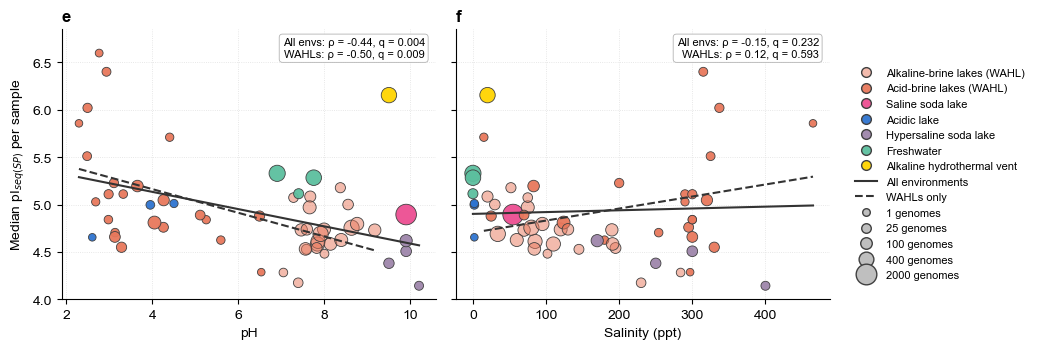

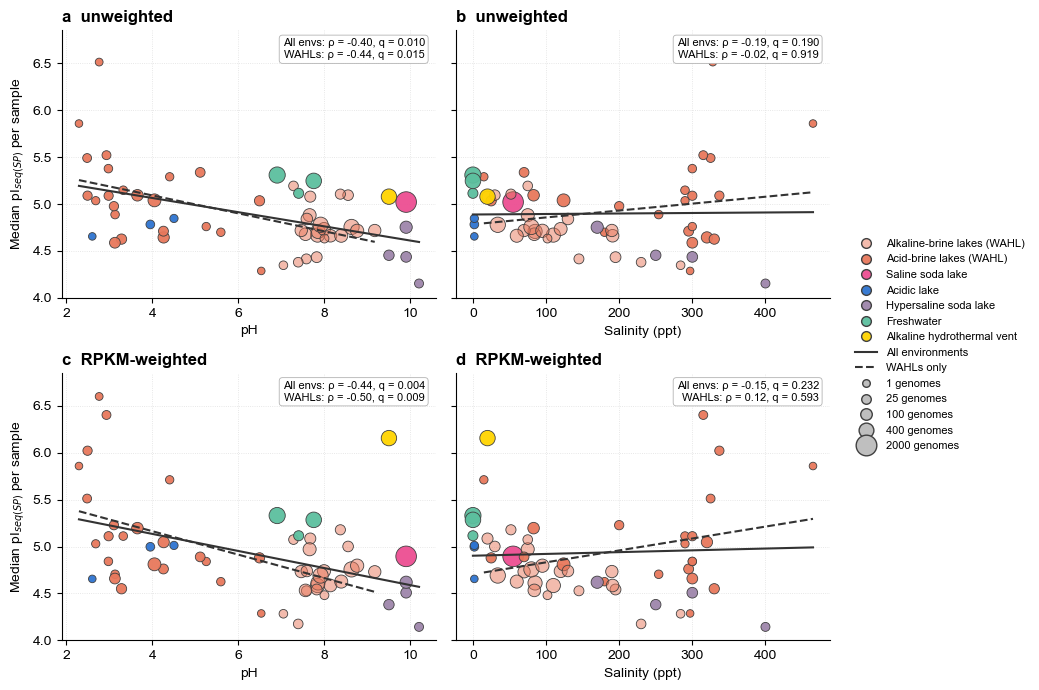

In [40]:
# community median pI vs pH and salinity
# lake-season units, lake as cluster
import warnings
warnings.filterwarnings("ignore", module="statsmodels")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
import statsmodels.formula.api as smf

plt.rcParams.update({"font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "svg.fonttype": "none"})
UNIT = "lake_season"   # "lake_season" or "lake"
CUEVA_POOLED = False
MIN_GENOMES  = 1       # min genomes per sample
DRAW_LAKE_LINES = False

# units
_u = rv.dropna(subset=["pH", "Salinity"]).copy()
if UNIT == "lake":
    _u["Unit"] = _u["Physical_lake"]
elif CUEVA_POOLED:
    _u["Unit"] = _u["Physical_lake"] + " | " + _u["Season"]
else:
    _u["Unit"] = _u["name_full"] + " | " + _u["Season"]
units = unit_pI(_u, unit="Unit")
_meta = (_u.groupby("Unit")
           .agg(pH=("pH", "mean"), Salinity=("Salinity", "mean"),
                Physical_lake=("Physical_lake", "first"), Season=("Season", "first"),
                is_WAHL=("is_WAHL", "any"),
                Environment_Bin=("Environment_Bin", lambda s: s.value_counts().idxmax()))
           .reset_index())
units = units.merge(_meta, on="Unit")
if UNIT == "lake_season" and CUEVA_POOLED:
    _so = site_observations(_u)
    _so["Unit"] = _so["Physical_lake"] + " | " + _so["Season"]
    _lc = _so.groupby("Unit", as_index=False).agg(pH=("pH", "mean"), Salinity=("Salinity", "mean"))
    units = units.drop(columns=["pH", "Salinity"]).merge(_lc, on="Unit")
if UNIT == "lake":
    _lc = lake_chemistry(_u, "mean").rename(columns={"Physical_lake": "Unit"})[["Unit", "pH", "Salinity"]]
    units = units.drop(columns=["pH", "Salinity"]).merge(_lc, on="Unit")
    m = units["is_WAHL"]
    units.loc[m, "Environment_Bin"] = np.where(units.loc[m, "pH"] < 7,
                                               "Acid-brine lakes (WATL)", "Alkaline-brine lakes (WATL)")
units_all = units.copy()
_drop = units[units["n"] < MIN_GENOMES]
if len(_drop):
    print(f"MIN_GENOMES = {MIN_GENOMES}: dropped {len(_drop)} sample(s):")
    print(_drop[["Unit", "n", "pH", "pI_weighted"]].round(3).to_string(index=False))
units = units[units["n"] >= MIN_GENOMES].copy()
n_per_lake = units.groupby("Physical_lake")["Unit"].transform("size")
print(f"{len(units)} sampling units from {units['Physical_lake'].nunique()} lakes "
      f"({int(units['is_WAHL'].sum())} WAHL units from {units.loc[units.is_WAHL, 'Physical_lake'].nunique()} WAHL lakes)")
print("lakes contributing >1 unit:")
print(units[n_per_lake > 1].sort_values(["Physical_lake", "pH"])
      [["Physical_lake", "Unit", "pH", "Salinity", "n", "pI_weighted"]].round(3).to_string(index=False))

# stats
def block_perm_spearman(x, y, lake, n_perm=PERM_N, seed=SEED):
    """Spearman rho; p from permutations that move each lake's samples as a block.
    Lakes exchange chemistry only with lakes contributing the same number of
    samples; a lake that is alone in its size class is shuffled internally."""
    x, y, lake = np.asarray(x, float), np.asarray(y, float), np.asarray(lake)
    rx = rankdata(x); ry = rankdata(y)
    rx -= rx.mean(); ry -= ry.mean()
    den = np.sqrt((rx @ rx) * (ry @ ry))
    rho = float(rx @ ry / den)
    idx = {l: np.where(lake == l)[0] for l in np.unique(lake)}
    by_size = {}
    for l, ii in idx.items(): by_size.setdefault(len(ii), []).append(l)
    rng = np.random.default_rng(seed); hits = 0
    for _ in range(n_perm):
        newx = np.empty_like(rx)
        for k, ls in by_size.items():
            order = rng.permutation(len(ls))
            for dst, src in zip(ls, [ls[o] for o in order]):
                newx[idx[dst]] = rx[idx[src]][rng.permutation(k)]
        hits += abs(newx @ ry / den) >= abs(rho) - 1e-12
    return rho, (hits + 1) / (n_perm + 1)

rows = []
for si, (scope, sub) in enumerate([("All environments", units), ("WAHLs only", units[units["is_WAHL"]])]):
    for wi, (wt, pc) in enumerate([("RPKM-weighted", "pI_weighted"), ("unweighted", "pI_unweighted")]):
        for pi_, pr in enumerate(["pH", "Salinity"]):
            s = sub.dropna(subset=[pc, pr]); sd = SEED + 100 * si + 10 * wi + pi_
            rho, p = block_perm_spearman(s[pr], s[pc], s["Physical_lake"], seed=sd)
            lo, hi = boot_spearman_ci(s[pr], s[pc], clusters=s["Physical_lake"], seed=sd + 1)
            z = s.assign(x=(s[pr] - s[pr].mean()) / s[pr].std(), y=s[pc])
            try:
                mm = smf.mixedlm("y ~ x", z, groups=z["Physical_lake"]).fit(reml=True)
                mb, mp = float(mm.params["x"]), float(mm.pvalues["x"])
            except Exception:
                mb, mp = np.nan, np.nan
            rows.append(dict(analysis=("one point per lake" if UNIT == "lake"
                                       else "lake-season units, lake-aware (primary)"), scope=scope,
                             weighting=wt, predictor=pr, n_units=len(s),
                             n_lakes=s["Physical_lake"].nunique(), rho=rho, p_perm=p,
                             rho_lo=lo, rho_hi=hi, mixed_slope_perSD=mb, mixed_p=mp))
S3 = pd.DataFrame(rows); S3["q_fdr"] = np.nan
for sc in S3["scope"].unique():
    m = S3["scope"].eq(sc)
    S3.loc[m, "q_fdr"] = multipletests(S3.loc[m, "p_perm"], method="fdr_bh")[1]
S3.to_csv(SENS_OUT + "Fig3EF_stats.csv", index=False)
units.to_csv(SENS_OUT + "Fig3EF_unit_data.csv", index=False)
SENS_RESULTS["Fig3EF_stats"] = S3
SENS_RESULTS["Fig3EF_units"] = units
with pd.option_context("display.width", 220):
    print(f"\n=== Fig. 3e,f: UNIT = {UNIT} ===")
    print(S3.round(4).to_string(index=False))

# min genomes sensitivity
sweep = []
for thr in (1, 2, 3, 5, 7, 10):
    ut = units_all[units_all["n"] >= thr]
    for scope, sub in [("All environments", ut), ("WAHLs only", ut[ut["is_WAHL"]])]:
        for wt, pc in [("RPKM-weighted", "pI_weighted"), ("unweighted", "pI_unweighted")]:
            for pr in ("pH", "Salinity"):
                s_ = sub.dropna(subset=[pc, pr])
                if s_["Physical_lake"].nunique() < 4: continue
                r_, p_ = block_perm_spearman(s_[pr], s_[pc], s_["Physical_lake"],
                                             n_perm=1999, seed=SEED + thr)
                sweep.append(dict(min_genomes=thr, scope=scope, weighting=wt, predictor=pr,
                                  n_units=len(s_), n_lakes=s_["Physical_lake"].nunique(),
                                  rho=r_, p_perm=p_))
sweep = pd.DataFrame(sweep); sweep["q_fdr"] = np.nan
for _, m in sweep.groupby(["min_genomes", "scope", "weighting"]).groups.items():
    sweep.loc[m, "q_fdr"] = multipletests(sweep.loc[m, "p_perm"], method="fdr_bh")[1]
SENS_RESULTS["Fig3EF_min_genome_sweep"] = sweep
print("\n=== Sensitivity: minimum genomes per sample (lake-aware p; BH within threshold x scope x weighting) ===")
print(sweep.round(4).to_string(index=False))

# figure
_ymax = float(np.nanmax(units[["pI_weighted", "pI_unweighted"]].to_numpy()))
YLIM = (4, max(6.5, np.ceil(_ymax * 4) / 4 + 0.1))
_FALLBACK = {"hypersaline soda lake": "#8E7CB5", "acid-brine lakes (watl)": "#E0715A",
             "alkaline-brine lakes (watl)": "#F2B8A8", "saline soda lake": "#E04A8F",
             "alkaline hydrothermal vent": "#F5C518", "acidic lake": "#2F6FD0",
             "freshwater": "#4DB89A"}
def _col(e):
    if "env_color" in globals():
        try: return env_color(e)
        except Exception: pass
    return _FALLBACK.get(str(e).strip().lower(), "0.6")
def _rgba(e): return to_rgba(_col(e), 0.5 if "alkaline-brine" in str(e).lower() else 0.95)
def _lab(e):  return str(e).replace("WATL", "WAHL")
def _q(q):    return "q < 0.001" if (np.isfinite(q) and q < 0.001) else f"q = {q:.3f}"

smin, smax = int(units["n"].min()), int(units["n"].max())
def _nice_max(v):
    import math
    e = 10 ** math.floor(math.log10(max(v, 1)))
    return int(math.ceil(v / e) * e)

def _size(n):
    if smax <= smin: return 70
    return 30 + (np.sqrt(n) - np.sqrt(smin)) / (np.sqrt(smax) - np.sqrt(smin)) * (220 - 30)

def plot_ef(panels, fname, figsize):
    idx = S3.set_index(["weighting", "scope", "predictor"])
    nr = 1 if len(panels) == 2 else 2
    fig, axes = plt.subplots(nr, 2, figsize=figsize, sharey=True, squeeze=False)
    for ax, (tag, wt, ycol, pred, xlab) in zip(axes.ravel(), panels):
        sub = units.dropna(subset=[ycol, pred])
        for _, g in (sub.groupby("Physical_lake") if DRAW_LAKE_LINES else []):
            if len(g) > 1:
                g = g.sort_values(pred)
                ax.plot(g[pred].to_numpy(float), g[ycol].to_numpy(float),
                        color="0.55", lw=0.8, zorder=2)
        ax.scatter(sub[pred].to_numpy(float), sub[ycol].to_numpy(float),
                   s=[_size(n) for n in sub["n"]],
                   c=[_rgba(e) for e in sub["Environment_Bin"]],
                   edgecolor="0.25", linewidth=0.6, zorder=3)
        for d2, ls in [(sub, "-"), (sub[sub["is_WAHL"]], "--")]:
            if len(d2) >= 3 and d2[pred].nunique() > 1:
                xv, yv = d2[pred].to_numpy(float), d2[ycol].to_numpy(float)
                z = np.polyfit(xv, yv, 1)
                xs = np.linspace(xv.min(), xv.max(), 100)
                ax.plot(xs, np.polyval(z, xs), color="0.2", lw=1.5, ls=ls, zorder=4)
        txt = []
        for sc, lb in [("All environments", "All envs"), ("WAHLs only", "WAHLs")]:
            r = idx.loc[(wt, sc, pred)]
            txt.append(f"{lb}: \u03c1 = {r.rho:.2f}, {_q(r.q_fdr)}")
        ax.text(0.97, 0.97, "\n".join(txt), transform=ax.transAxes, ha="right", va="top",
                fontsize=8, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", lw=0.6))
        ax.set_ylim(*YLIM); ax.set_xlabel(xlab)
        ax.set_title(tag, loc="left", fontweight="bold")
        ax.grid(ls=":", lw=0.6, color="0.88"); ax.set_axisbelow(True)
        for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
    for a in axes[:, 0]: a.set_ylabel("Median pI$_{seq(SP)}$ per " + ("lake" if UNIT == "lake" else "sample"))
    envs = list(dict.fromkeys(units["Environment_Bin"]))
    ref = sorted(set([smin, _nice_max(smax)] + [v for v in (25, 100, 400) if smin < v < smax]))
    h = ([Line2D([0], [0], marker="o", ls="", mfc=_rgba(e), mec="0.25", ms=7, label=_lab(e)) for e in envs]
         + [Line2D([0], [0], color="0.2", ls="-", label="All environments"),
            Line2D([0], [0], color="0.2", ls="--", label="WAHLs only"),
            ] + ([Line2D([0], [0], color="0.55", lw=0.8, label="Same lake")] if DRAW_LAKE_LINES else [])
         + [Line2D([0], [0], marker="o", ls="", mfc="0.75", mec="0.25", ms=np.sqrt(_size(v)),
                   label=f"{v} genomes") for v in ref])
    fig.legend(handles=h, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(SENS_OUT + fname + ".svg", bbox_inches="tight")
    fig.savefig(SENS_OUT + fname + ".png", dpi=300, bbox_inches="tight")
    plt.show()

plot_ef([("e", "RPKM-weighted", "pI_weighted", "pH", "pH"),
         ("f", "RPKM-weighted", "pI_weighted", "Salinity", "Salinity (ppt)")],
        "Fig3EF_weighted", (8.5, 3.6))
plot_ef([("a  unweighted", "unweighted", "pI_unweighted", "pH", "pH"),
         ("b  unweighted", "unweighted", "pI_unweighted", "Salinity", "Salinity (ppt)"),
         ("c  RPKM-weighted", "RPKM-weighted", "pI_weighted", "pH", "pH"),
         ("d  RPKM-weighted", "RPKM-weighted", "pI_weighted", "Salinity", "Salinity (ppt)")],
        "SuppFig_Fig3EF_weighted_unweighted", (8.5, 7.0))

=== Minimum-genome sweep (lake-aware p; BH within threshold x scope x weighting) ===
 min_genomes            scope     weighting predictor  n_units  n_lakes     rho  p_perm  q_fdr
           1 All environments RPKM-weighted        pH       57       49 -0.4440  0.0035 0.0070
           1 All environments RPKM-weighted  Salinity       57       49 -0.1492  0.2305 0.2305
           1 All environments    unweighted        pH       57       49 -0.4017  0.0065 0.0130
           1 All environments    unweighted  Salinity       57       49 -0.1860  0.1395 0.1395
           1       WAHLs only RPKM-weighted        pH       45       39 -0.5046  0.0015 0.0030
           1       WAHLs only RPKM-weighted  Salinity       45       39  0.1155  0.4375 0.4375
           1       WAHLs only    unweighted        pH       45       39 -0.4447  0.0045 0.0090
           1       WAHLs only    unweighted  Salinity       45       39 -0.0154  0.9145 0.9145
           2 All environments RPKM-weighted        pH       

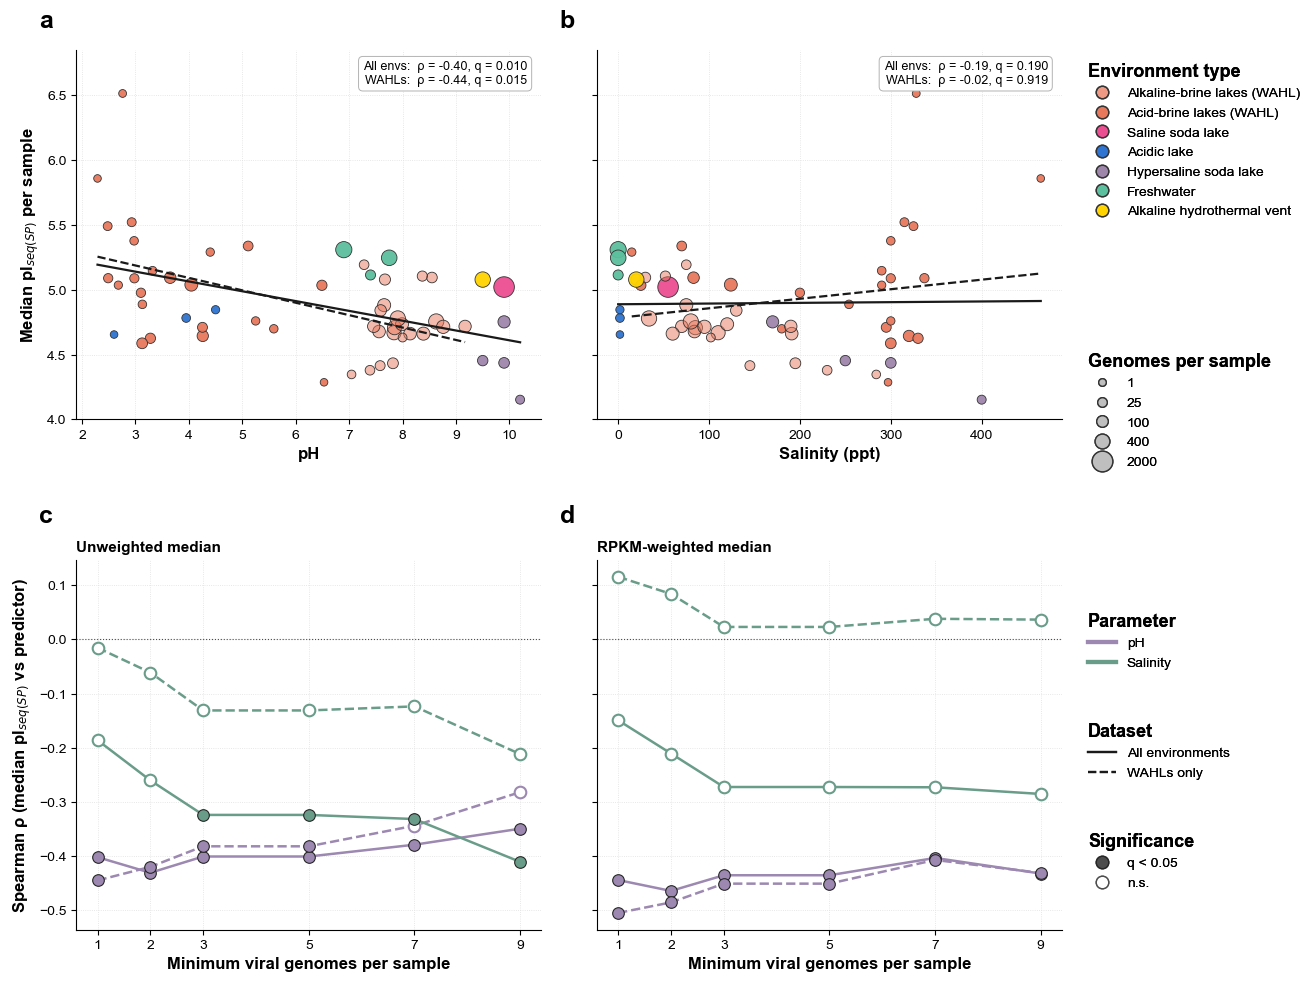

In [41]:
# unweighted scatter + threshold sweep
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

THRESHOLDS = (1, 2, 3, 5, 7, 9)

# sweep
sweep = []
for thr in THRESHOLDS:
    ut = units_all[units_all["n"] >= thr]
    for scope, sub in [("All environments", ut), ("WAHLs only", ut[ut["is_WAHL"]])]:
        for wt, pc in [("RPKM-weighted", "pI_weighted"), ("unweighted", "pI_unweighted")]:
            for pr in ("pH", "Salinity"):
                s_ = sub.dropna(subset=[pc, pr])
                if s_["Physical_lake"].nunique() < 4: continue
                r_, p_ = block_perm_spearman(s_[pr], s_[pc], s_["Physical_lake"],
                                             n_perm=1999, seed=SEED + thr)
                sweep.append(dict(min_genomes=thr, scope=scope, weighting=wt, predictor=pr,
                                  n_units=len(s_), n_lakes=s_["Physical_lake"].nunique(),
                                  rho=r_, p_perm=p_))
sweep = pd.DataFrame(sweep); sweep["q_fdr"] = np.nan
for _, m in sweep.groupby(["min_genomes", "scope", "weighting"]).groups.items():
    sweep.loc[m, "q_fdr"] = multipletests(sweep.loc[m, "p_perm"], method="fdr_bh")[1]
SENS_RESULTS["Fig3EF_min_genome_sweep"] = sweep
print("=== Minimum-genome sweep (lake-aware p; BH within threshold x scope x weighting) ===")
print(sweep.round(4).to_string(index=False))

PCOL = {"pH": "#9C88B0", "Salinity": "#6A9C8A"}
LS = {"All environments": "-", "WAHLs only": "--"}
THR = list(THRESHOLDS)

fig = plt.figure(figsize=(13.5, 10))
gs = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.12, left=0.07, right=0.80, top=0.95, bottom=0.07)
axA = fig.add_subplot(gs[0, 0]); axB = fig.add_subplot(gs[0, 1], sharey=axA)
axC = fig.add_subplot(gs[1, 0]); axD = fig.add_subplot(gs[1, 1], sharey=axC)

# a, b
idx = S3.set_index(["weighting", "scope", "predictor"])
ymax = float(np.nanmax(units["pI_unweighted"]))
for ax, tag, pred, xlab in [(axA, "a", "pH", "pH"), (axB, "b", "Salinity", "Salinity (ppt)")]:
    sub = units.dropna(subset=["pI_unweighted", pred])
    ax.scatter(sub[pred].to_numpy(float), sub["pI_unweighted"].to_numpy(float),
               s=[_size(n) for n in sub["n"]], c=[_rgba(e) for e in sub["Environment_Bin"]],
               edgecolor="0.2", linewidth=0.6, zorder=3)
    for d2, ls in [(sub, "-"), (sub[sub["is_WAHL"]], "--")]:
        xv, yv = d2[pred].to_numpy(float), d2["pI_unweighted"].to_numpy(float)
        if len(xv) >= 3 and np.unique(xv).size > 1:
            z = np.polyfit(xv, yv, 1); xs = np.linspace(xv.min(), xv.max(), 100)
            ax.plot(xs, np.polyval(z, xs), color="0.1", lw=1.6, ls=ls, zorder=4)
    lines = []
    for sc, lb in [("All environments", "All envs:"), ("WAHLs only", "WAHLs:")]:
        r = idx.loc[("unweighted", sc, pred)]
        lines.append(f"{lb}  \u03c1 = {r.rho:.2f}, {_q(r.q_fdr)}")
    ax.text(0.97, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.7", lw=0.7))
    ax.set_xlabel(xlab, fontsize=12, fontweight="bold")
    ax.set_ylim(4, max(6.5, np.ceil(ymax * 4) / 4 + 0.1))
    ax.text(-0.08, 1.06, tag, transform=ax.transAxes, fontsize=18, fontweight="bold")
axA.set_ylabel("Median pI$_{seq(SP)}$ per sample", fontsize=12, fontweight="bold")
plt.setp(axB.get_yticklabels(), visible=False)

# c, d
for ax, tag, wt, title in [(axC, "c", "unweighted", "Unweighted median"),
                           (axD, "d", "RPKM-weighted", "RPKM-weighted median")]:
    sw = sweep[sweep["weighting"] == wt]
    for pr in ("pH", "Salinity"):
        for sc in ("All environments", "WAHLs only"):
            s_ = sw[(sw["predictor"] == pr) & (sw["scope"] == sc)].sort_values("min_genomes")
            x = s_["min_genomes"].to_numpy(float); y = s_["rho"].to_numpy(float)
            sig = (s_["q_fdr"] < 0.05).to_numpy()
            ax.plot(x, y, color=PCOL[pr], ls=LS[sc], lw=1.8, zorder=2)
            ax.scatter(x[sig], y[sig], s=70, color=PCOL[pr], edgecolor="0.15", lw=0.8, zorder=3)
            ax.scatter(x[~sig], y[~sig], s=70, facecolor="white", edgecolor=PCOL[pr], lw=1.5, zorder=3)
    ax.axhline(0, color="0.3", lw=0.8, ls=":")
    ax.set_xticks(THR); ax.set_xlabel("Minimum viral genomes per sample", fontsize=12, fontweight="bold")
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.text(-0.08, 1.10, tag, transform=ax.transAxes, fontsize=18, fontweight="bold")
axC.set_ylabel("Spearman \u03c1 (median pI$_{seq(SP)}$ vs predictor)", fontsize=12, fontweight="bold")
plt.setp(axD.get_yticklabels(), visible=False)

for ax in (axA, axB, axC, axD):
    ax.grid(ls=":", lw=0.6, color="0.88"); ax.set_axisbelow(True)
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)

# legends
envs = list(dict.fromkeys(units["Environment_Bin"]))
h_env = [Line2D([0], [0], marker="o", ls="", mfc=_rgba(e), mec="0.2", ms=9, label=_lab(e)) for e in envs]
ref = sorted(set([smin, _nice_max(smax)] + [v for v in (25, 100, 400) if smin < v < smax]))
h_size = [Line2D([0], [0], marker="o", ls="", mfc="0.75", mec="0.2", ms=np.sqrt(_size(v)), label=str(v)) for v in ref]
h_trend = [Line2D([0], [0], color="0.1", ls="-", lw=1.6, label="All environments"),
           Line2D([0], [0], color="0.1", ls="--", lw=1.6, label="WAHLs only")]
h_par = [Line2D([0], [0], color=PCOL["pH"], lw=3, label="pH"),
         Line2D([0], [0], color=PCOL["Salinity"], lw=3, label="Salinity")]
h_sig = [Line2D([0], [0], marker="o", ls="", mfc="0.3", mec="0.15", ms=9, label="q < 0.05"),
         Line2D([0], [0], marker="o", ls="", mfc="white", mec="0.3", ms=9, label="n.s.")]
kw = dict(frameon=False, fontsize=10, title_fontsize=13)
for handles, title, yy in [(h_env, "Environment type", 0.95), (h_size, "Genomes per sample", 0.66)]:
    leg = fig.legend(handles=handles, title=title, loc="upper left", bbox_to_anchor=(0.81, yy), **kw)
    leg.get_title().set_fontweight("bold"); leg._legend_box.align = "left"; fig.add_artist(leg)
for handles, title, yy in [(h_par, "Parameter", 0.40), (h_trend, "Dataset", 0.29), (h_sig, "Significance", 0.18)]:
    leg = fig.legend(handles=handles, title=title, loc="upper left", bbox_to_anchor=(0.81, yy), **kw)
    leg.get_title().set_fontweight("bold"); leg._legend_box.align = "left"; fig.add_artist(leg)

fig.savefig(SENS_OUT + "SuppFig3.svg", bbox_inches="tight")
fig.savefig(SENS_OUT + "SuppFig3.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
# comparator checks, lake-season units
import warnings, re
warnings.filterwarnings("ignore", module="statsmodels")

# perturbation ranges from the earlier cell if run
if "PERTURB" not in globals():
    PERTURB = {
        "Malaren B":     dict(pH=(6.9, 9.0), Salinity=(0.02, 0.30)),
        "Lake Soyang":   dict(pH=(6.5, 9.0), Salinity=(0.01, 0.10)),
        "Lake Victoria": dict(pH=(6.9, 9.0), Salinity=(0.03, 0.15)),
    }
    DEFAULT_PH_PM, DEFAULT_SAL_FRAC = 0.5, 0.25

N_DRAW_RHO  = 2000
N_DRAW_P    = 200
N_PERM_DRAW = 999    # ~30 s

U0 = units.copy()

def corr_table_units(tab, label, pi_cols=("pI_weighted", "pI_unweighted"),
                     preds=("pH", "Salinity"), seed=SEED,
                     n_perm=PERM_N, n_boot=BOOT_N):
    """corr_table(), but units are lake-season samples and the physical lake
    is the cluster for both the permutation p and the bootstrap CI."""
    rows = []
    for si, (scope, sub) in enumerate([("All environments", tab),
                                       ("WAHLs only", tab[tab["is_WAHL"].astype(bool)])]):
        for wi, pc in enumerate(pi_cols):
            for pi_, pr in enumerate(preds):
                s = sub.dropna(subset=[pc, pr])
                if s["Physical_lake"].nunique() < 4:
                    continue
                sd = seed + 100 * si + 10 * wi + pi_
                rho, p = block_perm_spearman(s[pr], s[pc], s["Physical_lake"],
                                             n_perm=n_perm, seed=sd)
                lo, hi = boot_spearman_ci(s[pr], s[pc], n_boot=n_boot, seed=sd + 1,
                                          clusters=s["Physical_lake"])
                rows.append(dict(analysis=label, scope=scope,
                                 weighting="RPKM-weighted" if pc == "pI_weighted" else "unweighted",
                                 predictor=pr, n_units=len(s),
                                 n_lakes=s["Physical_lake"].nunique(),
                                 rho=rho, p_perm=p, rho_lo=lo, rho_hi=hi))
    R = pd.DataFrame(rows)
    R["q_fdr"] = np.nan
    for sc in R["scope"].unique():
        m = R["scope"].eq(sc) & R["p_perm"].notna()
        if m.any():
            R.loc[m, "q_fdr"] = multipletests(R.loc[m, "p_perm"], method="fdr_bh")[1]
    return R

resU = []

# Cueva de la Mora
cue = U0[U0["Physical_lake"] == CUEVA_KEY]
oth = U0[U0["Physical_lake"] != CUEVA_KEY]
resU.append(corr_table_units(U0, "Cueva: three layers as separate units (primary)"))
if len(cue):
    print(f"Cueva contributes {len(cue)} unit(s) to the primary frame:")
    print(cue[["Unit", "pH", "Salinity", "n", "pI_weighted"]].round(3).to_string(index=False))
    crows = rv[rv["Physical_lake"] == CUEVA_KEY]
    cp = unit_pI(crows, unit="Physical_lake")
    _so = site_observations(crows)
    cp["pH"] = float(_so["pH"].mean())
    cp["Salinity"] = float(_so["Salinity"].mean())
    cp["is_WAHL"] = False
    cp["Environment_Bin"] = cue["Environment_Bin"].iloc[0]
    cp["Unit"] = CUEVA_KEY
    cp["Season"] = "single"
    resU.append(corr_table_units(pd.concat([oth, cp], ignore_index=True),
                                 "Cueva: layers pooled into one unit"))
    resU.append(corr_table_units(oth, "Cueva excluded"))
    for _, r in cue.iterrows():
        short = re.sub(r".*-\s*", "", str(r["Unit"]).split(" | ")[0])
        one = (pd.concat([oth, r.to_frame().T], ignore_index=True)
                 .astype({"pI_weighted": float, "pI_unweighted": float,
                          "pH": float, "Salinity": float, "is_WAHL": bool}))
        resU.append(corr_table_units(one, f"Cueva: only {short}"))

# drop comparator classes
resU.append(corr_table_units(U0[U0["Environment_Bin"] != "Freshwater"],
                             "freshwater lakes excluded"))
single_site = [b for b, n in U0.groupby("Environment_Bin")["Physical_lake"].nunique().items()
               if n == 1 and "WATL" not in str(b).upper()]
if single_site:
    resU.append(corr_table_units(U0[~U0["Environment_Bin"].isin(single_site)],
                                 f"single-site classes excluded ({', '.join(single_site)})"))

# leave-one-site-out
comparatorsU = sorted(U0.loc[~U0["is_WAHL"].astype(bool), "Physical_lake"].unique())
looU = []
for lk in comparatorsU:
    R = corr_table_units(U0[U0["Physical_lake"] != lk], f"leave out {lk}",
                         n_perm=1999, n_boot=500)
    looU.append(R[R["scope"] == "All environments"])
looU = pd.concat(looU, ignore_index=True) if looU else pd.DataFrame()

# perturbation
def _ranges_u(row):
    if row["Physical_lake"] in PERTURB:
        return PERTURB[row["Physical_lake"]]
    s = float(row["Salinity"])
    return dict(pH=(float(row["pH"]) - DEFAULT_PH_PM, float(row["pH"]) + DEFAULT_PH_PM),
                Salinity=(max(0.0, s * (1 - DEFAULT_SAL_FRAC)), s * (1 + DEFAULT_SAL_FRAC)))

ptU = U0.reset_index(drop=True).copy()
comp_idxU = np.where(~ptU["is_WAHL"].astype(bool).to_numpy())[0]
rngsU = {int(i): _ranges_u(ptU.loc[i]) for i in comp_idxU}
fresh_idxU = np.array([i for i in comp_idxU if ptU.loc[i, "Physical_lake"] in PERTURB], dtype=int)
lakesU = ptU["Physical_lake"].to_numpy()
rngU = np.random.default_rng(SEED)

drawsU = []
for scen, idxs in [("all comparators", comp_idxU), ("freshwater only", fresh_idxU)]:
    for d in range(N_DRAW_RHO):
        ph = ptU["pH"].to_numpy(float).copy()
        sal = ptU["Salinity"].to_numpy(float).copy()
        for i in idxs:
            r = rngsU[int(i)]
            ph[i] = rngU.uniform(*r["pH"])
            sal[i] = rngU.uniform(*r["Salinity"])
        for pc in ("pI_weighted", "pI_unweighted"):
            y = ptU[pc].to_numpy(float)
            for pr, x in (("pH", ph), ("Salinity", sal)):
                ok = np.isfinite(x) & np.isfinite(y)
                rr = spearmanr(x[ok], y[ok])
                lake_p = np.nan
                if pr == "pH" and d < N_DRAW_P:
                    _, lake_p = block_perm_spearman(x[ok], y[ok], lakesU[ok],
                                                    n_perm=N_PERM_DRAW, seed=SEED + d)
                drawsU.append((scen, pc, pr, float(rr.statistic), float(rr.pvalue), lake_p))

DU = pd.DataFrame(drawsU, columns=["perturbed", "pI", "predictor", "rho", "p_asymptotic", "p_lake_aware"])
perturb_summary_u = (DU.groupby(["perturbed", "pI", "predictor"])
                       .agg(rho_median=("rho", "median"),
                            rho_2_5=("rho", lambda v: np.percentile(v, 2.5)),
                            rho_97_5=("rho", lambda v: np.percentile(v, 97.5)),
                            frac_p_lt_0_05=("p_asymptotic", lambda v: float(np.mean(v < 0.05))),
                            p_max=("p_asymptotic", "max"),
                            n_lake_aware=("p_lake_aware", lambda v: int(v.notna().sum())),
                            frac_lake_p_lt_0_05=("p_lake_aware",
                                                 lambda v: float(np.mean(v.dropna() < 0.05))
                                                 if v.notna().any() else np.nan),
                            p_lake_max=("p_lake_aware", "max"))
                       .reset_index())

# worst case
wcU = U0.copy()
for lk, r in PERTURB.items():
    m = wcU["Physical_lake"] == lk
    wcU.loc[m, "pH"] = r["pH"][1]
    wcU.loc[m, "Salinity"] = r["Salinity"][1]
resU.append(corr_table_units(wcU, "worst case: freshwater at upper end of pH/salinity range"))

comparator_results_lakeseason = pd.concat(resU, ignore_index=True)
SENS_RESULTS["cueva_and_comparators_lakeseason"] = comparator_results_lakeseason
SENS_RESULTS["leave_one_site_out_lakeseason"]    = looU
SENS_RESULTS["perturbation_summary_lakeseason"]  = perturb_summary_u

comparator_results_lakeseason.to_csv(SENS_OUT + "comparators_lakeseason.csv", index=False)
looU.to_csv(SENS_OUT + "leave_one_site_out_lakeseason.csv", index=False)
perturb_summary_u.to_csv(SENS_OUT + "perturbation_lakeseason.csv", index=False)

with pd.option_context("display.width", 220, "display.max_colwidth", 80):
    print("\n=== Lake-season frame: Cueva / comparator-class / worst case ===")
    print(comparator_results_lakeseason.round(4).to_string(index=False))
    print("\n=== Lake-season frame: Leave-one-comparator-site-out (all environments) ===")
    print(looU.round(4).to_string(index=False))
    print(f"\n=== Lake-season frame: Perturbation ({N_DRAW_RHO} draws; "
          f"lake-aware p on the first {N_DRAW_P} pH draws) ===")
    print(perturb_summary_u.round(4).to_string(index=False))


Cueva contributes 3 unit(s) to the primary frame:
                                                    Unit   pH  Salinity  n  pI_weighted
       Cueva de la Mora lake - Chemocline (11m) | single 3.95       2.0 10        4.997
Cueva de la Mora lake - Deep Anoxic Layer (35m) | single 4.50       2.0  5        5.011
  Cueva de la Mora lake - Upper Oxic Layer (3m) | single 2.60       2.0  1        4.655

=== Lake-season frame: Cueva / comparator-class / worst case ===
                                                                                analysis            scope     weighting predictor  n_units  n_lakes     rho  p_perm  rho_lo  rho_hi  q_fdr
                                         Cueva: three layers as separate units (primary) All environments RPKM-weighted        pH       57       49 -0.4440  0.0011 -0.6511 -0.1667 0.0044
                                         Cueva: three layers as separate units (primary) All environments RPKM-weighted  Salinity       57       49 -0.1492  0

## Supplementary Fig. 4


Viruses retained across all environments:
host_group_sensitivity
Halophilic Archaea                      128
Bacteria or Archaea                    6777
Bacteria and Archaea                    172
Bacteria                                920
Other Archaea                            11
Eukarya (giant viruses)                  69
Eukarya (vertebrates/invertebrates)       6

All environments — lakes represented by host group:
host_group_sensitivity
Halophilic Archaea                     17
Bacteria or Archaea                    48
Bacteria and Archaea                   20
Bacteria                               44
Other Archaea                           7
Eukarya (giant viruses)                17
Eukarya (vertebrates/invertebrates)     5

WAHL only — lakes represented by host group:
host_group_sensitivity
Halophilic Archaea                     13
Bacteria or Archaea                    38
Bacteria and Archaea                   16
Bacteria                               34
Other Archaea      

,scope,weighting,threshold,host_group,predictor,n_lakes,n_viruses_total,rho,p_raw,q_fdr
63,All environments,RPKM-weighted median,1,Bacteria,Salinity,43,918,0.0830,0.5969,0.8099
77,All environments,RPKM-weighted median,2,Bacteria,Salinity,33,908,-0.1771,0.3243,0.4053
91,All environments,RPKM-weighted median,3,Bacteria,Salinity,31,904,-0.1810,0.3300,0.4888
105,All environments,RPKM-weighted median,5,Bacteria,Salinity,23,875,-0.4033,0.0564,0.0752
61,All environments,RPKM-weighted median,1,Bacteria and Archaea,Salinity,20,172,-0.3782,0.1002,0.2824
...,...,...,...,...,...,...,...,...,...,...
154,WAHL only,Unweighted median,5,Halophilic Archaea,pH,9,101,-0.1617,0.6776,0.6776
120,WAHL only,Unweighted median,1,Other Archaea,pH,3,3,NaN,NaN,NaN
134,WAHL only,Unweighted median,2,Other Archaea,pH,0,0,NaN,NaN,NaN
148,WAHL only,Unweighted median,3,Other Archaea,pH,0,0,NaN,NaN,NaN



Saved:
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_host_sensitivity_all_and_WAHL_tests.csv
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_host_sensitivity_all_and_WAHL_lake_inputs.csv
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_host_sensitivity_all_and_WAHL.xlsx


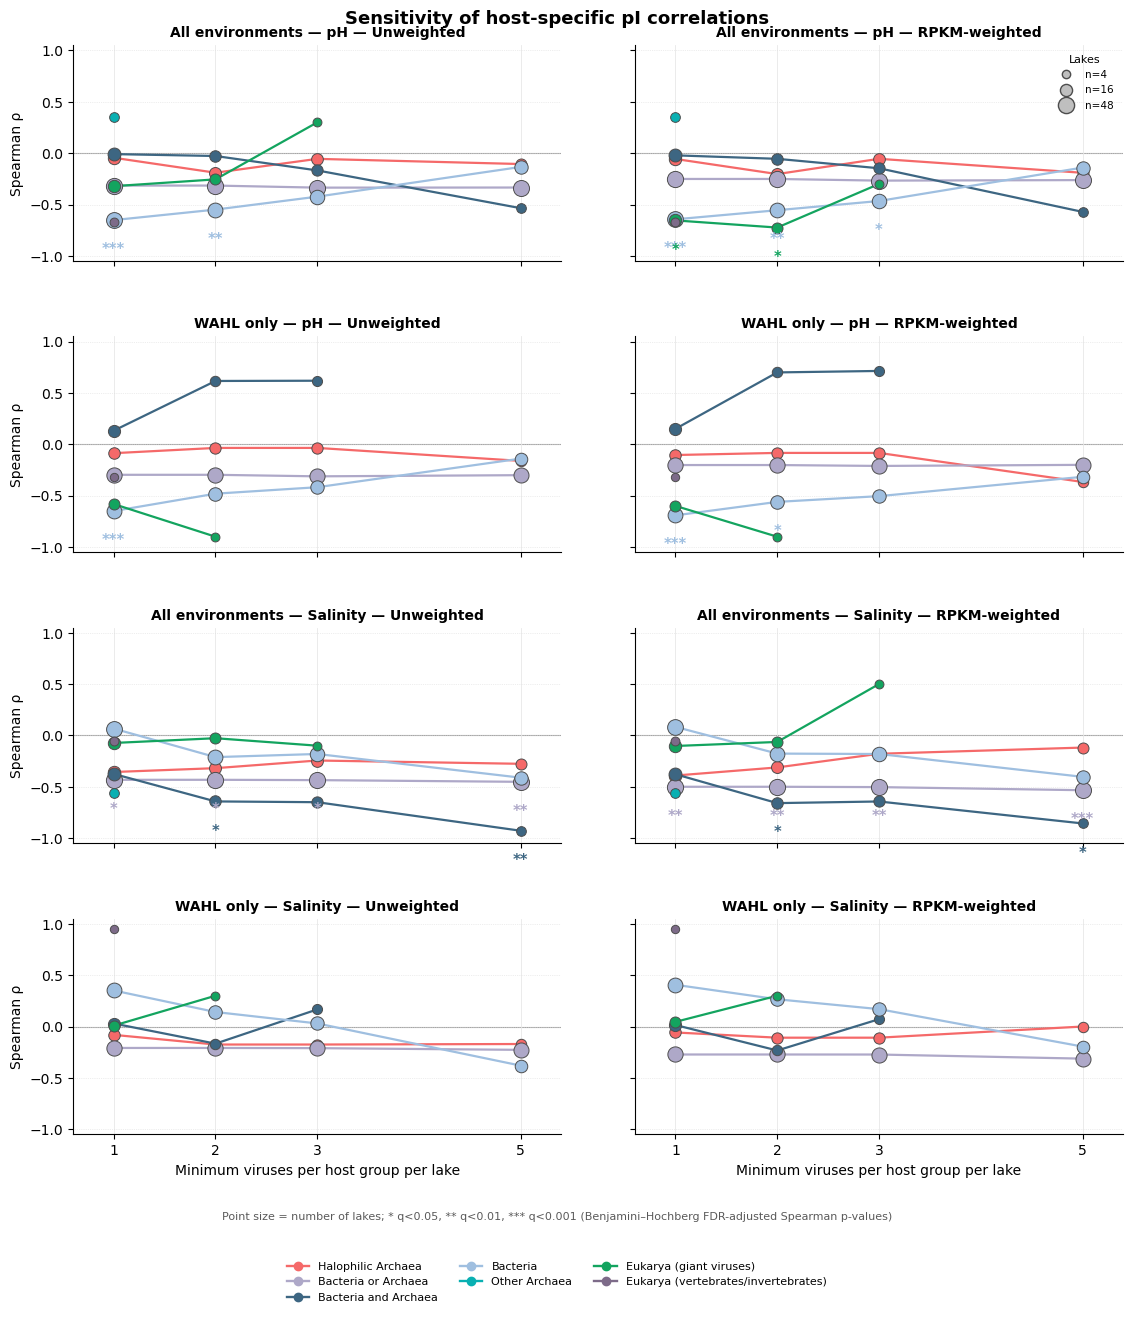


Saved:
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_all_and_WAHL_host_sensitivity_FDR.png
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_all_and_WAHL_host_sensitivity_FDR.svg


In [43]:
# host group threshold sweep
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D
from IPython.display import display

OUTDIR = "/Users/skoog/Desktop/Revisions/"
os.makedirs(OUTDIR,exist_ok=True)
plt.rcParams.update({"font.family":"DejaVu Sans","svg.fonttype":"none","text.usetex":False})

PICOL,WEIGHT_COL = "Median_pI","rpkm"
THRESHOLDS = (1,2,3,5)
MIN_LAKES_FOR_TEST = 4
SCOPES = ("All environments","WAHL only")
WEIGHTINGS = ("Unweighted median","RPKM-weighted median")

SENS_GROUPS = (
    "Halophilic Archaea",
    "Bacteria or Archaea",
    "Bacteria and Archaea",
    "Bacteria",
    "Other Archaea",
    "Eukarya (giant viruses)",
    "Eukarya (vertebrates/invertebrates)"
)

DEFAULT_HOST_COLORS = {
    "Halophilic Archaea":"#FF6868",
    "Bacteria or Archaea":"#AEA8C8",
    "Bacteria and Archaea":"#416A82",
    "Bacteria":"#9FC2E3",
    "Other Archaea":"#11B4B2",
    "Eukarya (giant viruses)":"#12A45D",
    "Eukarya (vertebrates/invertebrates)":"#7D6B89"
}

_existing_palette = globals().get("HOST_COLORS",globals().get("HOST_PALETTE",{}))
HOST_COLORS_SENS = {g:_existing_palette.get(g,DEFAULT_HOST_COLORS[g]) for g in SENS_GROUPS}

def _normalize_host(value):
    value = str(value).strip()
    return {
        "Eukarya (vertebrates/ invertebrates)":"Eukarya (vertebrates/invertebrates)",
        "Eukarya (vertebrates / invertebrates)":"Eukarya (vertebrates/invertebrates)",
        "Thermophilic Archaea":"Other Archaea",
        "Methanogen Archaea":"Other Archaea"
    }.get(value,value)

def _is_true(value):
    if pd.isna(value): return False
    if isinstance(value,(bool,np.bool_)): return bool(value)
    return str(value).strip().lower() in {"true","1","yes","y"}

def _safe_median(values):
    values = pd.to_numeric(pd.Series(values),errors="coerce").dropna().to_numpy(float)
    return float(np.median(values)) if len(values) else np.nan

def _weighted_median(values,weights):
    values,weights = np.asarray(values,float),np.asarray(weights,float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values,weights = values[keep],weights[keep]
    if not len(values): return np.nan
    order = np.argsort(values)
    values,weights = values[order],weights[order]
    cumulative = (np.cumsum(weights)-0.5*weights)/weights.sum()
    return float(np.interp(0.5,cumulative,values))

def _sens_group_iphop(row):
    if not _is_true(row.get("has_iphop",False)): return np.nan

    direct = np.nan
    if callable(globals().get("_host_group_iphop")):
        try: direct = _normalize_host(_host_group_iphop(row))
        except Exception: direct = np.nan

    ecology = _normalize_host(row.get("Host_ecology",row.get("Host_broad","Unknown/Other")))
    existing = _normalize_host(row.get("Host_group","Unknown/Other"))
    domain = str(row.get("host_domain","")).strip()
    phylum = str(row.get("host_phylum","")).strip()

    if direct in SENS_GROUPS: return direct
    if direct == "Bacteria" or domain == "Bacteria": return "Bacteria"
    if direct in {"Archaea","Other Archaea"} or domain == "Archaea":
        return "Halophilic Archaea" if phylum == "Halobacteriota" else "Other Archaea"
    if direct == "Eukarya" or domain in {"Eukarya","Eukaryota"}:
        if ecology in {"Eukarya (giant viruses)","Eukarya (vertebrates/invertebrates)"}: return ecology
        if existing in {"Eukarya (giant viruses)","Eukarya (vertebrates/invertebrates)"}: return existing
        return "Eukarya (giant viruses)"
    return np.nan

def _sens_group_combined(row):
    if _is_true(row.get("has_iphop",False)):
        return _sens_group_iphop(row)

    family = str(row.get("family","")).strip().casefold()
    ecology = _normalize_host(row.get("Host_ecology",row.get("Host_broad","Unknown/Other")))
    existing = _normalize_host(row.get("Host_group","Unknown/Other"))

    if family == "unclassified caudoviricetes": return "Bacteria or Archaea"
    if ecology == "Halophilic Archaea": return "Halophilic Archaea"
    if ecology in {"Thermophilic Archaea","Other Archaea","Methanogen Archaea"}: return "Other Archaea"
    if ecology == "Bacteria": return "Bacteria"
    if ecology == "Eukarya (giant viruses)": return "Eukarya (giant viruses)"
    if ecology == "Eukarya (vertebrates/invertebrates)": return "Eukarya (vertebrates/invertebrates)"
    if ecology in {"Bacteria and Archaea","Bacteria or Archaea"}: return ecology
    if existing in SENS_GROUPS: return existing
    return np.nan

def _prepare_sensitivity_data(host_df):
    d = host_df.copy()
    required = [PICOL,"pH","Salinity",WEIGHT_COL,"family","has_iphop",
                "Host_group","Environment_Bin","name_full"]
    missing = [c for c in required if c not in d.columns]
    if missing: raise KeyError(f"Missing required columns: {missing}")

    if "Host_ecology" not in d.columns:
        if isinstance(globals().get("host_ecology"),dict):
            d["Host_ecology"] = d["family"].astype(str).str.strip().map(host_ecology).fillna("Unknown/Other")
        elif "Host_broad" in d.columns:
            d["Host_ecology"] = d["Host_broad"]
        else:
            d["Host_ecology"] = "Unknown/Other"

    for c in [PICOL,"pH","Salinity",WEIGHT_COL]:
        d[c] = pd.to_numeric(d[c],errors="coerce")

    d["host_group_sensitivity"] = d.apply(_sens_group_combined,axis=1)
    d = d[d["host_group_sensitivity"].isin(SENS_GROUPS)].copy()
    d = d.dropna(subset=[PICOL,"name_full","host_group_sensitivity"])

    # physical lake
    if "physical_lake" in globals():
        _pl = physical_lake
    else:
        import re as _re
        _ALIASES = {"Sunrise Hill": "Sunrise Hill Lake"}
        def _pl(name):
            t = _re.sub(r"\s+", " ", str(name)).strip()
            if "cueva de la mora" in t.lower(): return "Cueva de la Mora"
            return _ALIASES.get(t, t)
    d["Physical_lake"] = d["name_full"].map(_pl)

    id_col = next((c for c in ["contig_id","virus_id","genome_id","sequence_id"] if c in d.columns),None)
    if id_col: d = d.drop_duplicates(subset=[id_col,"Physical_lake"])

    print("\nViruses retained across all environments:")
    print(d["host_group_sensitivity"].value_counts().reindex(SENS_GROUPS,fill_value=0).to_string())
    return d

def _subset_scope(d,scope):
    if scope == "All environments": return d.copy()
    if scope == "WAHL only":
        return d[d["Environment_Bin"].astype(str).str.upper()
                 .str.contains("WATL|WAHL",regex=True,na=False)].copy()
    raise ValueError(f"Unknown scope: {scope}")

def _summarize_host_lakes(d,weighting):
    rows = []
    for (group,lake),g in d.groupby(["host_group_sensitivity","Physical_lake"],sort=False):
        pi = _safe_median(g[PICOL]) if weighting == "Unweighted median" else \
             _weighted_median(g[PICOL].to_numpy(float),g[WEIGHT_COL].to_numpy(float))

        rows.append({
            "host_group":group,
            "name_full":lake,
            "weighting":weighting,
            "pI":pi,
            "pH":float(g.drop_duplicates("name_full")["pH"].mean()),
            "Salinity":float(g.drop_duplicates("name_full")["Salinity"].mean()),
            "n_viruses":int(len(g)),
            "total_RPKM":float(g[WEIGHT_COL].where(g[WEIGHT_COL] > 0).sum())
        })

    out = pd.DataFrame(rows)
    return out.dropna(subset=["pI"]).reset_index(drop=True) if len(out) else out

def build_sensitivity_sweep(host_df):
    prepared = _prepare_sensitivity_data(host_df)
    test_rows,lake_frames = [],[]

    for scope in SCOPES:
        scoped = _subset_scope(prepared,scope)

        print(f"\n{scope} — lakes represented by host group:")
        print(scoped.groupby("host_group_sensitivity")["Physical_lake"].nunique()
              .reindex(SENS_GROUPS,fill_value=0).to_string())

        for weighting in WEIGHTINGS:
            lake_all = _summarize_host_lakes(scoped,weighting)
            if lake_all.empty: continue

            lake_all.insert(0,"scope",scope)
            lake_all.insert(1,"scheme","iPHoP-prioritized + family-inferred")

            for threshold in THRESHOLDS:
                lake_all[f"eligible_n{threshold}"] = lake_all["n_viruses"] >= threshold

            lake_frames.append(lake_all)

            for threshold in THRESHOLDS:
                eligible = lake_all[lake_all["n_viruses"] >= threshold]

                for group in SENS_GROUPS:
                    group_data = eligible[eligible["host_group"] == group]

                    for predictor in ("pH","Salinity"):
                        test = group_data.dropna(subset=["pI",predictor])
                        n_lakes,rho,p_raw = len(test),np.nan,np.nan

                        if n_lakes >= MIN_LAKES_FOR_TEST and test["pI"].nunique() > 1 and test[predictor].nunique() > 1:
                            result = spearmanr(test["pI"].to_numpy(float),test[predictor].to_numpy(float))
                            rho,p_raw = float(result.statistic),float(result.pvalue)

                        test_rows.append({
                            "scope":scope,
                            "scheme":"iPHoP-prioritized + family-inferred",
                            "weighting":weighting,
                            "threshold":threshold,
                            "host_group":group,
                            "predictor":predictor,
                            "n_lakes":int(n_lakes),
                            "n_viruses_total":int(test["n_viruses"].sum()) if n_lakes else 0,
                            "minimum_viruses_per_lake":int(test["n_viruses"].min()) if n_lakes else np.nan,
                            "median_viruses_per_lake":float(test["n_viruses"].median()) if n_lakes else np.nan,
                            "maximum_viruses_per_lake":int(test["n_viruses"].max()) if n_lakes else np.nan,
                            "lake_virus_counts":"; ".join(
                                f"{r.name_full}:{int(r.n_viruses)}"
                                for r in test.sort_values("name_full").itertuples()
                            ),
                            "rho":rho,
                            "p_raw":p_raw
                        })

    tests = pd.DataFrame(test_rows)
    lakes = pd.concat(lake_frames,ignore_index=True) if lake_frames else pd.DataFrame()
    tests["q_fdr"] = np.nan

    # BH within scope x weighting x threshold x predictor
    for _,idx in tests.groupby(["scope","weighting","threshold","predictor"]).groups.items():
        idx = np.asarray(list(idx),int)
        p = tests.loc[idx,"p_raw"].to_numpy(float)
        valid = np.isfinite(p)

        if valid.any():
            tests.loc[idx[valid],"q_fdr"] = multipletests(
                p[valid],method="fdr_bh"
            )[1]

    test_csv = os.path.join(OUTDIR,"Supplementary_Fig5_host_sensitivity_all_and_WAHL_tests.csv")
    lake_csv = os.path.join(OUTDIR,"Supplementary_Fig5_host_sensitivity_all_and_WAHL_lake_inputs.csv")
    xlsx = os.path.join(OUTDIR,"Supplementary_Fig5_host_sensitivity_all_and_WAHL.xlsx")

    tests.to_csv(test_csv,index=False)
    lakes.to_csv(lake_csv,index=False)

    with pd.ExcelWriter(xlsx,engine="openpyxl") as writer:
        tests.to_excel(writer,sheet_name="sensitivity_tests",index=False)
        lakes.to_excel(writer,sheet_name="lake_level_inputs",index=False)
        tests[tests["scope"] == "All environments"].to_excel(
            writer,sheet_name="all_environment_tests",index=False
        )
        tests[tests["scope"] == "WAHL only"].to_excel(
            writer,sheet_name="WAHL_tests",index=False
        )

    display(
        tests[["scope","weighting","threshold","host_group","predictor",
               "n_lakes","n_viruses_total","rho","p_raw","q_fdr"]]
        .sort_values(["scope","predictor","weighting","host_group","threshold"])
        .round(4)
    )

    print("\nSaved:")
    print(test_csv)
    print(lake_csv)
    print(xlsx)
    return tests,lakes

def _q_stars(q):
    if pd.isna(q): return ""
    if q < 0.001: return "***"
    if q < 0.01: return "**"
    if q < 0.05: return "*"
    return ""

def plot_sensitivity_sweep(tests,out_stem):
    plot_data = tests.copy()
    valid_n = plot_data.loc[
        plot_data["rho"].notna() & (plot_data["n_lakes"] > 0),"n_lakes"
    ].to_numpy(float)

    n_min = int(np.nanmin(valid_n)) if len(valid_n) else 1
    n_max = int(np.nanmax(valid_n)) if len(valid_n) else 1

    def point_size(n):
        if n_max <= n_min: return 65
        scaled = (np.sqrt(float(n))-np.sqrt(n_min))/(np.sqrt(n_max)-np.sqrt(n_min))
        return 36+100*scaled

    specs = [
        ("All environments","pH","Unweighted median"),
        ("All environments","pH","RPKM-weighted median"),
        ("WAHL only","pH","Unweighted median"),
        ("WAHL only","pH","RPKM-weighted median"),
        ("All environments","Salinity","Unweighted median"),
        ("All environments","Salinity","RPKM-weighted median"),
        ("WAHL only","Salinity","Unweighted median"),
        ("WAHL only","Salinity","RPKM-weighted median")
    ]

    fig,axes = plt.subplots(4,2,figsize=(11.8,13.2),sharex=True,sharey=True)

    for ax,(scope,predictor,weighting) in zip(axes.flat,specs):
        panel = plot_data[
            (plot_data["scope"] == scope) &
            (plot_data["predictor"] == predictor) &
            (plot_data["weighting"] == weighting)
        ]

        ax.axhline(0,color="0.65",lw=0.8,zorder=0)
        for threshold in THRESHOLDS:
            ax.axvline(threshold,color="0.91",lw=0.6,zorder=0)

        for group in SENS_GROUPS:
            g = panel[panel["host_group"] == group].sort_values("threshold").dropna(subset=["rho"])
            if g.empty: continue

            x = g["threshold"].to_numpy(float)
            y = g["rho"].to_numpy(float)
            color = HOST_COLORS_SENS[group]
            ax.plot(x,y,color=color,lw=1.6,zorder=2)

            for r in g.itertuples():
                ax.scatter(
                    float(r.threshold),float(r.rho),
                    s=point_size(r.n_lakes),
                    marker="o",
                    facecolor=color,
                    edgecolor="0.3",
                    lw=0.7,
                    zorder=4
                )

                stars = _q_stars(r.q_fdr)
                if stars:
                    offset = 8 if r.rho >= 0 else -15
                    va = "bottom" if r.rho >= 0 else "top"

                    ax.annotate(
                        stars,
                        (float(r.threshold),float(r.rho)),
                        xytext=(0,offset),
                        textcoords="offset points",
                        ha="center",
                        va=va,
                        fontsize=10.5,
                        fontweight="bold",
                        color=color,
                        clip_on=False,
                        zorder=6
                    )

        ax.set_title(
            f"{scope} — {predictor} — {weighting.replace(' median','')}",
            fontsize=10,
            fontweight="bold"
        )
        ax.set_xticks(THRESHOLDS)
        ax.set_xlim(0.6,5.4)
        ax.set_ylim(-1.05,1.05)
        ax.grid(axis="y",ls=":",lw=0.5,color="0.87")
        ax.set_axisbelow(True)

        for spine in ("top","right"):
            ax.spines[spine].set_visible(False)

    for row in range(4):
        axes[row,0].set_ylabel("Spearman ρ")

    axes[3,0].set_xlabel("Minimum viruses per host group per lake")
    axes[3,1].set_xlabel("Minimum viruses per host group per lake")

    host_handles = [
        Line2D([],[],color=HOST_COLORS_SENS[g],marker="o",lw=1.7,ms=6,label=g)
        for g in SENS_GROUPS
    ]

    fig.legend(
        handles=host_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=8,
        bbox_to_anchor=(0.5,0.005)
    )

    if len(valid_n):
        refs = sorted(set([
            int(np.nanmin(valid_n)),
            int(np.nanmedian(valid_n)),
            int(np.nanmax(valid_n))
        ]))

        axes[0,1].legend(
            handles=[
                Line2D(
                    [],[],
                    marker="o",
                    ls="None",
                    markersize=np.sqrt(point_size(n)),
                    markerfacecolor="0.75",
                    markeredgecolor="0.3",
                    label=f"n={n}"
                )
                for n in refs
            ],
            title="Lakes",
            loc="upper right",
            frameon=False,
            fontsize=7.5,
            title_fontsize=8
        )

    fig.suptitle(
        "Sensitivity of host-specific pI correlations",
        fontsize=13,
        fontweight="bold",
        y=0.992
    )

    fig.text(
        0.5,0.075,
        "Point size = number of lakes; * q<0.05, ** q<0.01, *** q<0.001 "
        "(Benjamini–Hochberg FDR-adjusted Spearman p-values)",
        ha="center",
        fontsize=8,
        color="0.35"
    )

    fig.subplots_adjust(
        left=0.09,
        right=0.98,
        top=0.965,
        bottom=0.14,
        wspace=0.15,
        hspace=0.35
    )

    png_path = out_stem+".png"
    svg_path = out_stem+".svg"

    fig.savefig(png_path,dpi=300,bbox_inches="tight")
    fig.savefig(svg_path,format="svg",bbox_inches="tight")
    plt.show()

    print("\nSaved:")
    print(png_path)
    print(svg_path)

host_sensitivity_all,host_sensitivity_lake_inputs = build_sensitivity_sweep(host_df_all)

plot_sensitivity_sweep(
    host_sensitivity_all,
    os.path.join(OUTDIR,"Supplementary_Fig5_all_and_WAHL_host_sensitivity_FDR")
)

Rows excluded because host identity was mixed, unresolved, or unsupported: 7,724

Viruses retained across all environments:
host_group_sensitivity
Halophilic Archaea                     128
Bacteria                               920
Other Archaea                           11
Eukarya (giant viruses)                 69
Eukarya (vertebrates/invertebrates)      6

All environments — lakes represented by host group:
host_group_sensitivity
Halophilic Archaea                     17
Bacteria                               44
Other Archaea                           7
Eukarya (giant viruses)                17
Eukarya (vertebrates/invertebrates)     5

WAHL only — lakes represented by host group:
host_group_sensitivity
Halophilic Archaea                     13
Bacteria                               34
Other Archaea                           3
Eukarya (giant viruses)                11
Eukarya (vertebrates/invertebrates)     4


,scope,weighting,threshold,host_group,predictor,n_lakes,n_viruses_total,rho,p_raw,q_fdr
43,All environments,RPKM-weighted median,1,Bacteria,Salinity,43,918,0.0830,0.5969,0.8678
53,All environments,RPKM-weighted median,2,Bacteria,Salinity,33,908,-0.1771,0.3243,0.4864
63,All environments,RPKM-weighted median,3,Bacteria,Salinity,31,904,-0.1810,0.3300,0.5408
73,All environments,RPKM-weighted median,5,Bacteria,Salinity,23,875,-0.4033,0.0564,0.1128
47,All environments,RPKM-weighted median,1,Eukarya (giant viruses),Salinity,17,69,-0.1029,0.6942,0.8678
...,...,...,...,...,...,...,...,...,...,...
110,WAHL only,Unweighted median,5,Halophilic Archaea,pH,9,101,-0.1617,0.6776,0.6776
84,WAHL only,Unweighted median,1,Other Archaea,pH,3,3,NaN,NaN,NaN
94,WAHL only,Unweighted median,2,Other Archaea,pH,0,0,NaN,NaN,NaN
104,WAHL only,Unweighted median,3,Other Archaea,pH,0,0,NaN,NaN,NaN



Saved:
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_resolved_host_sensitivity_tests.csv
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_resolved_host_sensitivity_lake_inputs.csv
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_resolved_host_sensitivity.xlsx


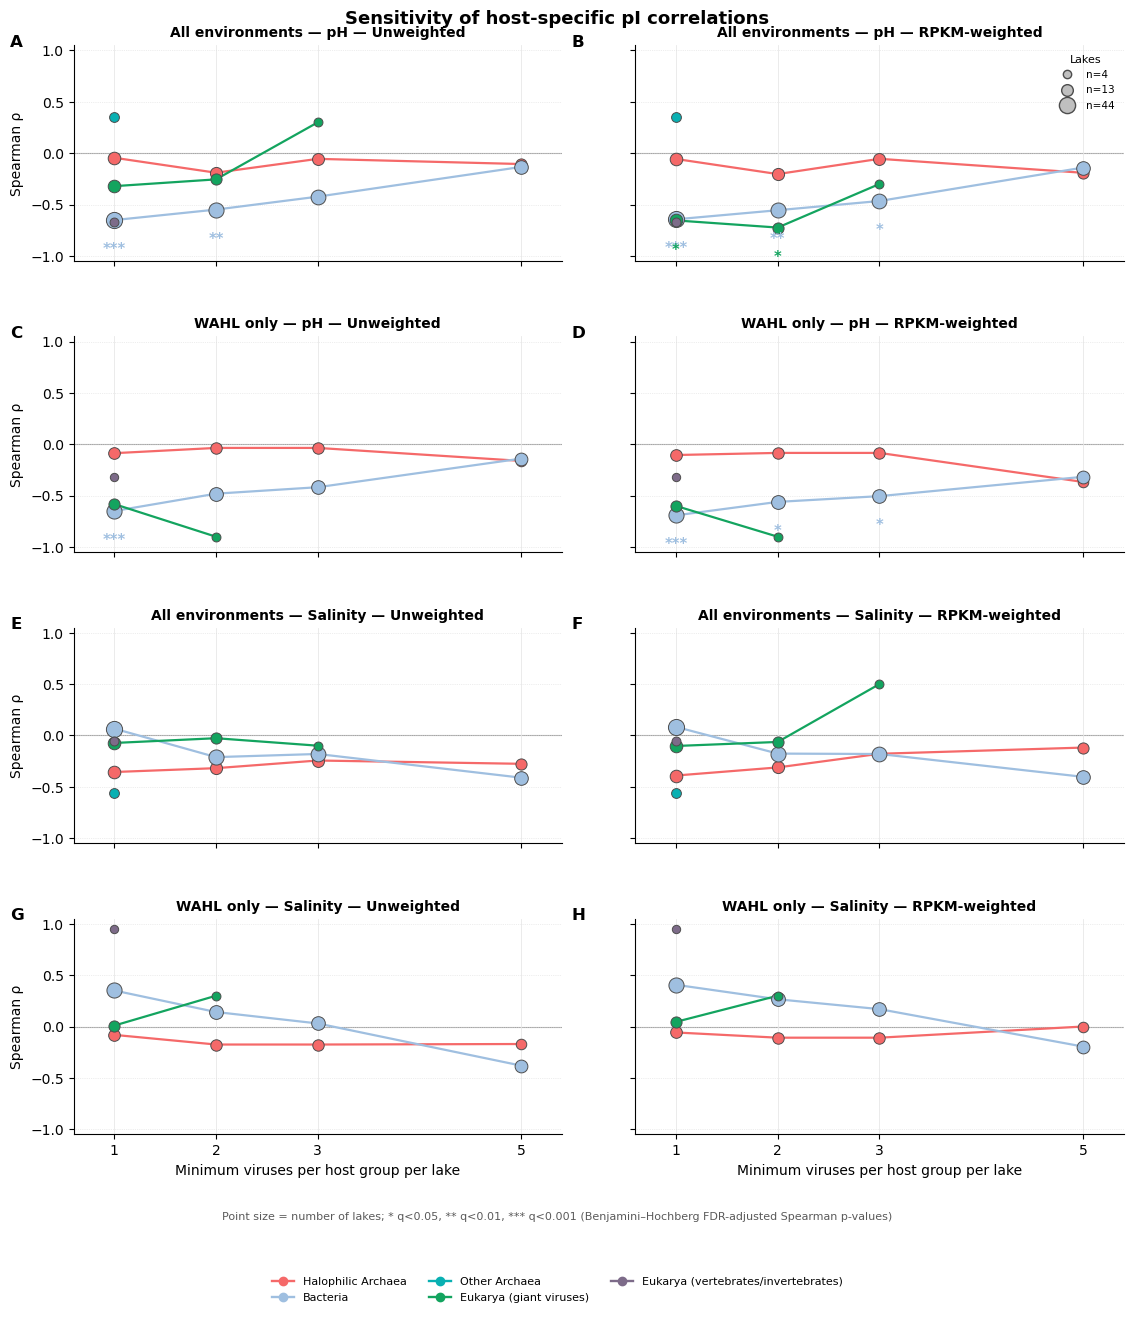


Saved:
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_resolved_hosts_all_and_WAHL_FDR.png
/Users/skoog/Desktop/Revisions/Supplementary_Fig5_resolved_hosts_all_and_WAHL_FDR.svg


In [44]:
# same sweep, resolved hosts only
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D
from IPython.display import display

OUTDIR = "/Users/skoog/Desktop/Revisions/"
os.makedirs(OUTDIR,exist_ok=True)
plt.rcParams.update({"font.family":"DejaVu Sans","svg.fonttype":"none","text.usetex":False})

PICOL,WEIGHT_COL = "Median_pI","rpkm"
THRESHOLDS = (1,2,3,5)
MIN_LAKES_FOR_TEST = 4
SCOPES = ("All environments","WAHL only")
WEIGHTINGS = ("Unweighted median","RPKM-weighted median")

SENS_GROUPS = (
    "Halophilic Archaea",
    "Bacteria",
    "Other Archaea",
    "Eukarya (giant viruses)",
    "Eukarya (vertebrates/invertebrates)"
)
EXCLUDED_GROUPS = {"Bacteria or Archaea","Bacteria and Archaea"}

DEFAULT_HOST_COLORS = {
    "Halophilic Archaea":"#FF6868",
    "Bacteria":"#9FC2E3",
    "Other Archaea":"#11B4B2",
    "Eukarya (giant viruses)":"#12A45D",
    "Eukarya (vertebrates/invertebrates)":"#7D6B89"
}
_existing_palette = globals().get("HOST_COLORS",globals().get("HOST_PALETTE",{}))
HOST_COLORS_SENS = {g:_existing_palette.get(g,DEFAULT_HOST_COLORS[g]) for g in SENS_GROUPS}

def _normalize_host(value):
    value = str(value).strip()
    return {
        "Eukarya (vertebrates/ invertebrates)":"Eukarya (vertebrates/invertebrates)",
        "Eukarya (vertebrates / invertebrates)":"Eukarya (vertebrates/invertebrates)",
        "Thermophilic Archaea":"Other Archaea",
        "Methanogen Archaea":"Other Archaea"
    }.get(value,value)

def _is_true(value):
    if pd.isna(value): return False
    if isinstance(value,(bool,np.bool_)): return bool(value)
    return str(value).strip().lower() in {"true","1","yes","y"}

def _safe_median(values):
    values = pd.to_numeric(pd.Series(values),errors="coerce").dropna().to_numpy(float)
    return float(np.median(values)) if len(values) else np.nan

def _weighted_median(values,weights):
    values,weights = np.asarray(values,float),np.asarray(weights,float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values,weights = values[keep],weights[keep]
    if not len(values): return np.nan
    order = np.argsort(values)
    values,weights = values[order],weights[order]
    cumulative = (np.cumsum(weights)-0.5*weights)/weights.sum()
    return float(np.interp(0.5,cumulative,values))

def _sens_group_iphop(row):
    if not _is_true(row.get("has_iphop",False)): return np.nan

    direct = np.nan
    if callable(globals().get("_host_group_iphop")):
        try: direct = _normalize_host(_host_group_iphop(row))
        except Exception: direct = np.nan

    ecology = _normalize_host(row.get("Host_ecology",row.get("Host_broad","Unknown/Other")))
    existing = _normalize_host(row.get("Host_group","Unknown/Other"))
    domain = str(row.get("host_domain","")).strip()
    phylum = str(row.get("host_phylum","")).strip()

    if direct in EXCLUDED_GROUPS: return np.nan
    if direct in SENS_GROUPS: return direct
    if direct == "Bacteria" or domain == "Bacteria": return "Bacteria"
    if direct in {"Archaea","Other Archaea"} or domain == "Archaea":
        return "Halophilic Archaea" if phylum == "Halobacteriota" else "Other Archaea"
    if direct == "Eukarya" or domain in {"Eukarya","Eukaryota"}:
        if ecology in SENS_GROUPS: return ecology
        if existing in SENS_GROUPS: return existing
        return "Eukarya (giant viruses)"
    return np.nan

def _sens_group_combined(row):
    if _is_true(row.get("has_iphop",False)):
        return _sens_group_iphop(row)

    family = str(row.get("family","")).strip().casefold()
    ecology = _normalize_host(row.get("Host_ecology",row.get("Host_broad","Unknown/Other")))
    existing = _normalize_host(row.get("Host_group","Unknown/Other"))

    if family == "unclassified caudoviricetes": return np.nan
    if ecology in EXCLUDED_GROUPS or existing in EXCLUDED_GROUPS: return np.nan

    if ecology == "Halophilic Archaea": return "Halophilic Archaea"
    if ecology in {"Thermophilic Archaea","Other Archaea","Methanogen Archaea"}: return "Other Archaea"
    if ecology == "Bacteria": return "Bacteria"
    if ecology == "Eukarya (giant viruses)": return "Eukarya (giant viruses)"
    if ecology == "Eukarya (vertebrates/invertebrates)": return "Eukarya (vertebrates/invertebrates)"
    if existing in SENS_GROUPS: return existing
    return np.nan

def _prepare_sensitivity_data(host_df):
    d = host_df.copy()
    required = [PICOL,"pH","Salinity",WEIGHT_COL,"family","has_iphop",
                "Host_group","Environment_Bin","name_full"]
    missing = [c for c in required if c not in d.columns]
    if missing: raise KeyError(f"Missing required columns: {missing}")

    if "Host_ecology" not in d.columns:
        if isinstance(globals().get("host_ecology"),dict):
            d["Host_ecology"] = d["family"].astype(str).str.strip().map(host_ecology).fillna("Unknown/Other")
        elif "Host_broad" in d.columns:
            d["Host_ecology"] = d["Host_broad"]
        else:
            d["Host_ecology"] = "Unknown/Other"

    for c in [PICOL,"pH","Salinity",WEIGHT_COL]:
        d[c] = pd.to_numeric(d[c],errors="coerce")

    d["host_group_sensitivity"] = d.apply(_sens_group_combined,axis=1)
    excluded_n = int(d["host_group_sensitivity"].isna().sum())
    d = d[d["host_group_sensitivity"].isin(SENS_GROUPS)].copy()
    d = d.dropna(subset=[PICOL,"name_full","host_group_sensitivity"])

    # physical lake
    if "physical_lake" in globals():
        _pl = physical_lake
    else:
        import re as _re
        _ALIASES = {"Sunrise Hill": "Sunrise Hill Lake"}
        def _pl(name):
            t = _re.sub(r"\s+", " ", str(name)).strip()
            if "cueva de la mora" in t.lower(): return "Cueva de la Mora"
            return _ALIASES.get(t, t)
    d["Physical_lake"] = d["name_full"].map(_pl)

    id_col = next((c for c in ["contig_id","virus_id","genome_id","sequence_id"] if c in d.columns),None)
    if id_col: d = d.drop_duplicates(subset=[id_col,"Physical_lake"])

    print(f"Rows excluded because host identity was mixed, unresolved, or unsupported: {excluded_n:,}")
    print("\nViruses retained across all environments:")
    print(d["host_group_sensitivity"].value_counts().reindex(SENS_GROUPS,fill_value=0).to_string())
    return d

def _subset_scope(d,scope):
    if scope == "All environments": return d.copy()
    if scope == "WAHL only":
        return d[d["Environment_Bin"].astype(str).str.upper()
                 .str.contains("WATL|WAHL",regex=True,na=False)].copy()
    raise ValueError(f"Unknown scope: {scope}")

def _summarize_host_lakes(d,weighting):
    rows = []
    for (group,lake),g in d.groupby(["host_group_sensitivity","Physical_lake"],sort=False):
        if weighting == "Unweighted median":
            pi = _safe_median(g[PICOL])
        else:
            pi = _weighted_median(g[PICOL].to_numpy(float),g[WEIGHT_COL].to_numpy(float))

        rows.append({
            "host_group":group,
            "name_full":lake,
            "weighting":weighting,
            "pI":pi,
            "pH":float(g.drop_duplicates("name_full")["pH"].mean()),
            "Salinity":float(g.drop_duplicates("name_full")["Salinity"].mean()),
            "n_viruses":int(len(g)),
            "total_RPKM":float(g[WEIGHT_COL].where(g[WEIGHT_COL] > 0).sum())
        })

    out = pd.DataFrame(rows)
    return out.dropna(subset=["pI"]).reset_index(drop=True) if len(out) else out

def build_sensitivity_sweep(host_df):
    prepared = _prepare_sensitivity_data(host_df)
    test_rows,lake_frames = [],[]

    for scope in SCOPES:
        scoped = _subset_scope(prepared,scope)

        print(f"\n{scope} — lakes represented by host group:")
        print(scoped.groupby("host_group_sensitivity")["Physical_lake"].nunique()
              .reindex(SENS_GROUPS,fill_value=0).to_string())

        for weighting in WEIGHTINGS:
            lake_all = _summarize_host_lakes(scoped,weighting)
            if lake_all.empty: continue

            lake_all.insert(0,"scope",scope)
            lake_all.insert(1,"scheme","iPHoP-prioritized + family-inferred; resolved hosts only")

            for threshold in THRESHOLDS:
                lake_all[f"eligible_n{threshold}"] = lake_all["n_viruses"] >= threshold
            lake_frames.append(lake_all)

            for threshold in THRESHOLDS:
                eligible = lake_all[lake_all["n_viruses"] >= threshold]

                for group in SENS_GROUPS:
                    group_data = eligible[eligible["host_group"] == group]

                    for predictor in ("pH","Salinity"):
                        test = group_data.dropna(subset=["pI",predictor])
                        n_lakes,rho,p_raw = len(test),np.nan,np.nan

                        if n_lakes >= MIN_LAKES_FOR_TEST and test["pI"].nunique() > 1 and test[predictor].nunique() > 1:
                            result = spearmanr(test["pI"].to_numpy(float),test[predictor].to_numpy(float))
                            rho,p_raw = float(result.statistic),float(result.pvalue)

                        test_rows.append({
                            "scope":scope,
                            "scheme":"iPHoP-prioritized + family-inferred; resolved hosts only",
                            "weighting":weighting,
                            "threshold":threshold,
                            "host_group":group,
                            "predictor":predictor,
                            "n_lakes":int(n_lakes),
                            "n_viruses_total":int(test["n_viruses"].sum()) if n_lakes else 0,
                            "minimum_viruses_per_lake":int(test["n_viruses"].min()) if n_lakes else np.nan,
                            "median_viruses_per_lake":float(test["n_viruses"].median()) if n_lakes else np.nan,
                            "maximum_viruses_per_lake":int(test["n_viruses"].max()) if n_lakes else np.nan,
                            "lake_virus_counts":"; ".join(
                                f"{r.name_full}:{int(r.n_viruses)}"
                                for r in test.sort_values("name_full").itertuples()
                            ),
                            "rho":rho,
                            "p_raw":p_raw
                        })

    tests = pd.DataFrame(test_rows)
    lakes = pd.concat(lake_frames,ignore_index=True) if lake_frames else pd.DataFrame()
    tests["q_fdr"] = np.nan

    # BH within panel and threshold
    for _,idx in tests.groupby(["scope","weighting","threshold","predictor"]).groups.items():
        idx = np.asarray(list(idx),int)
        p = tests.loc[idx,"p_raw"].to_numpy(float)
        valid = np.isfinite(p)
        if valid.any():
            tests.loc[idx[valid],"q_fdr"] = multipletests(p[valid],method="fdr_bh")[1]

    test_csv = os.path.join(OUTDIR,"Supplementary_Fig5_resolved_host_sensitivity_tests.csv")
    lake_csv = os.path.join(OUTDIR,"Supplementary_Fig5_resolved_host_sensitivity_lake_inputs.csv")
    xlsx = os.path.join(OUTDIR,"Supplementary_Fig5_resolved_host_sensitivity.xlsx")

    tests.to_csv(test_csv,index=False)
    lakes.to_csv(lake_csv,index=False)

    with pd.ExcelWriter(xlsx,engine="openpyxl") as writer:
        tests.to_excel(writer,sheet_name="sensitivity_tests",index=False)
        lakes.to_excel(writer,sheet_name="lake_level_inputs",index=False)
        tests[tests["scope"] == "All environments"].to_excel(
            writer,sheet_name="all_environment_tests",index=False
        )
        tests[tests["scope"] == "WAHL only"].to_excel(
            writer,sheet_name="WAHL_tests",index=False
        )

    display(
        tests[["scope","weighting","threshold","host_group","predictor",
               "n_lakes","n_viruses_total","rho","p_raw","q_fdr"]]
        .sort_values(["scope","predictor","weighting","host_group","threshold"])
        .round(4)
    )

    print("\nSaved:")
    print(test_csv)
    print(lake_csv)
    print(xlsx)
    return tests,lakes

def _q_stars(q):
    if pd.isna(q): return ""
    if q < 0.001: return "***"
    if q < 0.01: return "**"
    if q < 0.05: return "*"
    return ""

def plot_sensitivity_sweep(tests,out_stem):
    plot_data = tests.copy()
    valid_n = plot_data.loc[
        plot_data["rho"].notna() & (plot_data["n_lakes"] > 0),"n_lakes"
    ].to_numpy(float)

    n_min = int(np.nanmin(valid_n)) if len(valid_n) else 1
    n_max = int(np.nanmax(valid_n)) if len(valid_n) else 1

    def point_size(n):
        if n_max <= n_min: return 65
        scaled = (np.sqrt(float(n))-np.sqrt(n_min))/(np.sqrt(n_max)-np.sqrt(n_min))
        return 36+100*scaled

    specs = [
        ("All environments","pH","Unweighted median"),
        ("All environments","pH","RPKM-weighted median"),
        ("WAHL only","pH","Unweighted median"),
        ("WAHL only","pH","RPKM-weighted median"),
        ("All environments","Salinity","Unweighted median"),
        ("All environments","Salinity","RPKM-weighted median"),
        ("WAHL only","Salinity","Unweighted median"),
        ("WAHL only","Salinity","RPKM-weighted median")
    ]

    fig,axes = plt.subplots(4,2,figsize=(11.8,13.2),sharex=True,sharey=True)

    for panel_letter,(ax,(scope,predictor,weighting)) in enumerate(zip(axes.flat,specs)):
        panel = plot_data[
            (plot_data["scope"] == scope) &
            (plot_data["predictor"] == predictor) &
            (plot_data["weighting"] == weighting)
        ]

        ax.axhline(0,color="0.65",lw=0.8,zorder=0)
        for threshold in THRESHOLDS:
            ax.axvline(threshold,color="0.91",lw=0.6,zorder=0)

        for group in SENS_GROUPS:
            g = panel[panel["host_group"] == group].sort_values("threshold").dropna(subset=["rho"])
            if g.empty: continue

            x = g["threshold"].to_numpy(float)
            y = g["rho"].to_numpy(float)
            color = HOST_COLORS_SENS[group]
            ax.plot(x,y,color=color,lw=1.6,zorder=2)

            for r in g.itertuples():
                ax.scatter(float(r.threshold),float(r.rho),s=point_size(r.n_lakes),
                           marker="o",facecolor=color,edgecolor="0.3",lw=0.7,zorder=4)

                stars = _q_stars(r.q_fdr)
                if stars:
                    offset = 8 if r.rho >= 0 else -15
                    va = "bottom" if r.rho >= 0 else "top"
                    ax.annotate(stars,(float(r.threshold),float(r.rho)),xytext=(0,offset),
                                textcoords="offset points",ha="center",va=va,fontsize=10.5,
                                fontweight="bold",color=color,clip_on=False,zorder=6)

        ax.text(-0.13,1.05,chr(65+panel_letter),transform=ax.transAxes,
                fontsize=12,fontweight="bold",va="top")
        ax.set_title(f"{scope} — {predictor} — {weighting.replace(' median','')}",
                     fontsize=10,fontweight="bold")
        ax.set_xticks(THRESHOLDS)
        ax.set_xlim(0.6,5.4)
        ax.set_ylim(-1.05,1.05)
        ax.grid(axis="y",ls=":",lw=0.5,color="0.87")
        ax.set_axisbelow(True)
        for spine in ("top","right"): ax.spines[spine].set_visible(False)

    for row in range(4):
        axes[row,0].set_ylabel("Spearman ρ")

    axes[3,0].set_xlabel("Minimum viruses per host group per lake")
    axes[3,1].set_xlabel("Minimum viruses per host group per lake")

    host_handles = [
        Line2D([],[],color=HOST_COLORS_SENS[g],marker="o",lw=1.7,ms=6,label=g)
        for g in SENS_GROUPS
    ]
    fig.legend(handles=host_handles,loc="lower center",ncol=3,frameon=False,
               fontsize=8,bbox_to_anchor=(0.5,0.005))

    if len(valid_n):
        refs = sorted(set([
            int(np.nanmin(valid_n)),
            int(np.nanmedian(valid_n)),
            int(np.nanmax(valid_n))
        ]))
        axes[0,1].legend(
            handles=[
                Line2D([],[],marker="o",ls="None",markersize=np.sqrt(point_size(n)),
                       markerfacecolor="0.75",markeredgecolor="0.3",label=f"n={n}")
                for n in refs
            ],
            title="Lakes",loc="upper right",frameon=False,
            fontsize=7.5,title_fontsize=8
        )

    fig.suptitle("Sensitivity of host-specific pI correlations",
                 fontsize=13,fontweight="bold",y=0.992)
    fig.text(
        0.5,0.075,
        "Point size = number of lakes; * q<0.05, ** q<0.01, *** q<0.001 "
        "(Benjamini–Hochberg FDR-adjusted Spearman p-values)",
        ha="center",fontsize=8,color="0.35"
    )
    fig.subplots_adjust(left=0.09,right=0.98,top=0.965,bottom=0.14,
                        wspace=0.15,hspace=0.35)

    png_path = out_stem+".png"
    svg_path = out_stem+".svg"
    fig.savefig(png_path,dpi=300,bbox_inches="tight")
    fig.savefig(svg_path,format="svg",bbox_inches="tight")
    plt.show()

    print("\nSaved:")
    print(png_path)
    print(svg_path)

host_sensitivity_resolved,host_sensitivity_lake_inputs = build_sensitivity_sweep(host_df_all)

plot_sensitivity_sweep(
    host_sensitivity_resolved,
    os.path.join(OUTDIR,"Supplementary_Fig5_resolved_hosts_all_and_WAHL_FDR")
)